# 오토인코더-2 · 노이즈 제거 · 평가 · 이상 탐지

**한 줄 요약** · 손상된 입력을 깨끗하게 되돌리는 Denoising AE를 만들고, 복원이 잘됐는지 기준선 · 중요한 부분 · 그림으로 판단하며, 복원 오차로 이상을 찾음

## 🎯 학습 목표

이 노트북을 끝내면 **자료를 보지 않고** 다음을 할 수 있어야 함

1. 일반 AE와 Denoising AE의 차이(입력만 망가뜨림)를 설명하고 손상 세기 · 종류에 맞춰 학습한다
2. 문서 복원에서 짝 · 학습/평가 분리 · 문서 크기를 직접 확인하고 맞춘다
3. 복원 점수를 기준선 옆에 놓고, 글자 칸처럼 중요한 부분과 그림으로 함께 판단한다
4. 요인 하나만 바꾸고 seed 흔들림과 비교해 개선 효과를 말한다
5. 정상만 배운 오토인코더의 복원 오차로 이상을 찾고 임곗값을 정밀도 · 재현율로 고른다

## 어디에 쓰나

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">실제 상황</th>
<th style="text-align: left;">이 권에서 배우는 것</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;">습기 · 얼룩 · 찢김으로 손상된 문서를 복원할 때 (미션 5)</td>
<td style="text-align: left;">입력만 망가뜨리는 DAE · 짝 · 크기 맞추기 (1 · 2장)</td>
</tr>
<tr>
<td style="text-align: left;">복원 모델의 점수가 좋은지 판단할 때</td>
<td style="text-align: left;">기준선 · RMSE · PSNR · 글자 칸 (3장)</td>
</tr>
<tr>
<td style="text-align: left;">설정을 바꿔 성능을 올렸다고 보고할 때</td>
<td style="text-align: left;">하나만 바꾸기 · seed 흔들림 (4장)</td>
</tr>
<tr>
<td style="text-align: left;">불량품 · 심전도처럼 정상 데이터만 많을 때</td>
<td style="text-align: left;">복원 오차 이상 탐지 · 임곗값 (5장 · 보강)</td>
</tr>
</tbody>
</table>

## 학습 지도

<img src="images/ae2_map.png" alt="오토인코더-2 학습 지도" width="837">

**예상 학습 시간** · 개념 2시간 30분 + 실습 1시간 (GPU 약 1분 · CPU 몇 분이면 전체 학습이 끝남)

## 목차

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: center;">장</th>
<th style="text-align: left;">제목</th>
<th style="text-align: left;">이 장의 질문</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: center;">0</td>
<td style="text-align: left;">준비</td>
<td style="text-align: left;">라이브러리 · seed · 장치 · MNIST · 모델 · 학습 함수 · 평가 노이즈</td>
</tr>
<tr>
<td style="text-align: center;">1</td>
<td style="text-align: left;">노이즈 제거</td>
<td style="text-align: left;">손상된 입력을 되돌리려면 학습에서 무엇을 바꾸는가?</td>
</tr>
<tr>
<td style="text-align: center;">2</td>
<td style="text-align: left;">문서 복원과 짝</td>
<td style="text-align: left;">짝 · 학습/평가 분리 · 문서 크기는 무엇으로 확인하는가?</td>
</tr>
<tr>
<td style="text-align: center;">3</td>
<td style="text-align: left;">복원 평가</td>
<td style="text-align: left;">복원이 잘됐는지 무엇과 비교하고 어디를 따로 재는가?</td>
</tr>
<tr>
<td style="text-align: center;">4</td>
<td style="text-align: left;">실험 설계</td>
<td style="text-align: left;">무엇 때문에 좋아졌는지 말하려면 어떻게 실험하는가?</td>
</tr>
<tr>
<td style="text-align: center;">5</td>
<td style="text-align: left;">이상 탐지 (보강)</td>
<td style="text-align: left;">정상만 배운 모델로 이상을 찾고 임곗값을 어떻게 정하는가?</td>
</tr>
<tr>
<td style="text-align: center;">6</td>
<td style="text-align: left;">종합 실습</td>
<td style="text-align: left;">노이즈 세기 3단계 DAE와 임곗값별 이상 탐지 결과는?</td>
</tr>
<tr>
<td style="text-align: center;">—</td>
<td style="text-align: left;">마무리 · 부록</td>
<td style="text-align: left;">오늘 배운 것 · 기억 확인 · 오답 노트 · 면접 · 요약표 · 복습일 · 원본 대응표 · 전체 코드</td>
</tr>
</tbody>
</table>

---
## 0. 준비

- 라이브러리 · seed · 장치 · MNIST · 모델 · 학습 함수 · 도구.
- 모델과 학습 루프는 오토인코더-1과 같고, 학습 함수에 **손실 함수(`loss_fn`)를 넘기는 자리**만 추가
- 1장에서 입력을 무엇으로 망가뜨릴지를 이 자리로 바꿈.

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">이름</th>
<th style="text-align: left;">하는 일</th>
<th style="text-align: left;">쓰는 곳</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;"><code>AutoEncoder</code></td>
<td style="text-align: left;">784 → 128 → 32 → 128 → 784 (오토인코더-1 1-2)</td>
<td style="text-align: left;">1장 · 5장 · 6장</td>
</tr>
<tr>
<td style="text-align: left;"><code>train(model, X, loss_fn)</code></td>
<td style="text-align: left;">128장씩 · 10 epoch · <code>loss_fn(model, x)</code>로 손실 계산</td>
<td style="text-align: left;">1장 · 5장 · 6장</td>
</tr>
<tr>
<td style="text-align: left;"><code>ae_loss</code></td>
<td style="text-align: left;">입력 x · 정답 x (일반 AE)</td>
<td style="text-align: left;">1-1 · 5장</td>
</tr>
<tr>
<td style="text-align: left;"><code>run</code> · <code>mse</code> · <code>show</code></td>
<td style="text-align: left;">복원 모으기 · 평가 MSE · 8장 나란히 (오토인코더-1과 같음)</td>
<td style="text-align: left;">전체</td>
</tr>
<tr>
<td style="text-align: left;"><code>noisy_eval(s)</code></td>
<td style="text-align: left;">평가 1만 장에 세기 s 노이즈를 <strong>한 번만</strong> (CPU 난수 seed 999)</td>
<td style="text-align: left;">1장 · 6장</td>
</tr>
</tbody>
</table>

In [1]:
# 라이브러리 불러오기
import PIL.Image                                        # 연습용 문서 그리기 (2장)
from PIL import ImageDraw, ImageFont                    # 2장 연습용 문서 그리기
import numpy as np                                      # 문서 이미지 배열 · 난수
import torch                                            # 텐서 · 자동 미분
import torch.nn as nn                                   # 층: Linear · Conv2d
import torch.nn.functional as F                         # 함수: mse_loss
import matplotlib.pyplot as plt                         # 복원 그림 · 분포 그림
from torchvision import datasets                        # MNIST 내려받기
from sklearn.metrics import confusion_matrix, f1_score  # 5 · 6장 이상 탐지 채점


# 재현성 · 장치: seed 고정 → 늘 같은 결과, GPU 없으면 CPU
torch.manual_seed(0)                                     # 난수 기준값 고정 → 매번 같은 결과
torch.backends.cudnn.deterministic = True                # GPU 계산도 매번 같게
torch.backends.cudnn.benchmark = False                   # 실행마다 계산 방법이 바뀌지 않게
device = "cuda" if torch.cuda.is_available() else "cpu"  # 쓸 장치 고르기
print("장치:", device)                                   # cuda인지 cpu인지 확인


# MNIST: 학습 1만 장 · 평가 1만 장 (오토인코더-1과 같음)
tr = datasets.MNIST("data", train=True, download=True)          # 학습용 6만 장 (처음 한 번만 받음)
te = datasets.MNIST("data", train=False, download=True)         # 평가용 1만 장
Xtr = tr.data[:10000].float().div(255).unsqueeze(1).to(device)  # 앞 1만 장 · 0~1 · 채널 축
Xte = te.data.float().div(255).unsqueeze(1).to(device)          # 평가 1만 장 전체
yte = te.targets                                                # 평가 라벨 · 5장 이상 탐지 채점용
print("학습", tuple(Xtr.shape), "| 평가", tuple(Xte.shape))     # (장, 1, 28, 28) 확인

장치: cuda
학습 (10000, 1, 28, 28) | 평가 (10000, 1, 28, 28)


In [2]:
# 모델 · 학습 함수 (구조 설명은 오토인코더-1 1-2 · 1-3)
class AutoEncoder(nn.Module):           # 오토인코더-1 1-2와 같은 모델
    def __init__(self, latent_dim=32):  # 잠재 크기를 인자로
        super().__init__()              # 부모 초기화
        self.encoder = nn.Sequential(   # 784 → 128 → 32
            nn.Flatten(), nn.Linear(784, 128), nn.ReLU(),
            nn.Linear(128, latent_dim))
        self.decoder = nn.Sequential(   # 32 → 128 → 784 → 0~1
            nn.Linear(latent_dim, 128), nn.ReLU(),
            nn.Linear(128, 784), nn.Sigmoid())

    def forward(self, x):                                            # model(x)의 길
        return self.decoder(self.encoder(x)).reshape(-1, 1, 28, 28)  # 줄였다 되돌려 그림 모양


def ae_loss(model, x):              # 일반 AE: 입력 x · 정답 x
    return F.mse_loss(model(x), x)  # 정답 자리에도 x


def train(model, X=None, loss_fn=ae_loss, epochs=10, seed=0):      # 손실 함수만 바꿔 끼움
    X = Xtr if X is None else X                                    # 안 주면 학습 1만 장
    torch.manual_seed(seed)                                        # 섞는 순서 · 노이즈 고정
    opt = torch.optim.Adam(model.parameters(), lr=1e-3)            # 모든 가중치를 고침
    for epoch in range(epochs):                                    # 전체를 epochs번
        model.train()                                              # 학습 모드
        perm = torch.randperm(len(X), device=device)               # 번호 섞기
        for i in range(0, len(X), 128):                            # 128장씩
            x = X[perm[i:i + 128]]                                 # 깨끗한 묶음
            opt.zero_grad()                                        # 앞 묶음 기울기 비우기
            loss = loss_fn(model, x)                               # 무엇을 넣고 무엇과 비교할지
            loss.backward()                                        # 기울기 계산
            opt.step()                                             # 가중치 갱신
        if epoch in (0, epochs // 2 - 1, epochs - 1):              # 1 · 중간 · 끝만
            print(f"  epoch {epoch + 1}  loss {loss.item():.4f}")  # 마지막 묶음의 loss
    return model                                                   # 학습된 모델

In [3]:
# 도구: 복원 모으기 · 평가 MSE · 8장 나란히 (오토인코더-1과 같음)
@torch.no_grad()
def run(model, X):  # 모델 + 이미지 묶음 → 복원 묶음
    model.eval()    # 평가 모드
    # 2,000장씩 → 이어 붙임
    return torch.cat([model(X[i:i + 2000]) for i in range(0, len(X), 2000)])


def mse(A, ref=None):                                         # 복원 묶음 → 숫자 하나
    return F.mse_loss(A, Xte if ref is None else ref).item()  # 기본은 평가 1만 장 원본


SHOW = [5459, 9898, 926, 1150, 5691, 2400, 7792, 950]  # 숫자 0~7


def show(rows):  # rows = [(줄 이름, 이미지 묶음), …]
    fig, axes = plt.subplots(len(rows), 8, figsize=(8, 1.15 * len(rows)))  # 줄 수 × 8칸
    for r, (name, X) in enumerate(rows):                                   # 줄마다
        for c in range(8):                                                 # 같은 8장
            img = X[SHOW[c], 0].detach().cpu()                             # GPU → CPU (그림용)
            axes[r, c].imshow(img, cmap="gray", vmin=0, vmax=1)            # 밝기 0~1 고정
            axes[r, c].axis("off")                                         # 눈금 숨김
        axes[r, 0].set_title(name, loc="left", fontsize=10)                # 줄 이름
    plt.tight_layout()                                                     # 간격 정리
    plt.show()                                                             # 그림 출력


# 평가용 노이즈: CPU 난수(seed 999)로 한 번만 → 장치가 달라도 같은 노이즈
def noisy_eval(s, seed=999):                                       # 세기 s 평가 노이즈
    g = torch.Generator().manual_seed(seed)                        # 이 함수만 쓰는 난수
    noise = torch.randn(tuple(Xte.shape), generator=g).to(device)  # CPU에서 만들고 장치로
    return (Xte + s * noise).clamp(0, 1)                           # 0~1 밖은 자름

---
## 1. 노이즈 제거

> **이 장의 흐름**
>
> - 오토인코더-1은 깨끗한 입력을 그대로 되돌렸다
> - 입력이 더러우면? 정답은 깨끗한 원본으로 두고 입력만 망가뜨리면 모델이 하는 일이 '복원'에서 '청소'로 바뀜

**파이프라인 위치** · ① 데이터 준비 · ③ 학습 · ④ 평가 — 손상 입력 만들기, 입력만 바꾼 학습, 같은 시험지로 비교

### 1-1. `A` 깨끗한 숫자만 배운 모델에 노이즈 · `torch.randn_like` · `clamp(0, 1)` <sub>day02 p1–15</sub>

> 🎯 **깨끗한 숫자로만 배운 오토인코더에 노이즈 낀 숫자를 넣으면 무엇이 나오는가?**

💡 **쉽게 말하면**

- 깨끗한 글씨만 따라 써 본 사람에게 **얼룩진 글씨**를 주면, 얼룩까지 글씨의 일부인지 몰라 어정쩡하게 따라 씀.

**실행 흐름**

1. AE 학습 (오토인코더-1 1-3과 같은 조건)
2. 평가 1만 장에 세기 0.3 노이즈 (CPU 난수 seed 999)
3. MSE 세 가지
4. 그림 3줄

**먼저 예측** · 노이즈 입력을 깨끗한 숫자만 배운 AE에 넣으면 노이즈가 지워질까? — 답은 코드 실행 결과 아래에

  epoch 1  loss 0.0650


  epoch 5  loss 0.0302


  epoch 10  loss 0.0147
값 범위 0.0 ~ 1.0 (clamp)
깨끗한 입력 → AE   MSE 0.0191
노이즈 입력 그대로  MSE 0.0466
노이즈 입력 → AE   MSE 0.0306


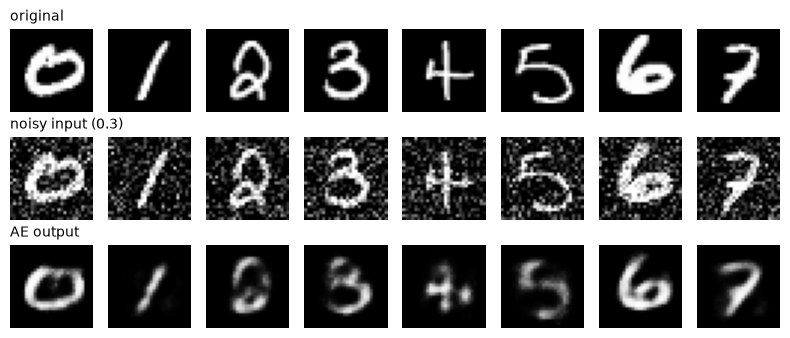

In [4]:
# 어제 모델: 깨끗한 숫자만 배운 AE (오토인코더-1 1-3과 같은 조건)
torch.manual_seed(0)                    # 오토인코더-1 1-3과 같은 출발점
ae = train(AutoEncoder(32).to(device))  # 깨끗한 숫자만 배운 AE


# 평가 1만 장에 세기 0.3 노이즈를 한 번 입힘
Xn = noisy_eval(0.3)                                                     # 모든 모델이 같은 시험지
print(f"값 범위 {Xn.min().item():.1f} ~ {Xn.max().item():.1f} (clamp)")  # 0~1 안인지


# 깨끗한 입력 · 노이즈 입력 그대로 · 노이즈 입력 → AE
print(f"깨끗한 입력 → AE   MSE {mse(run(ae, Xte)):.4f}")  # 어제 모델 기준
print(f"노이즈 입력 그대로  MSE {mse(Xn):.4f}")           # 아무것도 안 한 점수
print(f"노이즈 입력 → AE   MSE {mse(run(ae, Xn)):.4f}")   # 노이즈를 넣으면
show([("original", Xte), ("noisy input (0.3)", Xn),       # 원본 · 노이즈 · 복원
      ("AE output", run(ae, Xn))])

**결과** · 예측 정답은 일부만

- MSE 0.0466 → 0.0306으로 줄지만 깨끗한 입력(0.0191)만큼은 아님
- 그림 셋째 줄은 배경이 깨끗해졌지만 숫자가 흐리고 2 · 4 · 5가 뭉개짐
- `깨끗한 입력 → AE MSE 0.0191` — 오토인코더-1 1-3과 같은 값 = 같은 조건 · 같은 seed라 같은 모델
- `노이즈 입력 그대로 MSE 0.0466` — 아무것도 안 했을 때의 점수 (기준선)
- `노이즈 입력 → AE MSE 0.0306` — 좁은 통로가 노이즈 일부를 걸러 줌 · 노이즈를 지우는 연습은 한 적 없음

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">방법</th>
<th style="text-align: left;">차이</th>
<th style="text-align: left;">언제 쓰나</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;"><code>torch.randn_like(x)</code></td>
<td style="text-align: left;">x와 같은 모양 · 평균 0 · 표준편차 1 가우시안</td>
<td style="text-align: left;">학습 중 묶음마다 새 노이즈를 만들 때</td>
</tr>
<tr>
<td style="text-align: left;"><code>torch.randn(shape, generator=g)</code></td>
<td style="text-align: left;">전용 난수 · CPU에서 만들어 장치와 상관없이 같은 값</td>
<td style="text-align: left;">평가용 노이즈를 한 번 고정할 때</td>
</tr>
<tr>
<td style="text-align: left;"><code>.clamp(0, 1)</code></td>
<td style="text-align: left;">0보다 작으면 0 · 1보다 크면 1</td>
<td style="text-align: left;">노이즈를 더한 뒤 픽셀 범위로 되돌릴 때</td>
</tr>
</tbody>
</table>

> ⚠️ **주의**
>
> - 평가 노이즈를 모델마다 새로 뽑으면 서로 다른 시험지를 푸는 셈
> - seed로 한 번 만들어 모든 모델에 같이 씀

> ✅ **한 줄 정리** · 깨끗한 숫자만 배운 오토인코더는 노이즈를 조금 줄이지만, 지우는 연습을 한 적이 없어 깨끗한 입력만큼 복원하지 못한다.

**딥러닝 코드에서는**

- 학습 데이터와 실제 입력의 상태가 다르면(분포 차이) 성능이 떨어짐
- 실제에 가까운 손상을 학습에 넣는 데이터 증강
- DAE의 출발점

### 1-2. `A` Denoising AE · 입력만 바꾸기 · `F.mse_loss(model(noisy), x)` <sub>day02 p16–31 · P5</sub>

> 🎯 **노이즈를 지우게 하려면 학습 루프에서 무엇을 바꾸는가?**

💡 **쉽게 말하면**

- 얼룩진 글씨를 보여 주고 **깨끗한 글씨로 답하게** 연습시키면 얼룩 지우는 법을 배움.
- 구조는 그대로, 문제(입력)와 답(정답)의 짝만 바뀜.

<img src="images/ae2_dae.png" alt="일반 AE와 DAE는 입력만 다름" width="837">

**실행 흐름**

1. dae_loss (P5 빈칸 두 줄)
2. 같은 구조 · 조건으로 학습
3. 같은 노이즈 · 같은 깨끗한 입력으로 AE와 비교
4. 그림 4줄

**먼저 예측** · DAE에 노이즈 없는 깨끗한 숫자를 넣으면 AE보다 나을까? — 답은 코드 실행 결과 아래에

  epoch 1  loss 0.0661


  epoch 5  loss 0.0332


  epoch 10  loss 0.0209
노이즈 입력 → AE   MSE 0.0306
노이즈 입력 → DAE  MSE 0.0250
깨끗한 입력 → AE   MSE 0.0191
깨끗한 입력 → DAE  MSE 0.0445


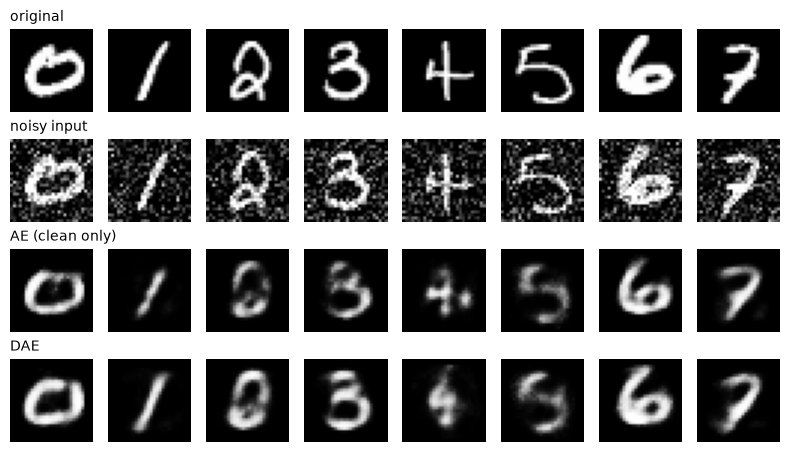

In [5]:
# P5 빈칸 정답: 입력은 노이즈 낀 숫자 · 정답은 깨끗한 숫자
def dae_loss(model, x, s=0.3):                         # 손실 함수만 바꿔 train에 넘김
    noisy = (x + s * torch.randn_like(x)).clamp(0, 1)  # (a) 묶음마다 새 노이즈
    return F.mse_loss(model(noisy), x)                 # (b) model(noisy) ↔ 깨끗한 x


# 구조 · 조건은 AE와 같고 손실 함수만 다름
torch.manual_seed(0)                                       # AE와 같은 출발점
dae = train(AutoEncoder(32).to(device), loss_fn=dae_loss)  # 구조 · 조건 같음


# 같은 노이즈 입력 · 같은 깨끗한 입력으로 AE와 비교
print(f"노이즈 입력 → AE   MSE {mse(run(ae, Xn)):.4f}")    # 같은 노이즈 시험지
print(f"노이즈 입력 → DAE  MSE {mse(run(dae, Xn)):.4f}")   # 같은 노이즈 시험지
print(f"깨끗한 입력 → AE   MSE {mse(run(ae, Xte)):.4f}")   # 깨끗한 입력도 비교
print(f"깨끗한 입력 → DAE  MSE {mse(run(dae, Xte)):.4f}")  # 연습 안 한 입력
show([("original", Xte), ("noisy input", Xn),              # 4줄 나란히
      ("AE (clean only)", run(ae, Xn)), ("DAE", run(dae, Xn))])

**결과** · 예측 정답은 못함

- 깨끗한 입력 MSE는 AE 0.0191
- DAE 0.0445 (이번 실행)
- 대신 노이즈 입력에서는 DAE가 나음 (MSE 0.0056 작음 · 그림 셋째 · 넷째 줄은 눈으로는 차이가 크지 않음)
- `노이즈 입력 → AE MSE 0.0306` — 1-1과 같은 값
- `노이즈 입력 → DAE MSE 0.0250` — 노이즈를 지우는 연습을 한 DAE가 더 가까움
- `깨끗한 입력 → AE MSE 0.0191` — 깨끗한 입력엔 AE가 가장 정확
- `깨끗한 입력 → DAE MSE 0.0445` — 연습한 적 없는 깨끗한 입력에는 오히려 나쁨 = DAE의 대가

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">방법</th>
<th style="text-align: left;">차이</th>
<th style="text-align: left;">언제 쓰나</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;">일반 AE</td>
<td style="text-align: left;">입력 x · 정답 x</td>
<td style="text-align: left;">깨끗한 데이터의 압축 · 특징 · 이상 탐지 (5장)</td>
</tr>
<tr>
<td style="text-align: left;">Denoising AE</td>
<td style="text-align: left;">입력 <strong>망가뜨린 x</strong> · 정답 깨끗한 x · 구조는 같음</td>
<td style="text-align: left;">실제 입력이 손상돼 들어올 때 (노이즈 제거 · 문서 복원)</td>
</tr>
<tr>
<td style="text-align: left;">정답 자리에 noisy (틀림)</td>
<td style="text-align: left;">입력 = 정답 → 노이즈까지 그대로 되돌리는 연습</td>
<td style="text-align: left;">쓰면 안 됨 (P5 확인 셀의 [안내])</td>
</tr>
</tbody>
</table>

> ⚠️ **주의**
>
> - 노이즈는 **묶음마다 새로** 뽑음 (`randn_like`가 루프 안 손실 함수에)
> - 한 번 만든 노이즈를 계속 쓰면 그 노이즈 모양을 외움

> ✅ **한 줄 정리** · Denoising AE는 구조는 그대로 두고 입력만 망가뜨린 숫자로, 정답은 깨끗한 원본으로 두어 손상을 지우는 법을 배우게 한다.

**딥러닝 코드에서는**

- 미션의 문서 복원이 바로 이 짝(손상 문서 → 깨끗한 문서)
- 2장에서 문서 이미지로 이어짐

### 1-3. `A` 노이즈 세기 약하게 vs 강하게 · `noisy_eval(s)` <sub>day02 p9–11 · 보강</sub>

> 🎯 **학습 때와 다른 세기의 노이즈가 들어오면 DAE는 어떻게 되는가?**

💡 **쉽게 말하면**

- 비 오는 날 사진만 보정 연습한 사람에게 **이슬비 사진**과 **폭우 사진**을 주는 것.
- 너무 약하면 괜히 고쳐 망치고, 너무 세면 감당을 못 함.

**실행 흐름**

1. 세기 0.1 · 0.3 · 0.6 평가 노이즈
2. 노이즈 그대로 · AE · DAE(0.3) MSE
3. 그림 (학습 없음)

**먼저 예측** · 약한 노이즈 0.1에서 DAE(0.3)는 노이즈 입력 그대로보다 나을까? — 답은 코드 실행 결과 아래에

세기 0.1 | 노이즈 그대로 0.0054 | AE 0.0203 | DAE(0.3) 0.0376
세기 0.3 | 노이즈 그대로 0.0466 | AE 0.0306 | DAE(0.3) 0.0250
세기 0.6 | 노이즈 그대로 0.1502 | AE 0.0562 | DAE(0.3) 0.0698


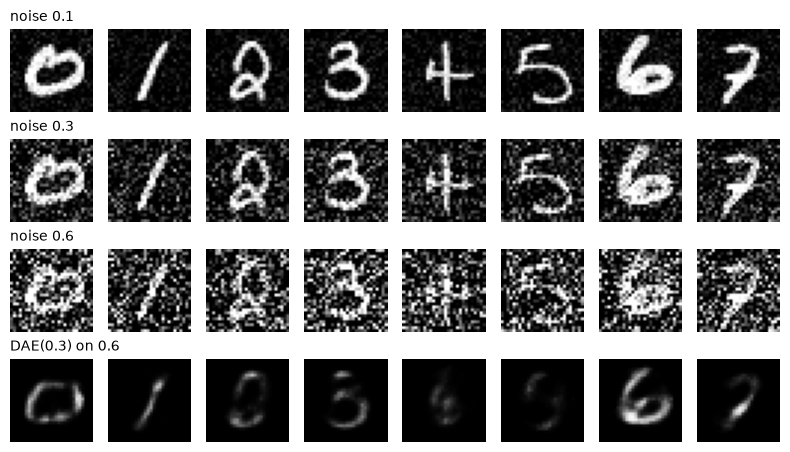

In [6]:
# 노이즈 세기 세 가지 (학습 없음 · 1-2의 DAE는 0.3으로만 배움)
for s in [0.1, 0.3, 0.6]:                            # 약하게 · 중간 · 강하게
    Xs = noisy_eval(s)                               # 세기마다 고정 노이즈
    print(f"세기 {s} | 노이즈 그대로 {mse(Xs):.4f}"  # 그대로 · AE · DAE 한 줄
          f" | AE {mse(run(ae, Xs)):.4f} | DAE(0.3) {mse(run(dae, Xs)):.4f}")


# 세기별 입력 · 가장 센 0.6에 DAE(0.3)를 넣은 결과
show([("noise 0.1", noisy_eval(0.1)), ("noise 0.3", Xn),  # 세기별 입력 그림
      ("noise 0.6", noisy_eval(0.6)),
      ("DAE(0.3) on 0.6", run(dae, noisy_eval(0.6)))])

**결과** · 예측 정답은 아님 — 노이즈 그대로 0.0054가 AE 0.0203 · DAE 0.0376보다 훨씬 작음 · 약한 노이즈는 모델이 오히려 망침

- `세기 0.1 | 노이즈 그대로 0.0054 | AE 0.0203 | DAE(0.3) 0.0376` — 아무것도 안 하는 편이 가장 나음
- `세기 0.3 | 노이즈 그대로 0.0466 | AE 0.0306 | DAE(0.3) 0.0250` — 배운 세기에서만 DAE가 가장 나음
- `세기 0.6 | 노이즈 그대로 0.1502 | AE 0.0562 | DAE(0.3) 0.0698` — 배운 것보다 센 노이즈엔 DAE가 AE보다도 나쁨 · 그림 넷째 줄은 숫자가 희미하게 사라져 4 · 5 · 7은 알아보기 어려움

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">방법</th>
<th style="text-align: left;">차이</th>
<th style="text-align: left;">언제 쓰나</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;">약하게 (0.1)</td>
<td style="text-align: left;">입력이 거의 깨끗 · 모델 복원 오차가 노이즈보다 커질 수 있음</td>
<td style="text-align: left;">실제 손상이 가벼울 때 · '그대로 두기' 기준선부터 비교</td>
</tr>
<tr>
<td style="text-align: left;">중간 (0.3)</td>
<td style="text-align: left;">숫자는 보이고 배경이 자글자글</td>
<td style="text-align: left;">수업 기본값</td>
</tr>
<tr>
<td style="text-align: left;">강하게 (0.6)</td>
<td style="text-align: left;">숫자가 노이즈에 묻힘 · 복원이 뭉개짐</td>
<td style="text-align: left;">실제 손상이 심할 때 · 그 세기로 학습한 DAE 필요 (6장)</td>
</tr>
</tbody>
</table>

> ⚠️ **주의**
>
> - 노이즈 세기는 **실제 들어올 손상**에 맞춤
> - 학습 세기와 평가 세기가 다르면 좋아지기는커녕 나빠질 수 있음

> ✅ **한 줄 정리** · DAE는 학습한 세기의 노이즈에서 가장 잘 동작하므로 노이즈 세기를 실제 손상에 맞추고, 약한 노이즈에서는 '그대로 두기' 기준선과 꼭 비교한다.

**딥러닝 코드에서는**

- 데이터 증강의 세기(회전 각도 · 밝기 변화 · 노이즈)도 같은 원리
- 실제 테스트 데이터에 있을 만큼만

### 1-4. `B` 가우시안 vs 가림(마스킹) 손상 · `mask_center(x)` <sub>day02 p25–28</sub>

> 🎯 **노이즈로 배운 DAE는 가운데를 가린 숫자도 채울 수 있는가?**

💡 **쉽게 말하면**

- 얼룩 지우기 연습과 **빈칸 채우기** 연습은 다른 기술.
- 가림 손상은 정보가 아예 없는 칸이라 주변을 보고 짐작해야 함.

**실행 흐름**

1. 가운데 8×8을 검게
2. 가림 DAE 학습
3. 가린 칸 안 MSE (입력 · AE · 노이즈 DAE · 가림 DAE)
4. 반대로 가림 DAE에 노이즈 입력

**먼저 예측** · 노이즈로 배운 DAE는 가린 칸을 얼마나 채울까? — 답은 코드 실행 결과 아래에

  epoch 1  loss 0.0677


  epoch 5  loss 0.0310


  epoch 10  loss 0.0176
가린 입력 그대로 가린 칸 MSE 0.359
AE        가린 칸 MSE 0.235
노이즈 DAE   가린 칸 MSE 0.149
가림 DAE    가린 칸 MSE 0.100
노이즈 입력 → 가림 DAE  MSE 0.0387 | 노이즈 DAE 0.0250


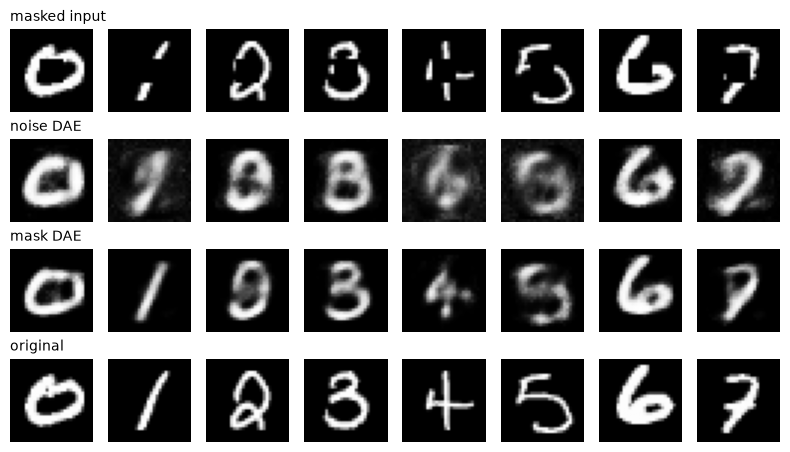

In [7]:
# 가림 손상: 숫자 가운데 8×8 칸을 검게
def mask_center(x):            # 숫자 가운데를 검게
    x = x.clone()              # 원본 보호
    x[:, :, 10:18, 10:18] = 0  # 세로 · 가로 10~17칸
    return x                   # 가린 묶음


def mask_loss(model, x):                         # 입력은 가린 숫자 · 정답은 깨끗한 숫자
    return F.mse_loss(model(mask_center(x)), x)  # 입력 가림 · 정답 깨끗


torch.manual_seed(0)                                         # 같은 출발점
mdae = train(AutoEncoder(32).to(device), loss_fn=mask_loss)  # 가림으로 배운 DAE


# 가린 8×8 칸 안에서만 MSE (가린 곳을 얼마나 채웠나)
Xm = mask_center(Xte)  # 평가 1만 장을 가림


def mse_box(A):  # 가린 칸 안에서만 재기
    return F.mse_loss(A[:, :, 10:18, 10:18], Xte[:, :, 10:18, 10:18]).item()  # 8×8 칸끼리


for name, out in [("가린 입력 그대로", Xm), ("AE", run(ae, Xm)),  # 네 가지 비교
                  ("노이즈 DAE", run(dae, Xm)), ("가림 DAE", run(mdae, Xm))]:
    print(f"{name:<9} 가린 칸 MSE {mse_box(out):.3f}")            # 얼마나 채웠나


# 반대로: 가림 DAE에 노이즈 입력
print(f"노이즈 입력 → 가림 DAE  MSE {mse(run(mdae, Xn)):.4f}"  # 반대 손상
      f" | 노이즈 DAE {mse(run(dae, Xn)):.4f}")
show([("masked input", Xm), ("noise DAE", run(dae, Xm)),       # 그림 4줄
      ("mask DAE", run(mdae, Xm)), ("original", Xte)])

**결과** · 예측 정답은 어느 정도만 — 가린 칸 MSE 0.359 → 0.149 · 가림으로 배운 DAE(0.100)만큼은 아님

- `가린 입력 그대로 가린 칸 MSE 0.359` — 가린 칸이 0이라 원래 획만큼 틀림
- `AE 가린 칸 MSE 0.235` — 깨끗한 숫자만 배운 모델도 조금 채움
- `노이즈 DAE 가린 칸 MSE 0.149` — 다른 손상을 배운 모델은 중간 · 그림에서 1 → 9, 2 · 3 → 8처럼 가운데를 엉뚱하게 채움
- `가림 DAE 가린 칸 MSE 0.100` — 같은 손상을 연습한 모델이 가장 잘 채움 · 1 · 3 · 5 · 6이 원래 숫자로 돌아옴
- `노이즈 입력 → 가림 DAE MSE 0.0387 | 노이즈 DAE 0.0250` — 반대도 마찬가지 · 연습 안 한 손상엔 약함

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">방법</th>
<th style="text-align: left;">차이</th>
<th style="text-align: left;">언제 쓰나</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;">가우시안 노이즈</td>
<td style="text-align: left;">모든 칸에 조금씩 · 원래 값이 흐릿하게 남음</td>
<td style="text-align: left;">센서 잡음 · 저조도 사진 · 스캔 잡티</td>
</tr>
<tr>
<td style="text-align: left;">가림(마스킹)</td>
<td style="text-align: left;">일부 칸을 <strong>통째로</strong> 지움 · 그 자리 정보 0</td>
<td style="text-align: left;">찢김 · 얼룩 · 가려진 글자 · 빈칸 채우기(인페인팅)</td>
</tr>
<tr>
<td style="text-align: left;">여러 손상을 섞어 학습</td>
<td style="text-align: left;">여러 손상을 함께 연습</td>
<td style="text-align: left;">실제 손상이 여러 종류일 때 (2장 문서: 어두워짐 · 상자 · 점)</td>
</tr>
</tbody>
</table>

> ⚠️ **주의**
>
> - 가린 칸 MSE는 **가린 자리만** 따로 잼
> - 전체 MSE로 재면 가린 64칸의 차이가 나머지 720칸에 묻힘

> ✅ **한 줄 정리** · DAE는 연습한 손상을 가장 잘 고치므로, 실제 들어올 손상의 종류(노이즈 · 가림)를 학습 입력에 그대로 넣는다.

**딥러닝 코드에서는**

- 가리고 채우게 하는 학습이 BERT
- MAE(Masked Autoencoder) 같은 사전 학습의 핵심 아이디어

### 1-5. `B` 복원에 요구 하나 더 · Sparse AE · `λ × z.sum()` <sub>day02 p124–143</sub>

> 🎯 **복원 말고 다른 요구를 손실에 더하면 오토인코더는 어떻게 달라지는가?**

💡 **쉽게 말하면**

- '그림을 다시 그려라'에 **단, 메모는 최대한 적은 칸에**라는 조건을 붙이면 한 장을 몇 칸만으로 표현하게 됨.
- 대신 그림은 조금 덜 정확해짐.

**실행 흐름**

1. 가운데 64칸 + ReLU
2. 손실 = 복원 오차 + λ × 가운데 값의 합
3. λ 0 · 1e-3 학습
4. 켜진 칸 수 · 복원 MSE

**먼저 예측** · λ를 0 → 1e-3으로 키우면 켜진 칸과 복원 MSE는? — 답은 코드 실행 결과 아래에

In [8]:
# 가운데 64칸 끝에 ReLU → 0이면 꺼진 칸, 0보다 크면 켜진 칸
class SparseAE(AutoEncoder):            # 가운데 64칸 + ReLU
    def __init__(self):                 # 인자 없음
        super().__init__(64)            # 잠재 64로 부모 생성
        self.encoder.append(nn.ReLU())  # 784 → 128 → 64 → ReLU


def sparse_loss(lam):                                      # 복원 오차 + λ × 가운데 값의 합
    def f(model, x):                                       # train이 부르는 손실
        z = model.encoder(x)                               # 가운데 값 (0 이상)
        out = model.decoder(z).reshape(-1, 1, 28, 28)      # 복원
        return F.mse_loss(out, x) + lam * z.sum(1).mean()  # 켜진 값이 많을수록 벌점
    return f                                               # λ를 기억한 손실 함수


# 벌점 세기 λ 0 · 1e-3 비교 (나머지 조건 같음)
for lam in [0, 1e-3]:                                           # 벌점 없음 · 있음
    torch.manual_seed(0)                                        # 같은 출발점
    m = train(SparseAE().to(device), loss_fn=sparse_loss(lam))  # 같은 조건 학습
    with torch.no_grad():                                       # 꺼내기만
        z = m.encoder(Xte)                                      # 평가 1만 장의 가운데 값
    on = (z > 0).float().sum(1).mean().item()                   # 한 장당 켜진 칸 수
    print(f"λ {lam:<5} | 켜진 칸 {on:.1f} / 64 | 복원 MSE {mse(run(m, Xte)):.4f}")  # 대가 비교

  epoch 1  loss 0.0685


  epoch 5  loss 0.0322


  epoch 10  loss 0.0160
λ 0     | 켜진 칸 46.4 / 64 | 복원 MSE 0.0205
  epoch 1  loss 0.0793


  epoch 5  loss 0.0529


  epoch 10  loss 0.0335
λ 0.001 | 켜진 칸 7.4 / 64 | 복원 MSE 0.0349


**결과** · 예측 정답은 켜진 칸 46.4 → 7.4개로 크게 줄고, 복원 MSE는 0.0205 → 0.0349로 커짐

- `λ 0 | 켜진 칸 46.4 / 64 | 복원 MSE 0.0205` — 벌점 없음 · 한 장에 64칸 중 46개 남짓이 켜짐
- `λ 0.001 | 켜진 칸 7.4 / 64 | 복원 MSE 0.0349` — 7개 남짓으로 표현 · 대가는 복원 오차

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">방법</th>
<th style="text-align: left;">차이</th>
<th style="text-align: left;">언제 쓰나</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;">Denoising AE (1-2)</td>
<td style="text-align: left;">요구: 입력을 망가뜨려도 원본을 낼 것 · 대가: 깨끗한 입력 · 연습 안 한 손상에 약함</td>
<td style="text-align: left;">손상된 입력을 고칠 때</td>
</tr>
<tr>
<td style="text-align: left;">Sparse AE</td>
<td style="text-align: left;">요구: 한 장에 켜지는 칸을 적게 (L1 벌점) · 대가: 복원 오차 증가</td>
<td style="text-align: left;">적은 수의 뚜렷한 특징이 필요할 때</td>
</tr>
<tr>
<td style="text-align: left;">VAE (이름만)</td>
<td style="text-align: left;">요구: 잠재 좌표가 표준정규분포 근처에 모일 것 · 새 좌표를 뽑을 곳이 정해짐</td>
<td style="text-align: left;">새 그림 생성 (오토인코더-1 4장 '어디서 뽑나'의 답)</td>
</tr>
</tbody>
</table>

> ⚠️ **주의**
>
> - 벌점 세기 λ가 크면 복원이 무너지고 작으면 효과가 없음
> - λ도 하나만 바꿔 같은 평가로 고르는 하이퍼파라미터

> ✅ **한 줄 정리** · 손실에 복원 말고 다른 요구를 더하면 모델이 하는 일이 달라지며, 그 대가로 복원 정확도를 일부 내준다.

**딥러닝 코드에서는**

- 손실 = 주 손실 + λ × 규제 항
- 가중치 감쇠(L2)
- L1 규제와 같은 모양

---
## 2. 문서 복원과 짝

> **이 장의 흐름**
>
> - 1장은 MNIST에 노이즈를 직접 입혔다
> - 실제 문서는 손상판과 깨끗한 판의 짝이 따로 주어짐.
> - 짝이 맞는지, 학습 · 평가 문서를 나눴는지, 문서 크기가 달라도 되는지를 직접 확인해야 함

**파이프라인 위치** · ① 데이터 준비 · ② 모델 설계 — 짝 만들기, 문서 단위 분리, 크기 맞추기

### 2장 준비 · 연습용 문서 만들기

미션 데이터 대신 노트북 안에서 문서를 그림 (내려받는 파일 없음). 문서 번호가 같으면 늘 같은 문서.

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">이름</th>
<th style="text-align: left;">하는 일</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;"><code>make_doc(번호, h, w)</code></td>
<td style="text-align: left;">흰 종이에 단어를 줄마다 씀(clean) → 손상 3가지(한쪽이 어두워짐 · 회색 상자 · 검은 점과 흰 점)를 입힘(dirty)</td>
</tr>
<tr>
<td style="text-align: left;"><code>train_ids</code> · <code>eval_ids</code></td>
<td style="text-align: left;">학습 문서 24장(1000 ~ 1023) · 평가 문서 8장(2000 ~ 2007)</td>
</tr>
<tr>
<td style="text-align: left;"><code>crop</code> · <code>to_batch</code></td>
<td style="text-align: left;">(y, x)에서 48×48 조각 · 조각 목록 → <code>(조각 수, 1, 48, 48)</code></td>
</tr>
<tr>
<td style="text-align: left;"><code>make_model(ch)</code></td>
<td style="text-align: left;">오토인코더-1 3-5 ConvAE와 같은 구조 · 채널 <code>ch</code> 바꿀 수 있음</td>
</tr>
<tr>
<td style="text-align: left;"><code>train_doc(X, Y)</code></td>
<td style="text-align: left;">입력 X · 정답 Y로 32개씩 · 10 epoch (epoch마다 평균 loss)</td>
</tr>
<tr>
<td style="text-align: left;"><code>EX</code> · <code>EY</code> · <code>rmse_patch</code></td>
<td style="text-align: left;">평가 문서 8장 × 조각 32개 = 256개 · 조각마다 RMSE의 평균</td>
</tr>
</tbody>
</table>

In [9]:
# 연습용 문서: 문서 번호 하나 → (clean, dirty) · 같은 번호는 늘 같은 문서
WORDS = ("the of and to in is data model image paper result note page "  # 문서에 쓸 단어
         "table value error clean noise sample layer filter record method "
         "letter number office review summary budget project").split()


def make_doc(seed, h=128, w=256):                             # 문서 번호 → (clean, dirty)
    rng = np.random.default_rng(seed)                         # 번호가 같으면 같은 문서
    size = int(rng.integers(12, 20))                          # 글자 크기
    img = PIL.Image.new("L", (w, h), 255)                     # 흰 종이
    draw = ImageDraw.Draw(img)                                # 글자를 그릴 붓
    font = ImageFont.load_default(size=size)                  # 기본 글꼴 · 크기 지정
    y = int(rng.integers(2, size // 2 + 2))                   # 첫 줄 높이
    while y + int(size * 1.45) <= h - 2:                      # 줄마다 단어를 이어 씀
        x, line = int(rng.integers(2, 12)), ""                # 줄 시작 위치 · 빈 줄
        while True:                                           # 줄이 찰 때까지
            cand = (line + " " + WORDS[rng.integers(len(WORDS))]).strip()  # 단어 하나 더 붙여 봄
            if x + draw.textlength(cand, font=font) > w - 4:  # 폭을 넘으면
                break                                         # 이 줄은 끝
            line = cand                                       # 넘지 않으면 확정
        draw.text((x, y), line, fill=0, font=font)            # 검은 글자로 씀
        y += int(size * 1.45)                                 # 다음 줄로
    clean = np.asarray(img, dtype=np.float32) / 255           # 정답판 0~1

    # 손상 ① 한쪽으로 갈수록 어두워짐
    g = np.linspace(0, rng.uniform(0.1, 0.35), w, dtype=np.float32)  # 가로로 점점 어두워짐
    dirty = clean * (1 - (g if rng.random() < 0.5 else g[::-1]))     # 왼쪽 또는 오른쪽이 어둡게

    # 손상 ② 회색 상자가 글자를 가림
    bh, bw = int(h * rng.uniform(0.1, 0.25)), int(w * rng.uniform(0.05, 0.15))  # 상자 크기
    by, bx = int(rng.integers(0, h - bh)), int(rng.integers(0, w - bw))         # 상자 위치
    dirty[by:by + bh, bx:bx + bw] = rng.uniform(0.2, 0.6)                       # 회색으로 덮음

    # 손상 ③ 검은 점 · 흰 점
    m, p = rng.random(dirty.shape), rng.uniform(0.002, 0.01)  # 칸마다 난수 · 점 비율
    dirty[m < p / 2], dirty[m > 1 - p / 2] = 0.0, 1.0         # 검은 점 · 흰 점
    return clean, np.clip(dirty, 0, 1).astype(np.float32)     # 정답 · 손상판

In [10]:
# 문서 번호: 학습 24장 · 평가 8장 (평가 문서는 학습에 안 씀)
H, W, PS = 128, 256, 48                                # 문서 세로 · 가로 · 조각 한 변
train_ids = list(range(1000, 1024))                    # 학습 문서 24장
eval_ids = list(range(2000, 2008))                     # 평가 문서 8장
docs = {i: make_doc(i) for i in train_ids + eval_ids}  # 번호 → (clean, dirty)


def crop(img, y, x):                # (y, x)가 왼쪽 위인 48×48 조각
    return img[y:y + PS, x:x + PS]  # 세로 · 가로 48칸


def to_batch(patches):  # 조각 목록 → (조각 수, 1, 48, 48)
    return torch.tensor(np.stack(patches)).unsqueeze(1).to(device)  # 쌓고 채널 축

In [11]:
# 문서 모델: 오토인코더-1 3-5 ConvAE와 같은 구조 (48 → 24 → 12 → 24 → 48)
def make_model(ch=(16, 32)):  # 채널을 바꿀 수 있게
    c1, c2 = ch               # 첫 층 · 둘째 층 채널
    return nn.Sequential(     # 줄이기 2번 · 늘리기 2번
        nn.Conv2d(1, c1, 3, 2, 1), nn.ReLU(),
        nn.Conv2d(c1, c2, 3, 2, 1), nn.ReLU(),
        nn.ConvTranspose2d(c2, c1, 3, 2, 1, output_padding=1), nn.ReLU(),
        nn.ConvTranspose2d(c1, 1, 3, 2, 1, output_padding=1),
        nn.Sigmoid()).to(device)


def train_doc(X, Y, epochs=10, ch=(16, 32), seed=0):                  # 입력 X · 정답 Y
    torch.manual_seed(seed)                                           # 모델 · 섞기 출발점
    model = make_model(ch)                                            # 새 모델
    opt = torch.optim.Adam(model.parameters(), lr=1e-3)               # 가중치 갱신 담당
    for epoch in range(epochs):                                       # 조각 전체를 epochs번
        perm = torch.randperm(len(X), device=device)                  # 번호 섞기
        total = 0.0                                                   # epoch 평균 loss용
        for k in range(0, len(X), 32):                                # 32개씩
            b = perm[k:k + 32]                                        # 이번 묶음 번호
            opt.zero_grad()                                           # 기울기 비우기
            loss = F.mse_loss(model(X[b]), Y[b])                      # 입력 X · 정답 Y
            loss.backward()                                           # 기울기 계산
            opt.step()                                                # 가중치 갱신
            total += loss.item() * len(b)                             # 묶음 크기만큼 더함
        if epoch in (0, epochs // 2 - 1, epochs - 1):                 # 1 · 중간 · 끝만
            print(f"  epoch {epoch + 1}  loss {total / len(X):.4f}")  # epoch 평균 loss
    return model.eval()                                               # 평가 모드로 돌려줌

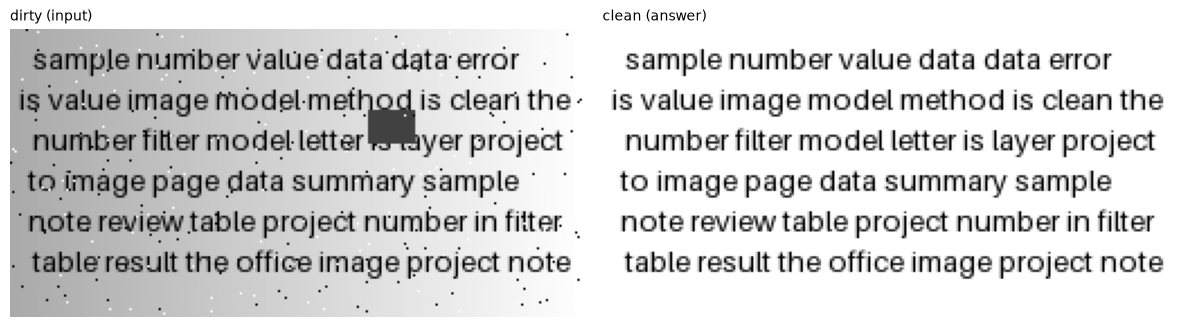

문서 32 장 · 한 장 (128, 256) | 평가 조각 (256, 1, 48, 48)


In [12]:
# 평가 조각: 평가 문서 8장 × 32개 (좌표 seed 7777)
erng = np.random.default_rng(7777)                                         # 평가 조각 좌표 고정
EX, EY = [], []                                                            # 입력 · 정답 조각
for i in eval_ids:                                                         # 평가 문서마다
    clean, dirty = docs[i]                                                 # 두 판
    for _ in range(32):                                                    # 조각 32개
        y, x = erng.integers(0, H - PS + 1), erng.integers(0, W - PS + 1)  # 같은 좌표 하나
        EX.append(crop(dirty, y, x))                                       # 손상 조각
        EY.append(crop(clean, y, x))                                       # 같은 자리 정답 조각
EX, EY = to_batch(EX), to_batch(EY)                                        # (256, 1, 48, 48)


def rmse_patch(out, ref=None):                                      # 조각마다 RMSE → 평균
    ref = EY if ref is None else ref                                # 기본 정답은 평가 조각
    return ((out - ref) ** 2).mean((1, 2, 3)).sqrt().mean().item()  # 조각 RMSE 평균


def show_rows(rows, idx):                                                  # 줄마다 같은 번호의 조각
    fig, axes = plt.subplots(len(rows), len(idx),                          # 줄 × 조각 수
                             figsize=(len(idx), 1.25 * len(rows)))
    for r, (name, T) in enumerate(rows):                                   # 줄마다
        for c, j in enumerate(idx):                                        # 고른 조각마다
            axes[r, c].imshow(T[j, 0].cpu(), cmap="gray", vmin=0, vmax=1)  # 밝기 0~1
            axes[r, c].axis("off")                                         # 눈금 숨김
        axes[r, 0].set_title(name, loc="left", fontsize=10)                # 줄 이름
    plt.tight_layout()                                                     # 간격 정리
    plt.show()                                                             # 그림 출력


# 문서 한 쌍 보기 · 크기 확인
fig, axes = plt.subplots(1, 2, figsize=(12, 3.2))                    # 손상판 · 정답판
for ax, (name, img) in zip(axes, [("dirty (input)", docs[1000][1]),  # 문서 1000 한 쌍
                                  ("clean (answer)", docs[1000][0])]):
    ax.imshow(img, cmap="gray", vmin=0, vmax=1)                      # 밝기 0~1
    ax.set_title(name, loc="left", fontsize=10)                      # 어느 판인지
    ax.axis("off")                                                   # 눈금 숨김
plt.tight_layout()                                                   # 간격 정리
plt.show()                                                           # 그림 출력
print("문서", len(docs), "장 · 한 장", docs[1000][0].shape,          # 개수 · 크기 확인
      "| 평가 조각", tuple(EX.shape))

### 2-1. `A` 짝 맞추기 · 같은 좌표로 자르기 · `crop(clean, y, x)` <sub>day02 p32–52 · P6</sub>

> 🎯 **손상 조각과 정답 조각의 짝이 어긋나면, 모델은 무엇을 배우는가?**

💡 **쉽게 말하면**

- 영어 단어장의 **뜻이 한 칸씩 밀려 적혀 있으면** 아무리 외워도 맞는 뜻을 말할 수 없고 '대충 흔한 답'만 남음.

<img src="images/ae2_pairs.png" alt="맞춘 짝과 어긋난 짝" width="837">

**실행 흐름**

1. make_pairs (P6 빈칸 두 곳)
2. 맞춘 짝 A · 어긋난 짝 B (입력은 같음)
3. 같은 모델 · 10 epoch
4. 평가 조각 RMSE · 조각 안 표준편차
5. 그림 4줄

**먼저 예측** · 어긋난 짝으로 학습한 모델 B에 평가 조각을 넣으면? — 답은 코드 실행 결과 아래에

학습 문서 24 장 | 입력 (3072, 1, 48, 48) | 정답 A · B (3072, 1, 48, 48)
맞춘 짝 A


  epoch 1  loss 0.1035


  epoch 5  loss 0.0122


  epoch 10  loss 0.0072
어긋난 짝 B


  epoch 1  loss 0.1146


  epoch 5  loss 0.0936


  epoch 10  loss 0.0936
RMSE  손상 그대로 0.134 | A 0.077 | B 0.289
조각 안 표준편차  정답 0.285 | A 0.269 | B 0.009


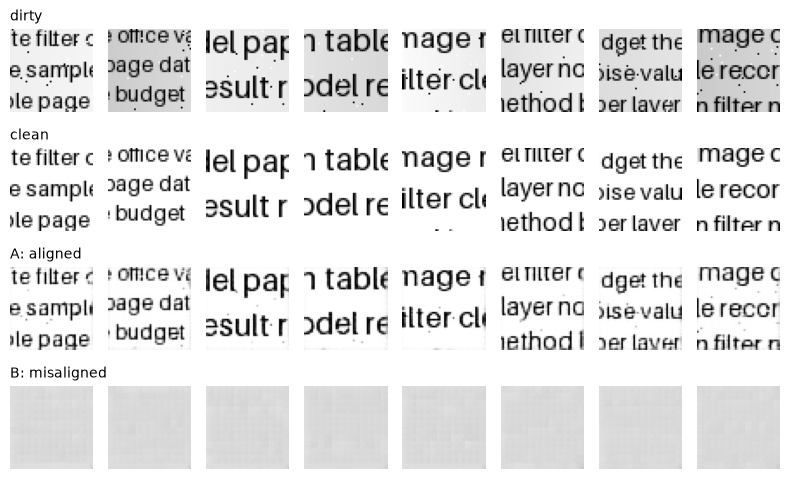

In [13]:
# P6 빈칸 정답: 정답 조각은 입력과 같은 (y, x)에서 clean으로 자름
def make_pairs(ids, n=128, seed=2026, misalign=False):   # 문서 번호 → (입력, 정답)
    rng = np.random.default_rng(seed)                    # 좌표 난수 고정
    rng_b = np.random.default_rng(seed + 1)              # 어긋난 짝 좌표 전용
    X, Y = [], []                                        # 입력 · 정답 조각
    for i in ids:                                        # 문서마다
        clean, dirty = docs[i]                           # 두 판
        ys, xs = rng.integers(0, H - PS + 1, n), rng.integers(0, W - PS + 1, n)  # 좌표 n개
        for y, x in zip(ys, xs):                         # 좌표마다
            X.append(crop(dirty, y, x))                  # 입력: dirty 조각
            if misalign:                                 # 버그판: 정답 좌표를 따로 뽑음
                y, x = rng_b.integers(0, H - PS + 1, 2)  # 다른 자리
            Y.append(crop(clean, y, x))                  # (a) 같은 (y, x)의 clean
    return to_batch(X), to_batch(Y)                      # 텐서 두 개


use_ids = [i for i in docs if i not in eval_ids]               # (b) 평가 문서 빼기
X, Y_A = make_pairs(use_ids)                                   # 맞춘 짝
_, Y_B = make_pairs(use_ids, misalign=True)                    # 어긋난 짝 (입력은 같음)
print("학습 문서", len(use_ids), "장 | 입력", tuple(X.shape),  # 모양 확인
      "| 정답 A · B", tuple(Y_A.shape))


# 같은 입력 · 같은 모델 · 정답만 다르게 학습
print("맞춘 짝 A")           # 어느 학습인지
model_A = train_doc(X, Y_A)  # 정답 A로 학습
print("어긋난 짝 B")         # 어느 학습인지
model_B = train_doc(X, Y_B)  # 정답 B로 학습


# 평가 조각 256개로 비교 (RMSE · 조각 안 밝기 표준편차)
with torch.no_grad():                                                     # 평가만
    OA, OB = model_A(EX), model_B(EX)                                     # 평가 조각 복원
print(f"RMSE  손상 그대로 {rmse_patch(EX):.3f} | A {rmse_patch(OA):.3f}"  # 세 점수
      f" | B {rmse_patch(OB):.3f}")


def spread(T):                                # 조각 안 밝기 표준편차 평균 (0이면 한 가지 밝기)
    return T.flatten(1).std(1).mean().item()  # 조각마다 표준편차 평균


print(f"조각 안 표준편차  정답 {spread(EY):.3f} | A {spread(OA):.3f}"  # 한 가지 밝기인지
      f" | B {spread(OB):.3f}")


# 문서마다 글자가 가장 많은 조각 하나씩 (8개)
dark = (EY < 0.5).float().mean((1, 2, 3))                                      # 조각마다 글자 비율
SHOW_P = [j * 32 + int(dark[j * 32:(j + 1) * 32].argmax()) for j in range(8)]  # 문서마다 1개
show_rows([("dirty", EX), ("clean", EY), ("A: aligned", OA),                   # 그림 4줄
           ("B: misaligned", OB)], SHOW_P)

**결과** · 예측 정답은 글자가 없는 거의 한 가지 밝기 판

- 조각 안 표준편차 0.009 (정답 0.285)
- 그림 넷째 줄 8칸 모두 같은 연회색
- 셋째 줄 A는 글자가 제자리에 돌아오고 배경이 밝아짐
- `epoch 10 loss 0.0072` — 맞춘 짝 A · 꾸준히 내려감
- `epoch 10 loss 0.0936` — 어긋난 짝 B · 0.09대에서 멈춤 · 에러는 없음
- `RMSE 손상 그대로 0.134 | A 0.077 | B 0.289` — B는 손상 그대로보다도 멂
- `조각 안 표준편차 정답 0.285 | A 0.269 | B 0.009` — B 출력은 조각 전체가 한 가지 밝기 (평균 밝기를 배움)

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">방법</th>
<th style="text-align: left;">차이</th>
<th style="text-align: left;">언제 쓰나</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;">맞춘 짝 <code>crop(clean, y, x)</code></td>
<td style="text-align: left;">입력과 <strong>같은 자리</strong>의 깨끗한 조각</td>
<td style="text-align: left;">문서 복원 학습 (기본)</td>
</tr>
<tr>
<td style="text-align: left;">어긋난 짝 (따로 뽑은 좌표)</td>
<td style="text-align: left;">모양은 같아 에러 없음 · 정답이 엉뚱한 자리</td>
<td style="text-align: left;">쓰면 안 됨 · 출력이 한 가지 밝기면 의심</td>
</tr>
<tr>
<td style="text-align: left;">짝 확인</td>
<td style="text-align: left;">짝 그림 몇 장 · 좌표 · 파일 이름 대조</td>
<td style="text-align: left;">학습 전에 반드시 (미션 가이드 '짝지어 불러오기')</td>
</tr>
</tbody>
</table>

> ⚠️ **주의**
>
> - 오토인코더-1 1-4 버그판과 같은 종류
> - 모양이 같아 에러 없이 loss만 0.09대에서 멈춤

> ✅ **한 줄 정리** · 모델은 의도가 아니라 우리가 만들어 준 입력과 정답의 관계를 배우므로, 학습 전에 짝이 같은 문서 · 같은 자리인지부터 확인한다.

**딥러닝 코드에서는**

- 이미지
- 마스크(세그멘테이션), 이미지
- 박스(객체 탐지)도 파일 정렬이 어긋나면 같은 증상

### 2-2. `A` 학습 문서 · 평가 문서 나누기 · `set(use_ids) & set(eval_ids)` <sub>day02 p53–58 · P6</sub>

> 🎯 **조각을 다 자른 뒤 섞어서 나누면 왜 안 되는가?**

💡 **쉽게 말하면**

- 시험 문제를 **교과서 같은 쪽에서 문장만 바꿔 내면** 처음 보는 문제를 푸는 실력을 잴 수 없음.

<img src="images/ae2_split.png" alt="문서로 나누기와 조각 섞기" width="837">

**실행 흐름**

1. 문서 번호 겹침 확인
2. 학습 문서의 다른 조각 vs 평가 문서 조각 RMSE
3. 조각을 섞어 나누면 몇 문서가 겹치나

**먼저 예측** · 조각을 섞어 나누면 평가 조각의 문서 중 몇 장이 학습에도 들어갈까? — 답은 코드 실행 결과 아래에

In [14]:
# 학습 문서와 평가 문서가 겹치지 않는지 번호로 확인
print("겹치는 문서 번호:", set(use_ids) & set(eval_ids))  # 빈 집합이어야 함


# 학습에 쓴 문서의 다른 자리 조각으로 재면? (문서 8장 × 32개)
TX, TY = make_pairs(use_ids[:8], n=32, seed=7777)    # 학습 문서의 다른 자리
with torch.no_grad():                                # 평가만
    rm_train = rmse_patch(model_A(TX), TY)           # 학습 문서 조각 점수
print(f"모델 A RMSE  학습 문서 조각 {rm_train:.4f}"  # 두 점수 비교
      f" | 평가 문서 조각 {rmse_patch(OA):.4f}")


# 조각을 다 자른 뒤 섞어 나누면: 평가 조각의 문서가 학습에도 있음
rng = np.random.default_rng(0)                             # 섞기 고정
doc_of = np.repeat(list(docs), 32)                         # 조각마다 문서 번호 (32장 × 32개)
perm = rng.permutation(len(doc_of))                        # 조각 번호 섞기
tr_docs, ev_docs = set(doc_of[perm[:800]]), set(doc_of[perm[800:]])  # 앞 800 학습 · 나머지 평가
print(f"섞어 나눔 → 평가 조각의 문서 {len(ev_docs)}장 중"  # 겹치는 문서 수
      f" 학습에도 있는 문서 {len(ev_docs & tr_docs)}장")

겹치는 문서 번호: set()
모델 A RMSE  학습 문서 조각 0.0773 | 평가 문서 조각 0.0771
섞어 나눔 → 평가 조각의 문서 32장 중 학습에도 있는 문서 32장


**결과** · 예측 정답은 32장 전부 — 모든 평가 조각이 '학습에서 본 문서'에서 나옴

- `겹치는 문서 번호: set()` — 문서로 먼저 나눠 겹침 0 · 복원 그림이 아니라 번호로 확인
- `모델 A RMSE 학습 문서 조각 0.0773 | 평가 문서 조각 0.0771` — 이번 합성 문서에선 거의 같음 (평가 쪽이 오히려 조금 작음) · 그래도 나누는 이유는 '처음 보는 데이터로 잰다'는 약속
- `섞어 나눔 → 평가 조각의 문서 32장 중 학습에도 있는 문서 32장` — 섞어 나누면 평가 문서가 전부 학습에도 들어감

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">방법</th>
<th style="text-align: left;">차이</th>
<th style="text-align: left;">언제 쓰나</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;">문서(묶음) 단위로 먼저 나누기</td>
<td style="text-align: left;">같은 문서의 조각은 한쪽에만</td>
<td style="text-align: left;">한 묶음에서 여러 샘플이 나올 때 · 조각 · 프레임 · 환자 (기본)</td>
</tr>
<tr>
<td style="text-align: left;">조각을 섞어 나누기</td>
<td style="text-align: left;">같은 문서가 학습 · 평가 양쪽에 → 점수가 부풀 수 있음</td>
<td style="text-align: left;">샘플끼리 완전히 독립일 때만</td>
</tr>
</tbody>
</table>

> ⚠️ **주의**
>
> - 차이가 작게 나와도 섞어 나누면 안 됨
> - 실제 문서는 문서마다 글씨체
> - 손상이 달라 차이가 커질 수 있음

> ✅ **한 줄 정리** · 한 문서에서 여러 조각을 자를 때는 문서 번호로 먼저 학습 · 평가를 나누고, 겹침은 번호로 확인한다.

**딥러닝 코드에서는**

- sklearn `GroupKFold`
- `GroupShuffleSplit`(머신러닝 정리본의 교차 검증)이 바로 이 '묶음 단위 분할'

### 2-3. `A` 문서 한 장 통째로 · 크기 맞추기 · `np.pad` · `out[:, :, :h, :w]` <sub>day02 p60–78 · P7</sub>

> 🎯 **조각으로 배운 모델에 크기가 다른 문서 한 장을 넣으면 어떻게 맞추는가?**

💡 **쉽게 말하면**

- Conv는 **같은 도장을 옮겨 찍기**라 종이 크기와 상관없이 찍을 수 있음.
- 다만 반으로 두 번 접는 모델이라 4의 배수가 아니면 펼쳤을 때 여백이 남음.

<img src="images/ae2_padcrop.png" alt="채우고 자르기와 조각 이어 붙이기" width="837">

**실행 흐름**

1. 128×256 통째로
2. 130×270 에러
3. 층마다 모양 (P7-1)
4. 처음 홀수가 들어간 층 (P7-2)
5. 방법 ① 채우고 자르기 · 방법 ② 조각 이어 붙이기
6. 경계 RMSE
7. 확대 그림

**먼저 예측** · 130×270 문서를 넣으면 나오는 크기는? (공식 · 손계산 방법은 오토인코더-1 3-1 · 3-4) — 답은 코드 실행 결과 아래에

In [15]:
# 문서 한 장(128×256)을 통째로 → 같은 크기로 나옴
clean0, dirty0 = docs[2000]                                          # 평가 문서 한 장
with torch.no_grad():                                                # 통째로 넣기만
    out0 = model_A(torch.tensor(dirty0, device=device)[None, None])  # (1, 1, 128, 256)
print("128×256 문서 → 출력", tuple(out0.shape))                      # 크기 그대로인지


# 세로 130 · 가로 270 문서 → 크기 어긋남 (일부러 내는 에러)
clean_b, dirty_b = make_doc(3000, h=130, w=270)       # 4의 배수가 아닌 문서
t = torch.tensor(dirty_b, device=device)[None, None]  # (1, 1, 130, 270)
try:
    with torch.no_grad():                             # 에러 확인만
        ((model_A(t) - t) ** 2).mean()                # 칸마다 빼기 시도
except RuntimeError as e:                             # 에러를 잡아 멈추지 않게
    print("RuntimeError:", str(e)[:64])               # 앞부분만 읽기


# P7-1 빈칸 정답: 층마다 모양 찍기 (방법은 오토인코더-1 3-3)
with torch.no_grad():                                     # 층마다 통과만
    for k, layer in enumerate(model_A):                   # 층 번호와 함께
        t = layer(t)                                      # ① 층 하나 통과
        if not isinstance(layer, (nn.ReLU, nn.Sigmoid)):  # 크기를 바꾸는 층만 출력
            print(f"{k}번 {type(layer).__name__:<16} {tuple(t.shape)}")  # 층마다 모양
first_odd_layer = 2                                       # ② 65×135(홀수)가 처음 들어가는 Conv2d


# 방법 ①: 4의 배수로 채우고 → 넣고 → 잘라내기 (P7-2 ③)
h, w = dirty_b.shape                                                # 원래 크기
H4, W4 = (h + 3) // 4 * 4, (w + 3) // 4 * 4                         # 4의 배수로 올림
padded = np.pad(dirty_b, ((0, H4 - h), (0, W4 - w)), mode="edge")   # 아래 · 오른쪽 채움
with torch.no_grad():                                               # 채운 문서 복원만
    out = model_A(torch.tensor(padded, device=device)[None, None])  # 132×272 통째로
out_crop = out[:, :, :h, :w]                                        # ③ 원래 문서 자리만
print("채운 모양", padded.shape, "→ 나온", tuple(out.shape),        # 세 모양
      "→ 잘라낸", tuple(out_crop.shape))

128×256 문서 → 출력 (1, 1, 128, 256)
RuntimeError: The size of tensor a (272) must match the size of tensor b (270)
0번 Conv2d           (1, 16, 65, 135)
2번 Conv2d           (1, 32, 33, 68)
4번 ConvTranspose2d  (1, 16, 66, 136)
6번 ConvTranspose2d  (1, 1, 132, 272)
채운 모양 (132, 272) → 나온 (1, 1, 132, 272) → 잘라낸 (1, 1, 130, 270)


방법 ① 채우고 자름  경계 부근 RMSE 0.062 | 나머지 0.074
방법 ② 조각 이어 붙임  경계 부근 RMSE 0.098 | 나머지 0.074


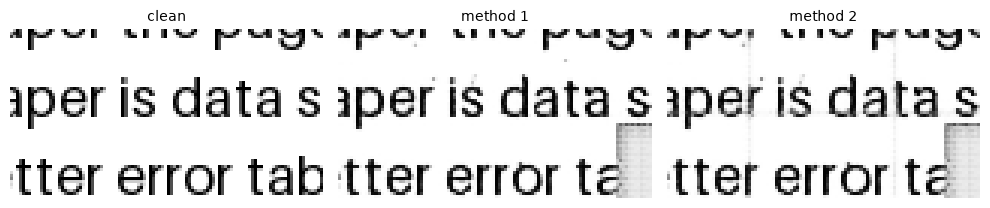

In [16]:
# 방법 ②: 48×48 조각으로 나눠 복원해 이어 붙이기
tiled = np.zeros_like(padded)                                            # 붙일 빈 판
with torch.no_grad():                                                    # 복원만
    for y in range(0, H4, PS):                                           # 세로 48칸 간격
        for x in range(0, W4, PS):                                       # 가로 48칸 간격
            part = padded[y:y + PS, x:x + PS]                            # 조각 하나
            ph, pw = part.shape                                          # 끝 조각은 작을 수 있음
            part4 = np.pad(part, ((0, -ph % 4), (0, -pw % 4)), mode="edge")  # 조각도 4의 배수로
            o = model_A(torch.tensor(part4, device=device)[None, None])  # 조각 복원
            tiled[y:y + ph, x:x + pw] = o[0, 0, :ph, :pw].cpu().numpy()  # 제자리에 붙임
out_tile = tiled[:h, :w]                                                 # 원래 크기만


# 조각 경계 4칸 부근 · 나머지로 나눠 RMSE
seam = np.zeros((h, w), dtype=bool)                                  # 경계 표시판
for y in range(PS, h, PS):                                           # 세로 경계
    seam[y - 2:y + 2] = True                                         # 경계 4칸
for x in range(PS, w, PS):                                           # 가로 경계
    seam[:, x - 2:x + 2] = True                                      # 경계 4칸
img1 = out_crop[0, 0].cpu().numpy()                                  # 방법 ① 결과
for name, img in [("방법 ① 채우고 자름", img1), ("방법 ② 조각 이어 붙임", out_tile)]:  # 두 방법
    err = (img - clean_b) ** 2                                       # 칸마다 오차²
    print(f"{name}  경계 부근 RMSE {np.sqrt(err[seam].mean()):.3f}"  # 경계 · 나머지
          f" | 나머지 {np.sqrt(err[~seam].mean()):.3f}")


# 경계(가로 48 · 96, 세로 48)가 들어간 부분 확대
zy, zx = slice(20, 76), slice(20, 124)                                     # 경계가 들어간 부분
fig, axes = plt.subplots(1, 3, figsize=(10, 2.2))                          # 정답 · 방법 ① · ②
for ax, (name, img) in zip(axes, [("clean", clean_b), ("method 1", img1),  # 세 장
                                  ("method 2", out_tile)]):
    ax.imshow(img[zy, zx], cmap="gray", vmin=0, vmax=1)                    # 확대
    ax.set_title(name, fontsize=10)                                        # 이름
    ax.axis("off")                                                         # 눈금 숨김
plt.tight_layout()                                                         # 간격 정리
plt.show()                                                                 # 그림 출력

**결과** · 예측 정답은 132×272 — 130 → 65(홀수) → 33 → 66 → 132, 270 → 135(홀수) → 68 → 136 → 272

- `128×256 문서 → 출력 (1, 1, 128, 256)` — 4의 배수라 그대로 · 같은 필터를 칸마다 옮기니 크기가 달라도 계산됨
- `RuntimeError: The size of tensor a (272) must match the size of tensor b (270)` — 에러는 마지막 축(가로)만 알려 줌
- `2번 Conv2d (1, 32, 33, 68)` — 65×135(홀수)가 처음 들어간 층 → P7 ② 정답 2
- `6번 ConvTranspose2d (1, 1, 132, 272)` — 세로 · 가로 모두 2칸씩 큼
- `→ 잘라낸 (1, 1, 130, 270)` — 방법 ①: 132×272로 채워 넣고 원래 자리만
- `방법 ① 채우고 자름 경계 부근 RMSE 0.062 | 나머지 0.074` — 조각 경계가 없음
- `방법 ② 조각 이어 붙임 경계 부근 RMSE 0.098 | 나머지 0.074` — 나머지는 같고 조각 경계에서만 나빠짐 · 확대 그림 method 2에 가로 · 세로 옅은 줄 (두 방법 모두 회색 상자 아래 글자는 못 살림)

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">방법</th>
<th style="text-align: left;">차이</th>
<th style="text-align: left;">언제 쓰나</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;">방법 ① 4의 배수로 채우고 → 잘라내기</td>
<td style="text-align: left;">문서 한 장을 한 번에 · 조각 경계 없음</td>
<td style="text-align: left;">문서가 메모리에 들어갈 때 (기본)</td>
</tr>
<tr>
<td style="text-align: left;">방법 ② 조각으로 나눠 이어 붙이기</td>
<td style="text-align: left;">메모리 적게 · 조각 경계에 옅은 줄</td>
<td style="text-align: left;">아주 큰 이미지 · 메모리가 모자랄 때 (겹쳐 자르면 경계 완화)</td>
</tr>
<tr>
<td style="text-align: left;">입력을 리사이즈</td>
<td style="text-align: left;">크기는 맞지만 글자 획이 변형</td>
<td style="text-align: left;">복원 과제에서는 피함</td>
</tr>
</tbody>
</table>

> ⚠️ **주의**
>
> - 최종 에러 한 줄은 마지막 축만 알려 줌
> - **층마다 모양을 찍어** 처음 홀수가 들어간 층을 찾음

> ✅ **한 줄 정리** · Conv 모델은 크기와 상관없이 계산되지만 줄이고 늘리는 횟수만큼의 배수가 아니면 크기가 어긋나므로, 4의 배수로 채워 넣고 원래 크기로 잘라낸다.

**딥러닝 코드에서는**

- 미션 안내의 '문서 크기 두 종류'
- 학습 전에 크기 목록을 뽑고 이 방법으로 맞춤

---
## 3. 복원 평가

> **이 장의 흐름**
>
> - 2장에서 문서 RMSE가 줄었다
> - 이것이 좋은 복원일까? 아무것도 안 한 답(기준선) 옆에 놓고, 문서에서 중요한 글자 칸을 따로 재고, 그림으로 확인

**파이프라인 위치** · ④ 평가 — 기준선, RMSE · PSNR, 글자 칸, 눈으로 보는 평가

### 3-1. `A` 기준선 · RMSE · PSNR · `rmse_doc` · `psnr_doc` <sub>day02 p79–85 · P8</sub>

> 🎯 **문서 RMSE 0.070은 좋은 점수인가?**

💡 **쉽게 말하면**

- 시험 점수 70점은 **반 평균을 알아야** 잘한 건지 앎.
- 아무것도 안 한 답(흰 종이 · 손상 그대로)의 점수가 그 '평균' 역할.

**실행 흐름**

1. 평가 문서 8장 통째로 복원
2. 흰 종이 · 평균 밝기 종이 · 손상 그대로 · 모델
3. 같은 함수로 RMSE · PSNR

**먼저 예측** · 모델도 학습도 없이 흰 종이만 내면 RMSE는 어디쯤일까? — 답은 코드 실행 결과 아래에

In [17]:
# 평가 문서 8장을 한 장씩 통째로 복원 (128×256은 4의 배수)
with torch.no_grad():                                                         # 복원만
    eval_out = [model_A(torch.tensor(docs[i][1], device=device)[None, None])  # 평가 문서 8장
                [0, 0].cpu().numpy() for i in eval_ids]
eval_clean = [docs[i][0] for i in eval_ids]                                   # 정답 8장
eval_dirty = [docs[i][1] for i in eval_ids]                                   # 손상 8장


def rmse_doc(outs, cleans):                               # 문서마다 RMSE → 평균
    return float(np.mean([np.sqrt(((o - c) ** 2).mean())  # 문서마다 RMSE 평균
                          for o, c in zip(outs, cleans)]))


def psnr_doc(outs, cleans):  # 10 × log10(1 / MSE) · 클수록 가까움
    return float(np.mean([10 * np.log10(1 / ((o - c) ** 2).mean())  # 문서마다 PSNR 평균
                          for o, c in zip(outs, cleans)]))


# 기준선: 아무것도 안 한 답 (P8 빈칸 ① 흰 종이 · ② 모델 출력)
white = [np.ones_like(c) for c in eval_clean]                      # 모든 칸 1
mean_val = float(np.mean([docs[i][0].mean() for i in train_ids]))  # 학습 문서 평균 밝기
gray = [np.full_like(c, mean_val) for c in eval_clean]             # 학습 문서 평균 밝기
for name, outs in [("흰 종이", white), ("평균 밝기 종이", gray),   # 기준선 둘 + 둘
                   ("손상 그대로", eval_dirty), ("맞춘 짝 모델", eval_out)]:
    print(f"{name:<8} 문서 RMSE {rmse_doc(outs, eval_clean):.3f}"  # 같은 함수로
          f" | PSNR {psnr_doc(outs, eval_clean):.1f} dB")

흰 종이     문서 RMSE 0.285 | PSNR 10.9 dB
평균 밝기 종이 문서 RMSE 0.266 | PSNR 11.5 dB
손상 그대로   문서 RMSE 0.154 | PSNR 16.4 dB
맞춘 짝 모델  문서 RMSE 0.070 | PSNR 23.3 dB


**결과** · 예측 정답은 0.285 — 손상 그대로(0.154)보다 나쁘지만 0.3 아래 · 이것이 '아무것도 안 한 답'의 눈금

- `흰 종이 문서 RMSE 0.285 | PSNR 10.9 dB` — 글자를 하나도 안 썼는데 이 정도 = 바탕이 대부분 흰색이라서
- `평균 밝기 종이 문서 RMSE 0.266 | PSNR 11.5 dB` — 학습 문서 평균 밝기 한 가지로 칠한 종이
- `손상 그대로 문서 RMSE 0.154 | PSNR 16.4 dB` — 아무것도 안 고친 입력
- `맞춘 짝 모델 문서 RMSE 0.070 | PSNR 23.3 dB` — 기준선 셋보다 확실히 원본에 가까움 · PSNR은 클수록 좋음

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">방법</th>
<th style="text-align: left;">차이</th>
<th style="text-align: left;">언제 쓰나</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;">MSE</td>
<td style="text-align: left;">(차이)² 평균 · 단위가 밝기의 제곱</td>
<td style="text-align: left;">학습 손실 (미분이 쉬움)</td>
</tr>
<tr>
<td style="text-align: left;">RMSE</td>
<td style="text-align: left;">√MSE · 픽셀 밝기와 같은 단위 · <strong>작을수록</strong> 좋음</td>
<td style="text-align: left;">사람이 읽는 평가 점수</td>
</tr>
<tr>
<td style="text-align: left;">PSNR (dB)</td>
<td style="text-align: left;">10 × log10(최댓값² / MSE) · <strong>클수록</strong> 좋음</td>
<td style="text-align: left;">이미지 복원 논문 · 미션 안내의 점수</td>
</tr>
<tr>
<td style="text-align: left;">기준선 (흰 종이 · 손상 그대로)</td>
<td style="text-align: left;">아무것도 안 한 답의 점수</td>
<td style="text-align: left;">모든 점수 옆에 함께 적는 눈금</td>
</tr>
</tbody>
</table>

> ⚠️ **주의**
>
> - RMSE는 작을수록, PSNR은 클수록 좋음 (방향이 반대)
> - 숫자 하나만 따로 적지 말고 기준선 옆에

> ✅ **한 줄 정리** · 복원 점수는 흰 종이 · 손상 그대로 같은 기준선 옆에 놓고 읽어야 의미가 있다.

**딥러닝 코드에서는**

- 분류의 '가장 많은 클래스만 찍기' 정확도, 회귀의 '평균만 예측' 오차가 같은 역할의 기준선

### 3-2. `A` 글자 칸 따로 재기 · 픽셀 MSE vs 눈으로 보는 평가 · `mask = clean < 0.5` <sub>day02 p86–103 · P8</sub>

> 🎯 **전체 점수가 좋아졌으면 글자도 좋아진 것인가?**

💡 **쉽게 말하면**

- 반 평균이 올랐어도 **내가 신경 쓰는 학생의 점수**는 떨어졌을 수 있음.
- 넓은 배경이 평균을 끌어올리면 좁은 글자 칸의 악화가 가려짐.

<img src="images/ae2_textrmse.png" alt="전체 · 배경 · 글자 칸 RMSE" width="677">

**실행 흐름**

1. 글자 칸 = 정답에서 0.5보다 어두운 칸 (P8 ③)
2. 전체 · 배경 · 글자 칸 RMSE
3. 글자 확대 그림
4. 가장 나쁜 조각 3개

**먼저 예측** · 글자 칸만 모아 재면, 모델은 손상 그대로보다 원본에 가까울까? — 답은 코드 실행 결과 아래에

글자 칸 비율 10.2% (나머지는 배경)
손상 그대로  전체 0.154 | 배경 칸 0.161 | 글자 칸 0.069
맞춘 짝 모델 전체 0.070 | 배경 칸 0.050 | 글자 칸 0.156


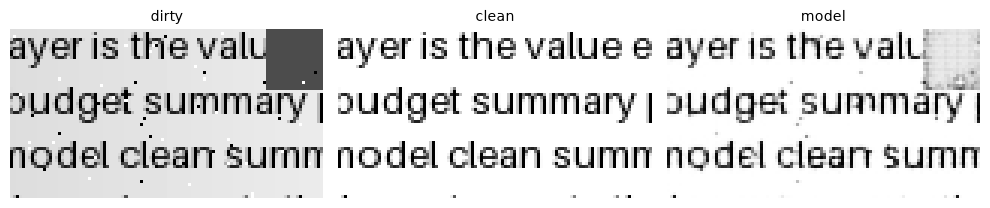

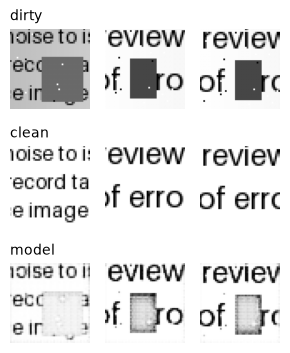

In [18]:
# P8 빈칸 정답 ③: 글자 칸 = 정답(clean)에서 0.5보다 어두운 칸
def text_mask(clean):   # 정답판 → 글자 칸 표시
    return clean < 0.5  # 어두운 칸 = 글자


def rmse_part(outs, cleans, text=True):                 # 글자 칸 또는 배경 칸만 RMSE
    vals = []                                           # 문서별 값
    for o, c in zip(outs, cleans):                      # 문서마다
        m = text_mask(c) if text else ~text_mask(c)     # 글자 칸 또는 배경 칸
        vals.append(np.sqrt(((o - c)[m] ** 2).mean()))  # 그 칸만 RMSE
    return float(np.mean(vals))                         # 8장 평균


ratio = np.mean([text_mask(c).mean() for c in eval_clean])                    # 글자 칸 비율
print(f"글자 칸 비율 {ratio:.1%} (나머지는 배경)")                            # 얼마나 좁은지
for name, outs in [("손상 그대로", eval_dirty), ("맞춘 짝 모델", eval_out)]:  # 두 결과
    print(f"{name:<7} 전체 {rmse_doc(outs, eval_clean):.3f}"                  # 전체 · 배경 · 글자
          f" | 배경 칸 {rmse_part(outs, eval_clean, False):.3f}"
          f" | 글자 칸 {rmse_part(outs, eval_clean):.3f}")


# 눈으로 보기: 평가 문서 2000 왼쪽 위 글자 확대
zy, zx = slice(8, 64), slice(8, 112)                         # 왼쪽 위 글자 부분
fig, axes = plt.subplots(1, 3, figsize=(10, 2.2))            # 손상 · 정답 · 모델
for ax, (name, img) in zip(axes, [("dirty", eval_dirty[0]),  # 문서 2000
                                  ("clean", eval_clean[0]),
                                  ("model", eval_out[0])]):
    ax.imshow(img[zy, zx], cmap="gray", vmin=0, vmax=1)      # 확대
    ax.set_title(name, fontsize=10)                          # 이름
    ax.axis("off")                                           # 눈금 숨김
plt.tight_layout()                                           # 간격 정리
plt.show()                                                   # 그림 출력


# 평가 조각 256개 중 모델 오차가 가장 큰 3개
worst = ((OA - EY) ** 2).mean((1, 2, 3)).argsort(descending=True)[:3]     # 오차 큰 3개
show_rows([("dirty", EX), ("clean", EY), ("model", OA)], worst.tolist())  # 눈으로 확인

**결과** · 예측 정답은 아님

- 글자 칸 RMSE는 손상 그대로 0.069 → 모델 0.156으로 오히려 멂
- 확대 그림에서 모델의 획은 원본보다 옅은 회색이고 가장자리가 흐림
- 가장 나쁜 조각 3개는 모두 회색 상자가 글자를 가린 곳 (상자는 밝아졌지만 그 아래 글자는 돌아오지 않음)
- `글자 칸 비율 10.2% (나머지는 배경)` — 글자는 문서의 10%뿐
- `손상 그대로 전체 0.154 | 배경 칸 0.161 | 글자 칸 0.069` — 손상은 주로 배경(어두워짐 · 상자 · 점)에 있음
- `맞춘 짝 모델 전체 0.070 | 배경 칸 0.050 | 글자 칸 0.156` — 배경 개선이 전체 점수를 끌어내림 · 글자 칸은 나빠짐

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">방법</th>
<th style="text-align: left;">차이</th>
<th style="text-align: left;">언제 쓰나</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;">픽셀 MSE · RMSE (전체)</td>
<td style="text-align: left;">모든 칸을 똑같이 셈 · 넓은 배경이 지배</td>
<td style="text-align: left;">학습 손실 · 첫 비교</td>
</tr>
<tr>
<td style="text-align: left;">중요한 칸만 (글자 칸 RMSE)</td>
<td style="text-align: left;">목적에 맞는 부분만 잼 · 정답이 있어야 칸을 고름</td>
<td style="text-align: left;">정답이 있는 평가 데이터로 진단할 때</td>
</tr>
<tr>
<td style="text-align: left;">눈으로 보는 평가 (확대 · 가장 나쁜 조각)</td>
<td style="text-align: left;">숫자가 놓친 흐림 · 끊김 · 잔상을 봄 · 사람마다 다를 수 있음</td>
<td style="text-align: left;">숫자를 본 뒤 반드시 · 정답이 없는 문서</td>
</tr>
</tbody>
</table>

> ⚠️ **주의**
>
> - 글자 칸은 **정답**(clean)으로 고름
> - 손상판으로 고르면 상자 · 어두운 배경
> - 점까지, 모델 출력으로 고르면 흐려진 획이 빠짐

> ✅ **한 줄 정리** · 평균 점수가 좋아졌다고 중요한 부분이 좋아진 것은 아니므로, 목적에 맞는 부분을 따로 재고 그림으로 확인한다.

**딥러닝 코드에서는**

- 클래스 불균형에서 정확도 대신 클래스별 재현율을 보는 것과 같은 이유 (머신러닝 평가 지표)

---
## 4. 실험 설계

> **이 장의 흐름**
>
> - 3장에서 글자가 흐려진다는 것을 알았다
> - 무엇을 바꾸면 나아질까? 바꾼 것의 효과라고 말하려면 하나만 바꾸고, 설정을 안 바꿔도 생기는 흔들림과 비교

**파이프라인 위치** · ⑤ 개선 실험 — seed 흔들림, 하나만 바꾸기, 기록 일곱 칸

### 4-1. `A` 반복 실행의 흔들림 · `seed=1` <sub>day02 p104–109 · P9</sub>

> 🎯 **설정을 하나도 안 바꾸고 seed만 바꾸면 점수는 얼마나 달라지는가?**

💡 **쉽게 말하면**

- 같은 실력의 학생이 **같은 시험을 두 번** 봐도 점수가 조금 다름.
- 이 '조금'보다 작은 차이는 실력 차이라고 말하기 어려움.

**실행 흐름**

1. 기준 = seed 0 (2-1 모델 A)
2. seed 1로 다시 학습
3. 같은 평가 함수
4. 차이 = 흔들림

**먼저 예측** · seed만 바꾼 두 모델의 문서 RMSE 차이는? — 답은 코드 실행 결과 아래에

In [19]:
# 평가 함수: 평가 문서 8장 → (문서 RMSE, 글자 칸 RMSE)
def evaluate(model):                                                        # 모델 → (문서, 글자 칸)
    with torch.no_grad():                                                   # 평가만
        outs = [model(torch.tensor(docs[i][1], device=device)[None, None])  # 평가 문서 8장
                [0, 0].cpu().numpy() for i in eval_ids]
    return rmse_doc(outs, eval_clean), rmse_part(outs, eval_clean)          # 3장 함수 그대로


# 설정은 그대로 · seed만 0 → 1
base = evaluate(model_A)                                           # seed 0 = 2-1 모델 A
print("seed 1 학습")                                               # 어느 학습인지
s1 = evaluate(train_doc(X, Y_A, seed=1))                           # 설정 같고 seed만 1
print(f"seed 0 | 문서 {base[0]:.4f} | 글자 칸 {base[1]:.4f}")      # 기준
print(f"seed 1 | 문서 {s1[0]:.4f} | 글자 칸 {s1[1]:.4f}")          # 다시 학습
wobble = (abs(s1[0] - base[0]), abs(s1[1] - base[1]))              # 차이의 크기
print(f"흔들림 | 문서 {wobble[0]:.4f} | 글자 칸 {wobble[1]:.4f}")  # 4-2의 눈금

seed 1 학습


  epoch 1  loss 0.1031


  epoch 5  loss 0.0136


  epoch 10  loss 0.0077
seed 0 | 문서 0.0695 | 글자 칸 0.1557
seed 1 | 문서 0.0725 | 글자 칸 0.1585
흔들림 | 문서 0.0030 | 글자 칸 0.0028


**결과** · 예측 정답은 0.0030 (글자 칸 0.0028) — 설정을 안 바꿔도 이만큼 흔들림

- `seed 0 | 문서 0.0695 | 글자 칸 0.1557` — 기준 (3장 점수를 소수 넷째 자리까지)
- `seed 1 | 문서 0.0725 | 글자 칸 0.1585` — 설정은 똑같고 출발점만 다름
- `흔들림 | 문서 0.0030 | 글자 칸 0.0028` — 4-2에서 차이를 읽는 눈금

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">방법</th>
<th style="text-align: left;">차이</th>
<th style="text-align: left;">언제 쓰나</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;">seed 고정 · 한 번 실행</td>
<td style="text-align: left;">결과 재현 가능 · 흔들림 크기는 모름</td>
<td style="text-align: left;">코드 확인 · 디버깅</td>
</tr>
<tr>
<td style="text-align: left;">seed만 바꿔 여러 번</td>
<td style="text-align: left;">흔들림 크기를 앎</td>
<td style="text-align: left;">작은 차이를 비교할 때의 기준 (이번 실습)</td>
</tr>
<tr>
<td style="text-align: left;">여러 seed 평균 ± 표준편차</td>
<td style="text-align: left;">가장 믿을 만함 · 시간이 여러 배</td>
<td style="text-align: left;">보고서 · 논문 · 최종 선택</td>
</tr>
</tbody>
</table>

> ⚠️ **주의**
>
> - seed 2개는 흔들림의 **대략적 크기**일 뿐
> - 소수점 넷째 자리 차이를 '개선'이라 부르기 전에 이 값과 비교

> ✅ **한 줄 정리** · 같은 설정도 seed에 따라 점수가 흔들리므로, 설정을 바꾼 효과는 이 흔들림보다 클 때만 믿는다.

**딥러닝 코드에서는**

- 논문의 '평균 ± 표준편차 (seed 5개)' 표기가 이것
- 미션 보고서에도 흔들림을 함께 적음

### 4-2. `A` 하나만 바꾸기 vs 여러 개 한 번에 · `train_doc(epochs=20)` <sub>day02 p110–123 · P9</sub>

> 🎯 **무엇을 바꿨기 때문에 좋아졌는지(나빠졌는지) 말하려면 어떻게 실험하는가?**

💡 **쉽게 말하면**

- 요리가 맛있어졌는데 **소금 · 불 세기 · 재료를 한꺼번에 바꿨다면** 무엇 덕분인지 모름.
- 하나씩 바꿔야 원인을 앎.

<img src="images/ae2_ablation.png" alt="하나만 바꾼 차이와 seed 흔들림" width="707">

**실행 흐름**

1. 에폭만 20 · 채널만 (8, 16) · 둘 다 바꿔 각각 학습
2. 같은 평가
3. 기준과의 차이를 흔들림과 나란히

**기록 일곱 칸** · '에폭만 20' 실험을 예로 ① ~ ⑤를 실행 전에 적음 (⑥ · ⑦은 결과에)

1. 무엇을 · 왜 — 에폭 10 → 20 · 10 에폭 끝까지 loss가 줄고 있었음
2. 예상 — 문서 · 글자 칸 점수 모두 조금 작아질 것 · 그림 차이는 모름
3. 그대로 둘 것 — 채널 (16, 32) · seed 0 · 학습 조각 · 평가 문서 8장 · 평가 함수
4. 실행 · 5. 같은 평가 — 아래 코드 (`train_doc` → `evaluate`)
6. 결과 · 7. 다음 판단 — 출력을 흔들림과 나란히 읽고 적음

**먼저 예측** · 둘 다 바꾼 실험이 나빠졌다면 원인은 에폭일까, 채널일까? — 답은 코드 실행 결과 아래에

In [20]:
# 실험 세 개: 하나만 바꾸기 2개 · 한꺼번에 2개 바꾸기 1개
setups = {"에폭만 20": dict(epochs=20),            # 실험 세 가지
          "채널만 (8, 16)": dict(ch=(8, 16)),
          "둘 다 바꿈": dict(epochs=20, ch=(8, 16))}
res = {}                                           # 실험 결과
for name, kw in setups.items():                    # 실험마다
    print(name)                                    # 어느 실험인지
    res[name] = evaluate(train_doc(X, Y_A, **kw))  # 나머지는 기준과 같음


# 기준과의 차이를 흔들림(4-1)과 나란히
print(f"{'기준 (10, (16, 32))':<16} 문서 {base[0]:.4f} | 글자 칸 {base[1]:.4f}")  # 기준
for name, (d, t) in res.items():                                                  # 실험마다
    print(f"{name:<16} 문서 {d:.4f} ({d - base[0]:+.4f})"                         # 값 (기준과 차이)
          f" | 글자 칸 {t:.4f} ({t - base[1]:+.4f})")
print(f"{'흔들림 (seed)':<16} 문서 ±{wobble[0]:.4f} | 글자 칸 ±{wobble[1]:.4f}")  # 비교 눈금

에폭만 20


  epoch 1  loss 0.1035


  epoch 10  loss 0.0072


  epoch 20  loss 0.0057
채널만 (8, 16)


  epoch 1  loss 0.1659


  epoch 5  loss 0.0426


  epoch 10  loss 0.0210
둘 다 바꿈


  epoch 1  loss 0.1659


  epoch 10  loss 0.0210


  epoch 20  loss 0.0117
기준 (10, (16, 32)) 문서 0.0695 | 글자 칸 0.1557
에폭만 20           문서 0.0637 (-0.0058) | 글자 칸 0.1518 (-0.0040)
채널만 (8, 16)      문서 0.1214 (+0.0519) | 글자 칸 0.2843 (+0.1286)
둘 다 바꿈           문서 0.0930 (+0.0235) | 글자 칸 0.2109 (+0.0552)
흔들림 (seed)       문서 ±0.0030 | 글자 칸 ±0.0028


**결과** · 예측 정답은 둘 다 바꾼 결과만으로는 모름

- 하나씩 바꾼 결과를 보면 에폭은 좋아지고(-0.0058) 채널이 크게 나빠짐(+0.0519)
- 기록 ⑥ 에폭만 20: 두 점수 모두 흔들림보다 크게 줄어듦 → ⑦ 다른 seed로 한 번 더 확인
- 학습 시간 두 배도 함께 고려
- `기준 (10, (16, 32)) 문서 0.0695 | 글자 칸 0.1557` — 에폭 10 · 채널 (16, 32)
- `에폭만 20 문서 0.0637 (-0.0058) | 글자 칸 0.1518 (-0.0040)` — 흔들림(0.0030 · 0.0028)보다 큼 → 에폭 효과라고 말할 근거
- `채널만 (8, 16) 문서 0.1214 (+0.0519) | 글자 칸 0.2843 (+0.1286)` — 필터가 반으로 줄자 크게 나빠짐
- `둘 다 바꿈 문서 0.0930 (+0.0235) | 글자 칸 0.2109 (+0.0552)` — 나빠졌다는 것만 앎 · '에폭 20이 나쁘다'로 오해할 수 있음
- `흔들림 (seed) 문서 ±0.0030 | 글자 칸 ±0.0028` — 4-1 값

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">방법</th>
<th style="text-align: left;">차이</th>
<th style="text-align: left;">언제 쓰나</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;">여러 개 한 번에 바꾸기</td>
<td style="text-align: left;">결과가 바뀐 이유를 모름 · 실험 수는 적음</td>
<td style="text-align: left;">아이디어를 빠르게 훑을 때만 (결론 X)</td>
</tr>
<tr>
<td style="text-align: left;">하나만 바꾸기</td>
<td style="text-align: left;">바꾼 요인과 결과를 연결 · 나머지 · 평가는 그대로</td>
<td style="text-align: left;">원인을 말해야 할 때 (기본)</td>
</tr>
<tr>
<td style="text-align: left;">기록 일곱 칸</td>
<td style="text-align: left;">무엇 · 왜 / 예상 / 그대로 / 실행 / 같은 평가 / 결과 / 다음 판단</td>
<td style="text-align: left;">실험마다</td>
</tr>
</tbody>
</table>

> ⚠️ **주의**
>
> - 나빠진 결과도 결과
> - 흔들림과 비슷한 작은 차이 하나로는 '효과 있음'이라 말하지 않음

> ✅ **한 줄 정리** · 요인 하나만 바꾸고 나머지와 평가는 그대로 둔 채, 차이를 seed 흔들림과 나란히 놓아야 바꾼 것의 효과라고 말할 수 있다.

**딥러닝 코드에서는**

- 하이퍼파라미터 탐색
- 모델 개선 보고서(ablation study)의 기본 형식

---
## 5. 이상 탐지 (보강)

> **이 장의 흐름**
>
> - 1~4장에서 복원 오차는 '얼마나 잘 되돌렸나'였다
> - 정상만 배운 모델에게는 복원 오차가 '처음 보는 것'의 신호.
> - 수업 2일차 E-5의 원리를 숫자 하나로 학습 · 임곗값
> - 정밀도 · 재현율까지 보강

**파이프라인 위치** · ⑥ 활용 — 정상만 학습, 한 장마다 오차, 임곗값, 정밀도 · 재현율

### 5-1. `A` 복원 오차로 이상 찾기 (보강) · `err_each(model, X)` <sub>코드잇 p15 · day02 p140–142 · 보강</sub>

> 🎯 **정상만 배운 오토인코더는 처음 보는 종류의 입력을 어떻게 알아보는가?**

💡 **쉽게 말하면**

- 0만 수천 번 따라 그린 사람에게 **7을 주면 0 비슷하게** 그려 버림.
- 원본과 많이 달라진 정도(복원 오차)가 '처음 보는 것'의 신호.

**실행 흐름**

1. 학습 6만 장에서 0만
2. 학습 5,000 · 검증 923
3. AE 학습
4. 평가 1만 장 한 장마다 오차
5. 숫자별 중앙값
6. 분포 그림

**먼저 예측** · 0과 가장 헷갈릴(오차가 가장 작을) 숫자는? — 답은 코드 실행 결과 아래에

0 학습 5000 장 | 0 검증 923 장
  epoch 1  loss 0.0640


  epoch 5  loss 0.0224


  epoch 10  loss 0.0189
숫자 0 오차 중앙값 0.0196 | 숫자 1 0.0906
숫자 2 오차 중앙값 0.0774 | 숫자 3 0.0647
숫자 4 오차 중앙값 0.0790 | 숫자 5 0.0585
숫자 6 오차 중앙값 0.0529 | 숫자 7 0.0818
숫자 8 오차 중앙값 0.0647 | 숫자 9 0.0702


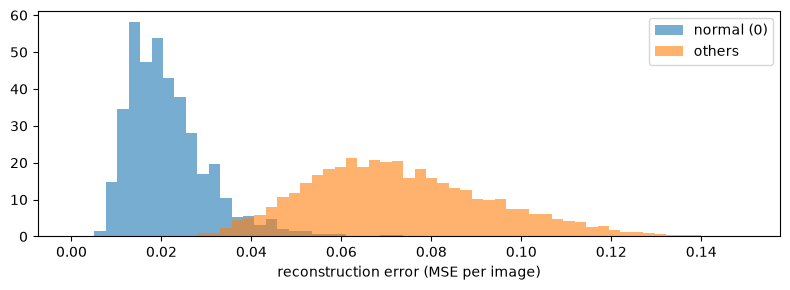

In [21]:
# 정상 = 숫자 0 (학습 데이터 6만 장에서 0만 골라 학습 5,000 · 검증 나머지)
X0 = tr.data[tr.targets == 0].float().div(255).unsqueeze(1).to(device)  # 정상 = 숫자 0만
X0_tr, X0_val = X0[:5000], X0[5000:]                                    # 학습 · 검증
print("0 학습", len(X0_tr), "장 | 0 검증", len(X0_val), "장")           # 개수 확인
torch.manual_seed(0)                                                    # 같은 출발점
ae0 = train(AutoEncoder(32).to(device), X=X0_tr)                        # 0만 배운 AE


# 한 장마다 복원 오차 (평가 1만 장 · 숫자 0~9)
def err_each(model, X):                                         # 한 장마다 복원 오차
    return ((run(model, X) - X) ** 2).flatten(1).mean(1).cpu()  # (장 수,)


err_te = err_each(ae0, Xte)                                          # 평가 1만 장 (0~9)
for k in range(0, 10, 2):                                            # 두 숫자씩
    a, b = err_te[yte == k].median(), err_te[yte == k + 1].median()  # 숫자별 중앙값
    print(f"숫자 {k} 오차 중앙값 {a:.4f} | 숫자 {k + 1} {b:.4f}")    # 0이 가장 작아야


# 정상(0) · 이상(나머지) 오차 분포
plt.figure(figsize=(8, 3))                                                     # 분포 그림
bins = np.linspace(0, 0.15, 60)                                                # 같은 구간
plt.hist(err_te[yte == 0], bins, alpha=0.6, density=True, label="normal (0)")  # 정상
plt.hist(err_te[yte != 0], bins, alpha=0.6, density=True, label="others")      # 이상
plt.xlabel("reconstruction error (MSE per image)")                             # 가로축 이름
plt.legend()                                                                   # 범례
plt.tight_layout()                                                             # 간격 정리
plt.show()                                                                     # 그림 출력

**결과** · 예측 정답은 6 (중앙값 0.0529) — 둥근 고리가 0과 닮음 · 가장 큰 것은 1 (0.0906)

- `0 학습 5000 장 | 0 검증 923 장` — 라벨은 '0만 고르기'에만 씀 · 학습은 이상 예시 없이
- `숫자 0 오차 중앙값 0.0196 | 숫자 1 0.0906` — 정상(0)은 작고 1은 가장 큼
- `숫자 6 오차 중앙값 0.0529 | 숫자 7 0.0818` — 6이 이상 중 가장 작음 → 놓치기 쉬운 이상
- `숫자 8 오차 중앙값 0.0647 | 숫자 9 0.0702` — 분포 그림: 정상(파랑)은 0.01~0.04에 몰리고 나머지(주황)는 0.03~0.14로 넓게 퍼짐 · 0.03~0.05에서 겹침 → 임곗값이 필요

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">방법</th>
<th style="text-align: left;">차이</th>
<th style="text-align: left;">언제 쓰나</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;">복원 오차 이상 탐지 (오토인코더)</td>
<td style="text-align: left;">정상만으로 학습 · 이상 라벨 불필요</td>
<td style="text-align: left;">이상이 드물고 종류를 미리 알 수 없을 때 (불량 · 부정 거래 · 심전도)</td>
</tr>
<tr>
<td style="text-align: left;">분류 모델 (지도 학습)</td>
<td style="text-align: left;">정상 · 이상 라벨이 모두 많이 필요</td>
<td style="text-align: left;">이상의 종류가 정해져 있고 예시가 충분할 때</td>
</tr>
<tr>
<td style="text-align: left;">규칙 · 통계 (IQR · Z-score)</td>
<td style="text-align: left;">값 하나하나의 범위만 봄</td>
<td style="text-align: left;">단순한 수치 데이터 (위클리 페이퍼 01)</td>
</tr>
</tbody>
</table>

> ⚠️ **주의**
>
> - 학습 데이터에 이상이 섞이면 이상도 잘 복원해 버림
> - 정상 데이터만 골라 학습
> - 정상과 닮은 이상(6)은 놓치기 쉬움

> ✅ **한 줄 정리** · 정상만 배운 오토인코더는 처음 보는 입력을 잘 되돌리지 못하므로, 한 장마다 복원 오차가 크면 이상으로 본다.

**딥러닝 코드에서는**

- 미션 5 심화의 심전도(ECG) 이상 탐지와 같은 원리
- 정상 신호만 학습 → 복원 오차가 큰 신호를 이상으로

### 5-2. `A` 임곗값 낮게 vs 높게 · 정밀도 · 재현율 (보강) · `torch.quantile` · `confusion_matrix` <sub>보강 · 머신러닝-3 평가 지표</sub>

> 🎯 **복원 오차가 얼마보다 크면 이상이라고 할지, 임곗값은 어떻게 정하는가?**

💡 **쉽게 말하면**

- 공항 검색대의 **민감도 조절**.
- 낮게 두면 이상한 짐은 다 잡지만 멀쩡한 짐도 자주 열고, 높게 두면 덜 귀찮지만 놓치는 짐이 생김.

<img src="images/ae2_threshold.png" alt="임곗값을 낮추면 재현율, 높이면 정밀도" width="689">

**실행 흐름**

1. 정상 검증 923장 오차의 90% · 99% 지점 = 임곗값
2. 시험 세트 (평가 0 전체 + 다른 숫자 20장씩)
3. 혼동 행렬
4. 정밀도 · 재현율

**먼저 예측** · 임곗값을 90% → 99%로 높이면 정밀도와 재현율은? — 답은 코드 실행 결과 아래에

In [22]:
# 임곗값의 재료: 정상 검증 이미지의 오차 (평가 이미지는 안 씀)
err_val = err_each(ae0, X0_val)  # 정상 검증 오차


# 시험 세트: 평가 0 전체 + 다른 숫자 20장씩 (이상 약 16%)
g = torch.Generator().manual_seed(0)                                 # 뽑기 고정
idx = [torch.where(yte == 0)[0]]                                     # 평가 0 전체
for k in range(1, 10):                                               # 다른 숫자마다
    pool = torch.where(yte == k)[0]                                  # 그 숫자의 번호들
    idx.append(pool[torch.randperm(len(pool), generator=g)[:20]])    # 20장만
idx = torch.cat(idx)                                                 # 시험 세트 번호
y_true = (yte[idx] != 0).int()                                       # 이상 = 1 (양성)
e_test = err_te[idx]                                                 # 시험 세트 오차
print(f"시험 세트 {len(idx)}장 | 정상 {(y_true == 0).sum().item()}"  # 구성 확인
      f" | 이상 {y_true.sum().item()}")


# 임곗값 낮게 (검증 오차 90%) vs 높게 (99%)
def judge(q):                                                # 분위수 q → 판정 결과
    th = torch.quantile(err_val, q).item()                   # 정상 검증으로 임곗값
    pred = (e_test > th).int()                               # 오차가 임곗값보다 크면 이상
    tn, fp, fn, tp = confusion_matrix(y_true, pred).ravel()  # 혼동 행렬 네 칸
    return th, tp, fp, fn, tn                                # 6장에서도 씀


for q in [0.90, 0.99]:                                                    # 낮게 · 높게
    th, tp, fp, fn, tn = judge(q)                                         # 판정
    print(f"임곗값 {q:.0%} = {th:.4f} | TP {tp} FP {fp} FN {fn} TN {tn}"  # 정밀도 · 재현율까지
          f" | 정밀도 {tp / (tp + fp):.3f} | 재현율 {tp / (tp + fn):.3f}")

시험 세트 1160장 | 정상 980 | 이상 180
임곗값 90% = 0.0318 | TP 179 FP 116 FN 1 TN 864 | 정밀도 0.607 | 재현율 0.994
임곗값 99% = 0.0458 | TP 160 FP 21 FN 20 TN 959 | 정밀도 0.884 | 재현율 0.889


**결과** · 예측 정답은 정밀도 0.607 → 0.884로 오르고 재현율 0.994 → 0.889로 내려감 — 하나를 얻으면 하나를 잃음

- `시험 세트 1160장 | 정상 980 | 이상 180` — 이상 약 16% (실제처럼 이상이 적게)
- `임곗값 90% = 0.0318 | TP 179 FP 116 FN 1 TN 864 | 정밀도 0.607 | 재현율 0.994` — 이상 180장 중 179장을 잡지만 정상 116장을 잘못 경보
- `임곗값 99% = 0.0458 | TP 160 FP 21 FN 20 TN 959 | 정밀도 0.884 | 재현율 0.889` — 잘못된 경보는 21장으로 줄고 놓친 이상은 20장으로 늘어남

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">방법</th>
<th style="text-align: left;">차이</th>
<th style="text-align: left;">언제 쓰나</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;">임곗값 낮게 (90%)</td>
<td style="text-align: left;">작은 오차도 이상으로 → 재현율 ↑ · 정밀도 ↓ (잘못된 경보 많음)</td>
<td style="text-align: left;">놓치면 큰일일 때 (의료 · 안전) · 사람이 한 번 더 볼 수 있을 때</td>
</tr>
<tr>
<td style="text-align: left;">임곗값 높게 (99%)</td>
<td style="text-align: left;">확실한 것만 이상으로 → 정밀도 ↑ · 재현율 ↓ (놓침 증가)</td>
<td style="text-align: left;">잘못된 경보 비용이 클 때 (자동 차단 · 알림 피로)</td>
</tr>
<tr>
<td style="text-align: left;">정밀도 TP / (TP + FP)</td>
<td style="text-align: left;">이상이라고 한 것 중 진짜 이상</td>
<td style="text-align: left;">경보를 믿을 수 있는가</td>
</tr>
<tr>
<td style="text-align: left;">재현율 TP / (TP + FN)</td>
<td style="text-align: left;">진짜 이상 중 잡아낸 것</td>
<td style="text-align: left;">놓치지 않았는가</td>
</tr>
</tbody>
</table>

> ⚠️ **주의**
>
> - 임곗값은 **정상 검증 데이터**로 정함
> - 시험 세트로 정하면 시험지를 보고 답을 고르는 셈
> - 시험 세트의 이상 비율이 바뀌면 정밀도도 바뀜

> ✅ **한 줄 정리** · 임곗값은 정상 검증 오차의 분위수로 정하고, 낮추면 재현율이 높이면 정밀도가 오르므로 놓침과 잘못된 경보 중 더 비싼 쪽을 보고 고른다.

**딥러닝 코드에서는**

- 분류 모델의 확률 임곗값 0.5를 옮기는 것과 같은 원리 (머신러닝-3 정리본의 임곗값 · 지표)

---
## 6. 종합 실습 · 노이즈 세기 3단계 DAE · 이상 탐지 결과표

> **이 장의 흐름** · 1장(입력만 바꾸는 DAE · 노이즈 세기) · 3장(같은 평가 · 기준선) · 5장(임곗값 · 정밀도 · 재현율)을 한 번에 사용

**파이프라인 위치** · ③ 학습 → ④ 평가 → ⑥ 활용

> 🎯 **노이즈 세기 0.1 · 0.3 · 0.6으로 학습한 DAE는 어떻게 다르고, 임곗값마다 이상 탐지 결과는 어떻게 바뀌는가?**

💡 **쉽게 말하면**

- 이슬비 · 보통 비 · 폭우 사진으로 각각 보정 연습을 시킨 세 사람에게 같은 사진 네 종류를 줘 보고 점수표를 만듦.
- 이어서 검색대 민감도 네 단계의 결과를 한 표로 정리.

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">단계</th>
<th style="text-align: left;">하는 일</th>
<th style="text-align: left;">쓰는 것</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;">1</td>
<td style="text-align: left;">DAE 0.1 · 0.6 학습 (0.3은 1-2 모델 그대로 · 모두 같은 조건)</td>
<td style="text-align: left;">1-2 <code>dae_loss(s)</code> · 0장 <code>train</code></td>
</tr>
<tr>
<td style="text-align: left;">2</td>
<td style="text-align: left;">학습 세기 × 평가 세기(0.1 · 0.3 · 0.6 · 깨끗한 입력) MSE 표 + 노이즈 그대로 기준선</td>
<td style="text-align: left;">0장 <code>noisy_eval</code> · <code>mse</code></td>
</tr>
<tr>
<td style="text-align: left;">3</td>
<td style="text-align: left;">노이즈 0.6 입력을 세 모델에 넣은 그림</td>
<td style="text-align: left;">0장 <code>show</code></td>
</tr>
<tr>
<td style="text-align: left;">4</td>
<td style="text-align: left;">임곗값 80 · 90 · 95 · 99% → TP · FP · FN · TN · 정밀도 · 재현율 · F1</td>
<td style="text-align: left;">5-2 <code>judge</code> · <code>f1_score</code></td>
</tr>
<tr>
<td style="text-align: left;">5</td>
<td style="text-align: left;">임곗값 95%에서 숫자별 '이상' 판정 비율</td>
<td style="text-align: left;">5-1 <code>err_te</code></td>
</tr>
</tbody>
</table>

**먼저 예측** · 답은 코드 실행 결과 아래에

1. 노이즈 0.6 입력에 가장 좋은 DAE는?
2. F1이 가장 높은 임곗값은?

DAE 0.1 학습
  epoch 1  loss 0.0653


  epoch 5  loss 0.0276


  epoch 10  loss 0.0169
DAE 0.6 학습
  epoch 1  loss 0.0656


  epoch 5  loss 0.0395


  epoch 10  loss 0.0277
평가 →         0.1     0.3     0.6   clean
노이즈 그대로 0.0054  0.0466  0.1502  0.0000
DAE 0.1 학습  0.0199  0.0888  0.1137  0.0361
DAE 0.3 학습  0.0376  0.0250  0.0698  0.0445
DAE 0.6 학습  0.0470  0.0398  0.0330  0.0497


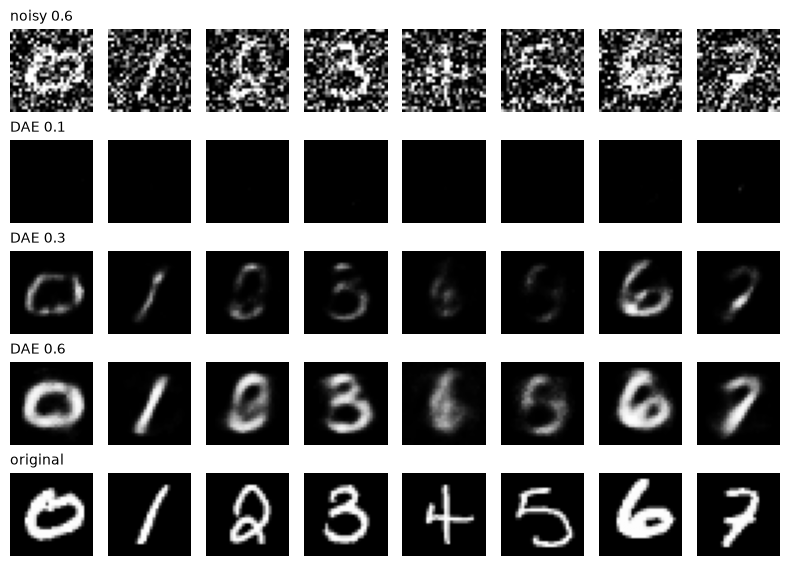

In [23]:
# 노이즈 세기 3단계 DAE (0.3은 1-2 모델 그대로 · 모두 같은 조건)
daes = {0.3: dae}                                # 0.3은 1-2 모델 재사용
for s in [0.1, 0.6]:                             # 새로 학습할 세기
    print(f"DAE {s} 학습")                       # 어느 학습인지
    torch.manual_seed(0)                         # 같은 출발점
    daes[s] = train(AutoEncoder(32).to(device),  # 세기만 다름
                    loss_fn=lambda m, x, s=s: dae_loss(m, x, s))


# 학습 세기 × 평가 세기 MSE 표 (+ 깨끗한 입력)
tests = {"0.1": noisy_eval(0.1), "0.3": Xn, "0.6": noisy_eval(0.6),         # 평가 시험지 네 가지
         "clean": Xte}
print("평가 →      " + "  ".join(f"{k:>6}" for k in tests))                 # 표 머리
print("노이즈 그대로 " + "  ".join(f"{mse(v):.4f}" for v in tests.values()))  # 기준선 줄
for s in [0.1, 0.3, 0.6]:                                                   # 학습 세기마다
    row = "  ".join(f"{mse(run(daes[s], v)):.4f}" for v in tests.values())  # 네 시험지 점수
    print(f"DAE {s} 학습  {row}")                                           # 표 한 줄
show([("noisy 0.6", tests["0.6"])]                                          # 가장 센 노이즈로 그림
     + [(f"DAE {s}", run(daes[s], tests["0.6"])) for s in [0.1, 0.3, 0.6]]
     + [("original", Xte)])

In [24]:
# 이상 탐지 결과표: 임곗값 네 가지 (5-2와 같은 시험 세트)
print("임곗값   값      TP  FP  FN  TN  정밀도  재현율   F1")      # 표 머리
for q in [0.80, 0.90, 0.95, 0.99]:                                 # 임곗값 네 가지
    th, tp, fp, fn, tn = judge(q)                                  # 5-2 함수
    f1 = f1_score(y_true, (e_test > th).int())                     # 정밀도 · 재현율 조화 평균
    print(f"{q:>5.0%}  {th:.4f}  {tp:>3} {fp:>3} {fn:>3} {tn:>3}"  # 표 한 줄
          f"   {tp / (tp + fp):.3f}   {tp / (tp + fn):.3f}  {f1:.3f}")


# 임곗값 95%에서 숫자별 '이상' 판정 비율 (평가 이미지 전체)
th95 = judge(0.95)[0]                                                             # 95% 임곗값
rate = [(err_te[yte == k] > th95).float().mean().item() for k in range(10)]       # 숫자별 판정 비율
print("숫자별 이상 판정:", " ".join(f"{k}:{r:.0%}" for k, r in enumerate(rate)))  # 0은 낮아야

임곗값   값      TP  FP  FN  TN  정밀도  재현율   F1
  80%  0.0259  180 236   0 744   0.433   1.000  0.604
  90%  0.0318  179 116   1 864   0.607   0.994  0.754
  95%  0.0370  175  63   5 917   0.735   0.972  0.837
  99%  0.0458  160  21  20 959   0.884   0.889  0.886
숫자별 이상 판정: 0:6% 1:100% 2:100% 3:100% 4:100% 5:97% 6:89% 7:100% 8:99% 9:100%


**결과** · 예측 정답은 ① **DAE 0.6** (0.0330) ② **99%** (F1 0.886)

- ① 열마다 학습 세기 = 평가 세기인 칸이 가장 작음 · 그림도 DAE 0.6 줄이 가장 또렷 (0 · 1 · 3 · 6 · 7)
- ① DAE 0.3 줄은 희미, DAE 0.1 줄은 거의 까만 판
- ② 이번 시험 세트(이상 약 16%)에서는 잘못된 경보를 줄인 쪽이 균형이 가장 좋음
- `노이즈 그대로 0.0054 0.0466 0.1502 0.0000` — 기준선 · 세기 0.1에서는 어떤 모델보다 '그대로 두기'가 나음
- `DAE 0.1 학습 0.0199 0.0888 0.1137 0.0361` — 약하게만 배우면 센 노이즈에서 무너짐
- `DAE 0.3 학습 0.0376 0.0250 0.0698 0.0445` — 1-2 모델 · 0.3 열에서 가장 작음
- `DAE 0.6 학습 0.0470 0.0398 0.0330 0.0497` — 0.6 열에서 가장 작음 · 약한 쪽에서도 크게 무너지지 않음
- `80% 0.0259 180 236 0 744 0.433 1.000 0.604` — 이상은 하나도 안 놓치지만 정상 236장에 경보
- `95% 0.0370 175 63 5 917 0.735 0.972 0.837` — 놓침 5장 · 잘못된 경보 63장
- `99% 0.0458 160 21 20 959 0.884 0.889 0.886` — 넷 중 F1이 가장 큼 (이 시험 세트 기준)
- `0:6% 1:100% 2:100% 3:100% 4:100% 5:97% 6:89%` — 정상 0의 6%는 잘못된 경보 · 0과 닮은 6은 11%를 놓침

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">방법</th>
<th style="text-align: left;">차이</th>
<th style="text-align: left;">언제 쓰나</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;">학습 세기 = 평가 세기</td>
<td style="text-align: left;">열마다 가장 작은 MSE</td>
<td style="text-align: left;">실제 손상 세기를 알 때</td>
</tr>
<tr>
<td style="text-align: left;">센 세기로 학습</td>
<td style="text-align: left;">약한 손상 · 깨끗한 입력엔 덜 정확하지만 크게 무너지지 않음</td>
<td style="text-align: left;">손상 세기를 모를 때 · 여러 세기를 섞어 학습하는 것도 방법</td>
</tr>
<tr>
<td style="text-align: left;">약한 세기로 학습</td>
<td style="text-align: left;">센 손상에서 크게 무너짐</td>
<td style="text-align: left;">실제 손상이 늘 약할 때만</td>
</tr>
<tr>
<td style="text-align: left;">임곗값 95%</td>
<td style="text-align: left;">재현율 0.972 · 정밀도 0.735</td>
<td style="text-align: left;">놓침을 줄이는 것이 더 중요할 때</td>
</tr>
<tr>
<td style="text-align: left;">임곗값 99%</td>
<td style="text-align: left;">정밀도 0.884 · 재현율 0.889 · F1 최대</td>
<td style="text-align: left;">이번 시험 세트에서 균형이 가장 좋을 때 (이상 비율이 바뀌면 다시 고름)</td>
</tr>
</tbody>
</table>

> ⚠️ **주의**
>
> - 세기 0.1처럼 손상이 약하면 모델보다 '그대로 두기'가 나을 수 있음
> - F1이 가장 큰 임곗값은 시험 세트의 이상 비율에 따라 바뀜

> ✅ **한 줄 정리** · DAE는 실제 손상 세기로 학습할 때 가장 잘 동작하고, 이상 탐지 임곗값은 놓침과 잘못된 경보의 비용을 보고 고른다.

**딥러닝 코드에서는**

- 미션 5의 문서 복원(손상 → 깨끗한 문서)이 1 · 2장과 같은 흐름
- 심화의 심전도 이상 탐지(정상만 학습 → 복원 오차 → 임곗값)가 5장 · 6장과 같은 흐름

---
## 그래서 오늘 무엇을 배웠는가?

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">학습 목표</th>
<th style="text-align: left;">할 수 있게 된 것</th>
<th style="text-align: left;">확인 위치</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;">1. 노이즈 제거</td>
<td style="text-align: left;">입력만 망가뜨린 DAE · 세기 0.3에서 0.0306 → 0.0250 · 연습 안 한 손상 · 세기에는 약함</td>
<td style="text-align: left;">1장</td>
</tr>
<tr>
<td style="text-align: left;">2. 짝 · 분리 · 크기</td>
<td style="text-align: left;">어긋난 짝은 한 가지 밝기(0.009) · 문서 번호로 분리 · 130×270 → 132×272를 채우고 자름</td>
<td style="text-align: left;">2장</td>
</tr>
<tr>
<td style="text-align: left;">3. 복원 평가</td>
<td style="text-align: left;">흰 종이 0.285 · 손상 0.154 · 모델 0.070 · 글자 칸은 0.069 → 0.156으로 나빠짐</td>
<td style="text-align: left;">3장</td>
</tr>
<tr>
<td style="text-align: left;">4. 실험 설계</td>
<td style="text-align: left;">seed 흔들림 0.0030보다 큰 차이만 효과 · 둘 다 바꾸면 원인을 모름</td>
<td style="text-align: left;">4장</td>
</tr>
<tr>
<td style="text-align: left;">5. 이상 탐지</td>
<td style="text-align: left;">0만 학습 → 6이 가장 헷갈림 · 임곗값 90% vs 99%의 정밀도 · 재현율</td>
<td style="text-align: left;">5장 · 6장</td>
</tr>
</tbody>
</table>

### 주제별 한 줄 · 반드시 기억할 것

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: center;">등급</th>
<th style="text-align: left;">주제</th>
<th style="text-align: left;">반드시 기억할 것</th>
<th style="text-align: left;">딥러닝 코드에서</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: center;"><code>A</code></td>
<td style="text-align: left;">Denoising AE</td>
<td style="text-align: left;">구조 그대로 · 입력만 망가뜨리고 정답은 깨끗하게</td>
<td style="text-align: left;"><code>F.mse_loss(model(noisy), x)</code></td>
</tr>
<tr>
<td style="text-align: center;"><code>A</code></td>
<td style="text-align: left;">노이즈 세기</td>
<td style="text-align: left;">실제 손상 세기로 학습 · 약하면 '그대로 두기'와 비교</td>
<td style="text-align: left;">데이터 증강 세기</td>
</tr>
<tr>
<td style="text-align: center;"><code>A</code></td>
<td style="text-align: left;">짝 맞추기</td>
<td style="text-align: left;">같은 문서 · 같은 자리 · 에러 없이 틀릴 수 있음</td>
<td style="text-align: left;">이미지 · 라벨 정렬 확인</td>
</tr>
<tr>
<td style="text-align: center;"><code>A</code></td>
<td style="text-align: left;">문서 단위 분리</td>
<td style="text-align: left;">묶음으로 먼저 나누고 번호로 겹침 확인</td>
<td style="text-align: left;"><code>GroupShuffleSplit</code></td>
</tr>
<tr>
<td style="text-align: center;"><code>A</code></td>
<td style="text-align: left;">크기 맞추기</td>
<td style="text-align: left;">층마다 모양 · 4의 배수로 채우고 잘라냄</td>
<td style="text-align: left;"><code>np.pad</code> · <code>out[..., :h, :w]</code></td>
</tr>
<tr>
<td style="text-align: center;"><code>A</code></td>
<td style="text-align: left;">기준선 · RMSE · PSNR</td>
<td style="text-align: left;">아무것도 안 한 답 옆에 · PSNR은 클수록</td>
<td style="text-align: left;">평가 표의 첫 줄</td>
</tr>
<tr>
<td style="text-align: center;"><code>A</code></td>
<td style="text-align: left;">중요한 부분 · 그림</td>
<td style="text-align: left;">글자 칸은 정답으로 · 평균이 가릴 수 있음</td>
<td style="text-align: left;">클래스별 지표</td>
</tr>
<tr>
<td style="text-align: center;"><code>A</code></td>
<td style="text-align: left;">하나만 바꾸기</td>
<td style="text-align: left;">흔들림(seed)보다 큰 차이만 효과</td>
<td style="text-align: left;">ablation study</td>
</tr>
<tr>
<td style="text-align: center;"><code>A</code></td>
<td style="text-align: left;">이상 탐지 (보강)</td>
<td style="text-align: left;">정상만 학습 → 한 장마다 복원 오차</td>
<td style="text-align: left;">불량 · 심전도 이상</td>
</tr>
<tr>
<td style="text-align: center;"><code>A</code></td>
<td style="text-align: left;">임곗값 (보강)</td>
<td style="text-align: left;">정상 검증 분위수 · 낮게=재현율 · 높게=정밀도</td>
<td style="text-align: left;">경보 민감도</td>
</tr>
<tr>
<td style="text-align: center;"><code>B</code></td>
<td style="text-align: left;">가림 손상</td>
<td style="text-align: left;">연습한 손상만 잘 고침</td>
<td style="text-align: left;">Masked Autoencoder</td>
</tr>
<tr>
<td style="text-align: center;"><code>B</code></td>
<td style="text-align: left;">Sparse AE · VAE</td>
<td style="text-align: left;">요구를 더하면 하는 일이 바뀌고 대가가 있음</td>
<td style="text-align: left;">규제 항 · 생성 모델</td>
</tr>
</tbody>
</table>

---
## 기억 확인 문제

위 내용을 **보지 않고** 답한 뒤, ✅ 한 줄 정리와 비교해 ○ (정확) · △ (일부) · × (모름)를 표시. △ · ×인 섹션만 다시 보기.

### 1. 질문에 답하기

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">섹션</th>
<th style="text-align: left;">🎯 질문</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;">1-2</td>
<td style="text-align: left;">노이즈를 지우게 하려면 학습 루프에서 무엇을 바꾸는가?</td>
</tr>
<tr>
<td style="text-align: left;">1-3</td>
<td style="text-align: left;">학습 때보다 약한 · 센 노이즈가 들어오면 DAE는?</td>
</tr>
<tr>
<td style="text-align: left;">1-4</td>
<td style="text-align: left;">노이즈로 배운 DAE가 가림 손상을 잘 못 채우는 이유는?</td>
</tr>
<tr>
<td style="text-align: left;">2-1</td>
<td style="text-align: left;">짝이 어긋난 채 학습하면 출력은 어떻게 되는가?</td>
</tr>
<tr>
<td style="text-align: left;">2-2</td>
<td style="text-align: left;">조각을 섞어 나누면 왜 안 되는가?</td>
</tr>
<tr>
<td style="text-align: left;">2-3</td>
<td style="text-align: left;">130×270 문서를 넣으면 몇이 나오고, 어떻게 맞추는가?</td>
</tr>
<tr>
<td style="text-align: left;">3-1</td>
<td style="text-align: left;">문서 RMSE 0.070을 읽으려면 무엇이 옆에 있어야 하는가?</td>
</tr>
<tr>
<td style="text-align: left;">3-2</td>
<td style="text-align: left;">전체 점수가 좋아졌는데 글자가 나빠질 수 있는 이유는?</td>
</tr>
<tr>
<td style="text-align: left;">4-2</td>
<td style="text-align: left;">바꾼 것의 효과라고 말하려면 실험을 어떻게 하는가?</td>
</tr>
<tr>
<td style="text-align: left;">5-1</td>
<td style="text-align: left;">정상만 배운 오토인코더로 이상을 찾는 원리는?</td>
</tr>
<tr>
<td style="text-align: left;">5-2</td>
<td style="text-align: left;">임곗값을 높이면 정밀도와 재현율은 어떻게 되는가?</td>
</tr>
<tr>
<td style="text-align: left;">6</td>
<td style="text-align: left;">노이즈 세기를 모를 때 어느 세기로 학습하는 편이 안전했나?</td>
</tr>
</tbody>
</table>

#### 내 답 · 이 셀을 더블클릭해서 작성

**1-2** · (여기에 답 작성) · ○ △ × 중 하나만 남기기

**1-3** · (여기에 답 작성) · ○ △ × 중 하나만 남기기

**1-4** · (여기에 답 작성) · ○ △ × 중 하나만 남기기

**2-1** · (여기에 답 작성) · ○ △ × 중 하나만 남기기

**2-2** · (여기에 답 작성) · ○ △ × 중 하나만 남기기

**2-3** · (여기에 답 작성) · ○ △ × 중 하나만 남기기

**3-1** · (여기에 답 작성) · ○ △ × 중 하나만 남기기

**3-2** · (여기에 답 작성) · ○ △ × 중 하나만 남기기

**4-2** · (여기에 답 작성) · ○ △ × 중 하나만 남기기

**5-1** · (여기에 답 작성) · ○ △ × 중 하나만 남기기

**5-2** · (여기에 답 작성) · ○ △ × 중 하나만 남기기

**6** · (여기에 답 작성) · ○ △ × 중 하나만 남기기

### 2. 코드로 답하기

아래 빈 셀에 직접 작성 후 실행.

1. 0~1 값 텐서 `x = torch.tensor([0.0, 0.5, 1.0])`에 `[-0.4, 0.2, 0.3]`을 더하고 0~1로 자른 결과
2. 정답 `[0.0, 1.0, 1.0, 1.0]` · 출력 `[0.2, 1.0, 1.0, 1.0]`의 RMSE와 PSNR(소수 첫째 자리)
3. 정답 `c = np.array([0.1, 0.9, 0.2, 0.95])`에서 글자 칸(0.5보다 어두운 칸)의 개수
4. TP 30 · FP 10 · FN 20일 때 정밀도와 재현율

In [25]:
# 코드 문제 직접 작성

### 3. 변형 문제 · 조건을 바꿔 다시 풀기

1. 6장 표의 95% 줄(TP 175 · FP 63 · FN 5)로 정밀도 · 재현율을 손으로 구하고 표의 값과 맞추기
2. 세로 132 · 가로 268 문서를 2장 문서 모델에 넣으면 나오는 크기는? 채우기가 필요한가?
3. 문서 RMSE가 0.1일 때와 0.05일 때의 PSNR(dB)은? RMSE를 반으로 줄이면 PSNR은 얼마나 오르나?

In [26]:
# 변형 문제 직접 작성

### 4. 모범 답안 · 1 ~ 3을 다 푼 뒤에 보기

#### 질문 답

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">섹션</th>
<th style="text-align: left;">답</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;">1-2</td>
<td style="text-align: left;">구조는 그대로, 입력만 노이즈 낀 숫자로 · 정답은 깨끗한 원본 <code>F.mse_loss(model(noisy), x)</code></td>
</tr>
<tr>
<td style="text-align: left;">1-3</td>
<td style="text-align: left;">약하면 '그대로 두기'보다 나빠지고, 세면 뭉개짐 → 실제 손상 세기로 학습</td>
</tr>
<tr>
<td style="text-align: left;">1-4</td>
<td style="text-align: left;">연습한 적 없는 손상이라서. 가림은 정보가 아예 없는 칸이라 채우는 연습이 따로 필요</td>
</tr>
<tr>
<td style="text-align: left;">2-1</td>
<td style="text-align: left;">정답이 엉뚱한 자리라 평균 밝기 한 가지 판이 나옴 (조각 안 표준편차 0.009) · 에러는 없음</td>
</tr>
<tr>
<td style="text-align: left;">2-2</td>
<td style="text-align: left;">같은 문서가 학습 · 평가 양쪽에 들어가 '처음 보는 데이터' 점수가 아니게 됨 → 문서 번호로 먼저 나눔</td>
</tr>
<tr>
<td style="text-align: left;">2-3</td>
<td style="text-align: left;">132×272 (65 · 135가 홀수) → 4의 배수로 채워 넣고 원래 크기로 잘라냄</td>
</tr>
<tr>
<td style="text-align: left;">3-1</td>
<td style="text-align: left;">기준선 (흰 종이 0.285 · 손상 그대로 0.154)</td>
</tr>
<tr>
<td style="text-align: left;">3-2</td>
<td style="text-align: left;">넓은 배경(약 90%)의 개선이 평균을 끌어내려 좁은 글자 칸의 악화를 가림</td>
</tr>
<tr>
<td style="text-align: left;">4-2</td>
<td style="text-align: left;">요인 하나만 바꾸고 나머지 · 평가는 그대로, 차이를 seed 흔들림과 비교</td>
</tr>
<tr>
<td style="text-align: left;">5-1</td>
<td style="text-align: left;">정상만 배워 처음 보는 입력은 잘 못 되돌림 → 한 장마다 복원 오차가 크면 이상</td>
</tr>
<tr>
<td style="text-align: left;">5-2</td>
<td style="text-align: left;">정밀도 ↑ · 재현율 ↓ (잘못된 경보는 줄고 놓침은 늘어남)</td>
</tr>
<tr>
<td style="text-align: left;">6</td>
<td style="text-align: left;">센 세기(0.6) — 약한 쪽에선 덜 정확해도 크게 무너지지 않음</td>
</tr>
</tbody>
</table>

#### 코드 문제 답

```python
import numpy as np
import torch

# 1. 더하고 0~1로 자르기
x = torch.tensor([0.0, 0.5, 1.0])
y = (x + torch.tensor([-0.4, 0.2, 0.3])).clamp(0, 1)
print([round(v, 2) for v in y.tolist()])  # [0.0, 0.7, 1.0]

# 2. MSE = 0.04 / 4 = 0.01 → RMSE 0.1 · PSNR 10 × log10(1 / 0.01) = 20
c, o = np.array([0.0, 1.0, 1.0, 1.0]), np.array([0.2, 1.0, 1.0, 1.0])
m = np.square(o - c).mean()
rmse, psnr = float(np.sqrt(m)), float(10 * np.log10(1 / m))
print(round(rmse, 3), round(psnr, 1))  # 0.1 20.0

# 3. 글자 칸 = 0.5보다 어두운 칸
c = np.array([0.1, 0.9, 0.2, 0.95])
print(int((c < 0.5).sum()))  # 2

# 4. 정밀도 = 30 / 40 · 재현율 = 30 / 50
tp, fp, fn = 30, 10, 20
print(tp / (tp + fp), tp / (tp + fn))  # 0.75 0.6
```

#### 변형 문제 답

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">문제</th>
<th style="text-align: left;">답</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;">1</td>
<td style="text-align: left;">정밀도 175 ÷ 238 = 0.735 · 재현율 175 ÷ 180 = 0.972 (표와 같음)</td>
</tr>
<tr>
<td style="text-align: left;">2</td>
<td style="text-align: left;">132 → 66 → 33 → 66 → 132 · 268 → 134 → 67 → 134 → 268 → 그대로 (둘 다 4의 배수라 채우기 불필요)</td>
</tr>
<tr>
<td style="text-align: left;">3</td>
<td style="text-align: left;">10 × log10(1 ÷ 0.01) = 20 dB · 10 × log10(1 ÷ 0.0025) = 26.0 dB → RMSE를 반으로 줄이면 약 6 dB 오름</td>
</tr>
</tbody>
</table>

---
## 오답 노트

틀린 문제는 정답을 베끼지 말고 **원인**을 적음. 다음 복습 때 "재발 방지 질문"부터 스스로에게 물어보기.

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">틀린 내용</th>
<th style="text-align: left;">틀린 이유</th>
<th style="text-align: left;">올바른 원칙</th>
<th style="text-align: left;">재발 방지 질문</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;">(예) 전체 RMSE가 줄었으니 글자도 좋아졌다고 답함</td>
<td style="text-align: left;">넓은 배경이 평균을 끌어내린 것을 못 봄</td>
<td style="text-align: left;">중요한 부분을 따로 재고 그림으로 확인</td>
<td style="text-align: left;">이 점수는 어느 칸이 지배하나?</td>
</tr>
<tr>
<td style="text-align: left;"></td>
<td style="text-align: left;"></td>
<td style="text-align: left;"></td>
<td style="text-align: left;"></td>
</tr>
<tr>
<td style="text-align: left;"></td>
<td style="text-align: left;"></td>
<td style="text-align: left;"></td>
<td style="text-align: left;"></td>
</tr>
</tbody>
</table>

---
## 면접 30초 답변

**Q1. Denoising Autoencoder는 일반 오토인코더와 무엇이 다른가요?**
> - 구조는 같고 학습 데이터의 짝만 다릅니다.
> - 입력에는 노이즈나 가림 같은 손상을 입히고 정답에는 깨끗한 원본을 두어, 손상을 지우는 법을 배우게 합니다.
> - 연습한 손상에는 강하지만 깨끗한 입력이나 다른 종류의 손상에는 오히려 약할 수 있어서, 실제 들어올 손상에 맞춰 학습시킵니다.

**Q2. 복원 모델의 성능은 무엇으로 평가하나요?**
> - RMSE나 PSNR로 원본과의 차이를 재는데, 숫자는 흰 종이나 손상 그대로 같은 기준선 옆에 놓아야 의미가 있습니다.
> - 또 문서처럼 중요한 부분이 좁으면 전체 평균이 그 부분의 악화를 가릴 수 있어, 글자 칸만 따로 재고 확대 그림과 가장 나쁜 샘플을 눈으로 함께 확인합니다.

**Q3. 실험에서 성능이 좋아졌다는 것을 어떻게 확인하나요?**
> - 요인 하나만 바꾸고 데이터
> - 평가 방법은 그대로 둡니다.
> - 그리고 설정을 바꾸지 않고 seed만 바꿔 다시 학습했을 때의 흔들림을 재서, 바뀐 점수가 그 흔들림보다 클 때만 그 요인의 효과라고 말합니다.

**Q4. 오토인코더로 이상 탐지를 하는 원리와 임곗값은 어떻게 정하나요?**
> - 정상 데이터만으로 학습하면 처음 보는 이상 데이터는 잘 복원하지 못해 복원 오차가 커집니다.
> - 임곗값은 정상 검증 데이터의 오차 분포에서 분위수로 정하고, 낮추면 재현율이 높이면 정밀도가 오르므로 놓침과 잘못된 경보 중 어느 비용이 큰지 보고 고릅니다.

---
## 최종 요약표

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">함수·문법</th>
<th style="text-align: left;">소속</th>
<th style="text-align: left;">역할</th>
<th style="text-align: left;">코드에서 사용한 위치</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;"><code>torch.randn_like</code> · <code>torch.randn(generator=)</code></td>
<td style="text-align: left;">torch</td>
<td style="text-align: left;">가우시안 노이즈 (학습용 · 평가 고정용)</td>
<td style="text-align: left;">1-2 <code>torch.randn_like(x)</code> · 0 <code>torch.randn(tuple(Xte.shape), generator=g)</code></td>
</tr>
<tr>
<td style="text-align: left;"><code>torch.Generator().manual_seed()</code></td>
<td style="text-align: left;">torch</td>
<td style="text-align: left;">전용 난수 · 장치와 상관없이 같은 값</td>
<td style="text-align: left;">0 <code>g = torch.Generator().manual_seed(seed)</code></td>
</tr>
<tr>
<td style="text-align: left;"><code>.clamp(0, 1)</code> · <code>.clone()</code></td>
<td style="text-align: left;">Tensor</td>
<td style="text-align: left;">범위 자르기 · 원본 보호 복사</td>
<td style="text-align: left;">0 <code>(Xte + s * noise).clamp(0, 1)</code> · 1-4 <code>x = x.clone()</code></td>
</tr>
<tr>
<td style="text-align: left;"><code>F.mse_loss(model(noisy), x)</code></td>
<td style="text-align: left;">torch.nn.functional</td>
<td style="text-align: left;">DAE 손실 (입력 noisy · 정답 x)</td>
<td style="text-align: left;">1-2 <code>return F.mse_loss(model(noisy), x)</code></td>
</tr>
<tr>
<td style="text-align: left;"><code>x[:, :, 10:18, 10:18] = 0</code></td>
<td style="text-align: left;">Tensor 인덱싱</td>
<td style="text-align: left;">가운데 가림 손상</td>
<td style="text-align: left;">1-4 <code>x[:, :, 10:18, 10:18] = 0</code></td>
</tr>
<tr>
<td style="text-align: left;"><code>nn.Sequential.append</code> · <code>λ × z.sum()</code></td>
<td style="text-align: left;">torch.nn · 손실 식</td>
<td style="text-align: left;">층 덧붙이기 · 희소성 벌점</td>
<td style="text-align: left;">1-5 <code>self.encoder.append(nn.ReLU())</code> · <code>lam * z.sum(1).mean()</code></td>
</tr>
<tr>
<td style="text-align: left;"><code>PIL.Image.new</code> · <code>ImageDraw.text</code> · <code>ImageFont.load_default</code></td>
<td style="text-align: left;">PIL</td>
<td style="text-align: left;">연습용 문서 그리기</td>
<td style="text-align: left;">2-0a <code>img = PIL.Image.new("L", (w, h), 255)</code></td>
</tr>
<tr>
<td style="text-align: left;"><code>np.random.default_rng(seed)</code></td>
<td style="text-align: left;">numpy</td>
<td style="text-align: left;">좌표 · 손상 난수 (같은 seed → 같은 문서)</td>
<td style="text-align: left;">2-0a <code>rng = np.random.default_rng(seed)</code></td>
</tr>
<tr>
<td style="text-align: left;"><code>crop(clean, y, x)</code></td>
<td style="text-align: left;">내가 만든 함수</td>
<td style="text-align: left;">입력과 같은 자리의 정답 조각</td>
<td style="text-align: left;">2-1 <code>Y.append(crop(clean, y, x))</code></td>
</tr>
<tr>
<td style="text-align: left;"><code>set(a) &amp; set(b)</code></td>
<td style="text-align: left;">Python 기본 문법</td>
<td style="text-align: left;">학습 · 평가 번호 겹침 확인</td>
<td style="text-align: left;">2-2 <code>set(use_ids) &amp; set(eval_ids)</code></td>
</tr>
<tr>
<td style="text-align: left;"><code>np.pad(mode="edge")</code> · <code>out[:, :, :h, :w]</code></td>
<td style="text-align: left;">numpy · Tensor</td>
<td style="text-align: left;">4의 배수로 채우기 · 원래 크기로 자르기</td>
<td style="text-align: left;">2-3a <code>padded = np.pad(dirty_b, ((0, H4 - h), (0, W4 - w)…</code></td>
</tr>
<tr>
<td style="text-align: left;"><code>for k, layer in enumerate(model)</code></td>
<td style="text-align: left;">Python 기본 문법 · nn.Sequential</td>
<td style="text-align: left;">층마다 모양 찍기</td>
<td style="text-align: left;">2-3a <code>for k, layer in enumerate(model_A):</code></td>
</tr>
<tr>
<td style="text-align: left;"><code>np.sqrt(((o - c) ** 2).mean())</code></td>
<td style="text-align: left;">numpy</td>
<td style="text-align: left;">RMSE</td>
<td style="text-align: left;">3-1 <code>return float(np.mean([np.sqrt(((o - c) ** 2).mean())</code></td>
</tr>
<tr>
<td style="text-align: left;"><code>10 * np.log10(1 / mse)</code></td>
<td style="text-align: left;">numpy</td>
<td style="text-align: left;">PSNR (값 범위 0~1)</td>
<td style="text-align: left;">3-1 <code>return float(np.mean([10 * np.log10(1 / ((o - c) *…</code></td>
</tr>
<tr>
<td style="text-align: left;"><code>np.ones_like</code> · <code>np.full_like</code></td>
<td style="text-align: left;">numpy</td>
<td style="text-align: left;">흰 종이 · 평균 밝기 종이 (기준선)</td>
<td style="text-align: left;">3-1 <code>white = [np.ones_like(c) for c in eval_clean]</code></td>
</tr>
<tr>
<td style="text-align: left;"><code>clean &lt; 0.5</code></td>
<td style="text-align: left;">numpy 비교</td>
<td style="text-align: left;">글자 칸 마스크 (정답으로 만듦)</td>
<td style="text-align: left;">3-2 <code>return clean &lt; 0.5</code></td>
</tr>
<tr>
<td style="text-align: left;"><code>argsort(descending=True)[:3]</code></td>
<td style="text-align: left;">Tensor</td>
<td style="text-align: left;">오차가 가장 큰 조각 고르기</td>
<td style="text-align: left;">3-2 <code>worst = ((OA - EY) ** 2).mean((1, 2, 3)).argsort(d…</code></td>
</tr>
<tr>
<td style="text-align: left;"><code>train_doc(X, Y, seed=1)</code></td>
<td style="text-align: left;">내가 만든 함수</td>
<td style="text-align: left;">설정은 그대로 · seed만 바꿈</td>
<td style="text-align: left;">4-1 <code>s1 = evaluate(train_doc(X, Y_A, seed=1))</code></td>
</tr>
<tr>
<td style="text-align: left;"><code>train_doc(X, Y, epochs=20)</code> · <code>ch=(8, 16)</code></td>
<td style="text-align: left;">내가 만든 함수</td>
<td style="text-align: left;">요인 하나만 바꿈</td>
<td style="text-align: left;">4-2 <code>dict(epochs=20)</code> · <code>dict(ch=(8, 16))</code> → <code>train_doc(X, Y_A, **kw)</code></td>
</tr>
<tr>
<td style="text-align: left;"><code>dict(epochs=20)</code> · <code>**kw</code></td>
<td style="text-align: left;">Python 기본 문법</td>
<td style="text-align: left;">설정 묶음을 함수 인자로 풀어 넣기</td>
<td style="text-align: left;">4-2 <code>setups = {"에폭만 20": dict(epochs=20),</code></td>
</tr>
<tr>
<td style="text-align: left;"><code>f"{d - base[0]:+.4f}"</code></td>
<td style="text-align: left;">Python f-string</td>
<td style="text-align: left;">부호까지 찍는 차이</td>
<td style="text-align: left;">4-2 <code>({d - base[0]:+.4f})</code></td>
</tr>
<tr>
<td style="text-align: left;"><code>tr.data[tr.targets == 0]</code></td>
<td style="text-align: left;">Tensor 불리언 인덱싱</td>
<td style="text-align: left;">정상(숫자 0)만 고르기</td>
<td style="text-align: left;">5-1 <code>X0 = tr.data[tr.targets == 0].float().div(255).uns…</code></td>
</tr>
<tr>
<td style="text-align: left;"><code>((out - X) ** 2).flatten(1).mean(1)</code></td>
<td style="text-align: left;">Tensor</td>
<td style="text-align: left;">한 장마다 복원 오차</td>
<td style="text-align: left;">5-1 <code>((run(model, X) - X) ** 2).flatten(1).mean(1)</code></td>
</tr>
<tr>
<td style="text-align: left;"><code>torch.quantile(err_val, q)</code></td>
<td style="text-align: left;">torch</td>
<td style="text-align: left;">정상 검증 오차의 분위수 = 임곗값</td>
<td style="text-align: left;">5-2 <code>th = torch.quantile(err_val, q).item()</code></td>
</tr>
<tr>
<td style="text-align: left;"><code>confusion_matrix(y, pred).ravel()</code></td>
<td style="text-align: left;">sklearn.metrics</td>
<td style="text-align: left;">TN · FP · FN · TP</td>
<td style="text-align: left;">5-2 <code>tn, fp, fn, tp = confusion_matrix(y_true, pred).ra…</code></td>
</tr>
<tr>
<td style="text-align: left;"><code>f1_score</code></td>
<td style="text-align: left;">sklearn.metrics</td>
<td style="text-align: left;">정밀도와 재현율의 조화 평균</td>
<td style="text-align: left;">6-2 <code>f1 = f1_score(y_true, (e_test &gt; th).int())</code></td>
</tr>
</tbody>
</table>

### 할 것 · 하지 말 것

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">✅ 할 것</th>
<th style="text-align: left;">⚠️ 하지 말 것</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;">평가 노이즈 · 평가 데이터는 한 번 고정해 모든 모델에</td>
<td style="text-align: left;">모델마다 다른 시험지로 비교</td>
</tr>
<tr>
<td style="text-align: left;">학습 전에 짝 그림 몇 장 확인</td>
<td style="text-align: left;">loss가 내려간다고 짝이 맞다고 믿기</td>
</tr>
<tr>
<td style="text-align: left;">문서(묶음) 번호로 먼저 나누기</td>
<td style="text-align: left;">조각을 섞어 학습 · 평가로 나누기</td>
</tr>
<tr>
<td style="text-align: left;">점수는 기준선 옆에 · 중요한 부분 따로 · 그림까지</td>
<td style="text-align: left;">전체 평균 하나로 결론</td>
</tr>
<tr>
<td style="text-align: left;">요인 하나만 바꾸고 seed 흔들림과 비교</td>
<td style="text-align: left;">여러 개를 한꺼번에 바꾸고 원인 단정</td>
</tr>
<tr>
<td style="text-align: left;">임곗값은 정상 검증 데이터로</td>
<td style="text-align: left;">시험 세트를 보고 임곗값 고르기</td>
</tr>
</tbody>
</table>

### 헷갈리는 짝 한눈에 보기

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">짝</th>
<th style="text-align: left;">차이</th>
<th style="text-align: left;">결론</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;">일반 AE vs Denoising AE</td>
<td style="text-align: left;">입력 x vs 입력 망가뜨린 x (정답은 둘 다 깨끗한 x)</td>
<td style="text-align: left;">구조는 같고 입력만 다름</td>
</tr>
<tr>
<td style="text-align: left;">노이즈 약하게 vs 강하게</td>
<td style="text-align: left;">모델이 오히려 망침 vs 복원이 뭉개짐</td>
<td style="text-align: left;">학습 세기 = 실제 손상 세기</td>
</tr>
<tr>
<td style="text-align: left;">가우시안 vs 가림</td>
<td style="text-align: left;">조금씩 흐림 vs 통째로 지움</td>
<td style="text-align: left;">연습한 손상만 잘 고침</td>
</tr>
<tr>
<td style="text-align: left;">맞춘 짝 vs 어긋난 짝</td>
<td style="text-align: left;">같은 자리 vs 다른 자리 (에러 없음)</td>
<td style="text-align: left;">학습 전에 짝 그림부터</td>
</tr>
<tr>
<td style="text-align: left;">문서로 나누기 vs 조각 섞기</td>
<td style="text-align: left;">평가 문서 처음 봄 vs 이미 본 문서</td>
<td style="text-align: left;">묶음 단위로 먼저 나눔</td>
</tr>
<tr>
<td style="text-align: left;">채우고 자르기 vs 조각 이어 붙이기</td>
<td style="text-align: left;">경계 없음 vs 경계에 줄</td>
<td style="text-align: left;">메모리 되면 채우고 자르기</td>
</tr>
<tr>
<td style="text-align: left;">RMSE vs PSNR</td>
<td style="text-align: left;">작을수록 좋음 vs 클수록 좋음</td>
<td style="text-align: left;">기준선 옆에 함께 적음</td>
</tr>
<tr>
<td style="text-align: left;">픽셀 MSE vs 눈으로 보는 평가</td>
<td style="text-align: left;">전체 평균 vs 중요한 곳 · 흐림 · 잔상</td>
<td style="text-align: left;">숫자 → 그림 순서로 둘 다</td>
</tr>
<tr>
<td style="text-align: left;">하나만 바꾸기 vs 여러 개 한 번에</td>
<td style="text-align: left;">원인을 앎 vs 원인을 모름</td>
<td style="text-align: left;">차이는 seed 흔들림과 비교</td>
</tr>
<tr>
<td style="text-align: left;">임곗값 낮게 vs 높게</td>
<td style="text-align: left;">재현율 ↑ vs 정밀도 ↑</td>
<td style="text-align: left;">놓침과 잘못된 경보 중 더 비싼 쪽으로</td>
</tr>
</tbody>
</table>

---
## 다음 복습일

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">언제</th>
<th style="text-align: left;">할 일</th>
<th style="text-align: left;">걸리는 시간</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;">내일</td>
<td style="text-align: left;">기억 확인 문제 1을 자료 없이 다시 답하고 오답 노트 갱신</td>
<td style="text-align: left;">15분</td>
</tr>
<tr>
<td style="text-align: left;">3일 뒤</td>
<td style="text-align: left;">변형 문제 3개를 새로 풀기 · 3-2 글자 칸 결과를 가리고 이유를 말하기</td>
<td style="text-align: left;">20분</td>
</tr>
<tr>
<td style="text-align: left;">7일 뒤</td>
<td style="text-align: left;">2장 문서 복원을 직접 다시 짜서 짝 확인 → 분리 → 크기 맞추기 순서로 실행</td>
<td style="text-align: left;">40분</td>
</tr>
<tr>
<td style="text-align: left;">14일 뒤</td>
<td style="text-align: left;">오답 노트에 남은 문제만 다시 풀기 · 미션 5 시작 전 2 · 3 · 4장 ✅ 줄만 읽기</td>
<td style="text-align: left;">15분</td>
</tr>
</tbody>
</table>

---
## 부록

### 이 노트북을 만든 방법

- 손상된 입력을 깨끗하게 되돌리고, 복원이 잘됐는지 무엇으로 판단하는지를 **5개 대단원 · 14개 섹션**으로 정리.
- 2일차 강의(155쪽)
- 실습 P5 ~ P9의 빈칸을 모두 채워 실행으로 검증하고, 수업에 없는 **복원 오차 이상 탐지**를 보강(5장).
- 마지막 **종합 실습**에서 노이즈 세기 3단계 DAE와 이상 탐지 결과표를 만듦.
- 데이터는 MNIST(학습 1만 장 · 평가 1만 장)와 노트북 안에서 그리는 연습용 문서 32장.

### 읽는 법

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">표시</th>
<th style="text-align: left;">의미</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;"><code>A</code> · <code>B</code></td>
<td style="text-align: left;"><strong>A</strong> 딥러닝 코드에 바로 나오는 필수 · <strong>B</strong> 알아두면 되는 것</td>
</tr>
<tr>
<td style="text-align: left;">🎯</td>
<td style="text-align: left;">이번 섹션에서 답해야 할 질문</td>
</tr>
<tr>
<td style="text-align: left;">💡</td>
<td style="text-align: left;">쉬운 설명 · 비유</td>
</tr>
<tr>
<td style="text-align: left;">⚠️</td>
<td style="text-align: left;">자주 하는 실수</td>
</tr>
<tr>
<td style="text-align: left;">✅</td>
<td style="text-align: left;">기억할 결론 = 🎯 질문의 답</td>
</tr>
<tr>
<td style="text-align: left;">보강</td>
<td style="text-align: left;">수업 자료에 없어 따로 보탠 내용 (5장 이상 탐지 · 1-3 세기 비교)</td>
</tr>
</tbody>
</table>

**섹션 구성** · 🎯 질문 → 💡 쉬운 설명 → 실행 흐름 → 먼저 예측 → 코드 → 결과 (예측 정답 · 출력 줄) → 차이 · 언제 쓰나 → ⚠️ 주의 → ✅ 한 줄 정리

**코드 주석** · 코드 위 = 이 단계에서 하는 일, 코드 옆 = 실행 흐름 · 모양 변화

**오토인코더-1과의 관계**

- 모델 구조(1-2) · 학습 루프(1-3) · 크기 공식(3-1)
- 층마다 모양 찍기(3-3)
- Conv AE(3-5)는 오토인코더-1에서 설명했고, 여기서는 **그 섹션을 참조**만 함

**실행 환경** · 결과 수치는 이 PC(GPU)에서 seed 0으로 실행한 값. 두 번 실행해 같은 값임을 확인했고, CPU에서는 소수 넷째 자리가 조금 다를 수 있음

### 원본 → 섹션 대응표

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">원본</th>
<th style="text-align: left;">섹션</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;">day02 p1–15 · 어제 모델에 노이즈 입력</td>
<td style="text-align: left;">1-1</td>
</tr>
<tr>
<td style="text-align: left;">day02 p16–24 + <strong>P5</strong> (노이즈 입력 · 손실 빈칸)</td>
<td style="text-align: left;">1-2</td>
</tr>
<tr>
<td style="text-align: left;">day02 p9 · 노이즈 세기 0.3 → 세기 세 가지 비교 (보강)</td>
<td style="text-align: left;">1-3 · 6장</td>
</tr>
<tr>
<td style="text-align: left;">day02 p25–28 · 가림 손상</td>
<td style="text-align: left;">1-4</td>
</tr>
<tr>
<td style="text-align: left;">day02 p124–143 · 복원에 요구 더하기 (Sparse AE · VAE)</td>
<td style="text-align: left;">1-5</td>
</tr>
<tr>
<td style="text-align: left;">day02 p32–52 + <strong>P6</strong> (짝 만들기 빈칸)</td>
<td style="text-align: left;">2-1</td>
</tr>
<tr>
<td style="text-align: left;">day02 p53–58 + <strong>P6</strong> (평가 문서 빼기 빈칸)</td>
<td style="text-align: left;">2-2</td>
</tr>
<tr>
<td style="text-align: left;">day02 p60–78 + <strong>P7</strong> (층마다 모양 · 잘라내기 빈칸)</td>
<td style="text-align: left;">2-3</td>
</tr>
<tr>
<td style="text-align: left;">day02 p79–85 + <strong>P8</strong> ① ② (기준선 빈칸)</td>
<td style="text-align: left;">3-1</td>
</tr>
<tr>
<td style="text-align: left;">day02 p86–103 + <strong>P8</strong> ③ (글자 칸 빈칸)</td>
<td style="text-align: left;">3-2</td>
</tr>
<tr>
<td style="text-align: left;">day02 p104–109 · 반복 실행의 흔들림</td>
<td style="text-align: left;">4-1</td>
</tr>
<tr>
<td style="text-align: left;">day02 p110–123 + <strong>P9</strong> (요인 하나 바꾸기)</td>
<td style="text-align: left;">4-2</td>
</tr>
<tr>
<td style="text-align: left;">코드잇 PDF p15 · day02 p140–142 · 이상 탐지 + <strong>보강</strong> (임곗값 · 정밀도 · 재현율)</td>
<td style="text-align: left;">5-1 · 5-2 · 6장</td>
</tr>
<tr>
<td style="text-align: left;">day02 p144–151 미션 연결 · 미션 5 · <code>denoising-dirty-documents</code></td>
<td style="text-align: left;">제외 (P6 ~ P9 문서는 노트북 안에서 그림)</td>
</tr>
</tbody>
</table>

### 실습 빈칸 정답표 · 10칸 + P9 값 바꾸기

모든 빈칸을 아래 정답으로 채운 코드를 해당 섹션에서 실행해 검증 (원본 실습 파일은 수정하지 않음)

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">실습</th>
<th style="text-align: left;">빈칸</th>
<th style="text-align: left;">정답</th>
<th style="text-align: left;">검증 위치</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;">P5 (2칸)</td>
<td style="text-align: left;">(a) 노이즈 입력 · (b) 손실</td>
<td style="text-align: left;"><code>(x + 0.3 * torch.randn_like(x)).clamp(0, 1)</code> · <code>F.mse_loss(model(noisy), x)</code></td>
<td style="text-align: left;">1-2 코드</td>
</tr>
<tr>
<td style="text-align: left;">P6 (2칸)</td>
<td style="text-align: left;">(a) 정답 조각 · (b) 학습 문서 번호</td>
<td style="text-align: left;"><code>Y.append(crop(clean, y, x))</code> · <code>[i for i in docs if i not in eval_ids]</code></td>
<td style="text-align: left;">2-1 코드</td>
</tr>
<tr>
<td style="text-align: left;">P7 (3칸)</td>
<td style="text-align: left;">① 층 통과 · ② 처음 홀수 층 · ③ 잘라내기</td>
<td style="text-align: left;"><code>t = layer(t)</code> · <code>2</code> · <code>out[:, :, :h, :w]</code></td>
<td style="text-align: left;">2-3 코드 · 출력</td>
</tr>
<tr>
<td style="text-align: left;">P8 (3칸)</td>
<td style="text-align: left;">① 흰 종이 재료 · ② 모델 출력 목록 · ③ 글자 칸</td>
<td style="text-align: left;"><code>torch.ones_like(clean)</code> (여기선 <code>np.ones_like</code>) · <code>eval_out</code> · <code>mask = clean &lt; 0.5</code></td>
<td style="text-align: left;">3-1 · 3-2 코드</td>
</tr>
<tr>
<td style="text-align: left;">P9 (값 1곳)</td>
<td style="text-align: left;">요인 하나만 바꾸기</td>
<td style="text-align: left;"><code>EPOCHS = 20</code> 또는 <code>CH = (8, 16)</code> 중 하나 → 두 경우 모두 + 둘 다 바꾼 경우까지 실행</td>
<td style="text-align: left;">4-2 코드 · 출력</td>
</tr>
</tbody>
</table>

### 전체 지도

#### 단원 연결 · 왜 이 순서로 배우는가

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: center;">순서</th>
<th style="text-align: left;">배우는 이유</th>
<th style="text-align: left;">대단원</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: center;">1</td>
<td style="text-align: left;">입력과 정답의 짝을 바꾸면 모델이 하는 일이 달라진다 (노이즈 → 깨끗)</td>
<td style="text-align: left;">노이즈 제거</td>
</tr>
<tr>
<td style="text-align: center;">2</td>
<td style="text-align: left;">실제 문서는 짝 · 분리 · 크기를 직접 챙겨야 한다</td>
<td style="text-align: left;">문서 복원과 짝</td>
</tr>
<tr>
<td style="text-align: center;">3</td>
<td style="text-align: left;">오차가 줄었다고 끝이 아니라 기준선 · 중요한 부분과 견줘야 한다</td>
<td style="text-align: left;">복원 평가</td>
</tr>
<tr>
<td style="text-align: center;">4</td>
<td style="text-align: left;">개선을 말하려면 하나만 바꾸고 흔들림과 비교해야 한다</td>
<td style="text-align: left;">실험 설계</td>
</tr>
<tr>
<td style="text-align: center;">5</td>
<td style="text-align: left;">복원 오차 자체를 '처음 보는 것'의 신호로 쓴다</td>
<td style="text-align: left;">이상 탐지 (보강)</td>
</tr>
<tr>
<td style="text-align: center;">6</td>
<td style="text-align: left;">1 · 3 · 5를 합쳐 세기별 DAE와 이상 탐지 결과표를 만든다</td>
<td style="text-align: left;">종합 실습</td>
</tr>
</tbody>
</table>

#### 오토인코더 작업 흐름 · 각 대단원이 쓰이는 곳

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">단계</th>
<th style="text-align: left;">하는 일</th>
<th style="text-align: left;">쓰이는 장</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;">① 데이터 준비</td>
<td style="text-align: left;">손상 입력 · 깨끗한 정답의 짝 · 학습/평가 분리</td>
<td style="text-align: left;">1장 · <strong>2장</strong></td>
</tr>
<tr>
<td style="text-align: left;">② 모델 설계</td>
<td style="text-align: left;">오토인코더-1의 Dense AE · Conv AE 그대로 · 크기 맞추기</td>
<td style="text-align: left;">2장</td>
</tr>
<tr>
<td style="text-align: left;">③ 학습</td>
<td style="text-align: left;">입력만 망가뜨리기 · 요구 더하기</td>
<td style="text-align: left;">1장 · <strong>6장</strong></td>
</tr>
<tr>
<td style="text-align: left;">④ 평가</td>
<td style="text-align: left;">기준선 · RMSE · PSNR · 중요한 부분 · 그림</td>
<td style="text-align: left;"><strong>3장</strong> · 6장</td>
</tr>
<tr>
<td style="text-align: left;">⑤ 개선 실험</td>
<td style="text-align: left;">하나만 바꾸기 · seed 흔들림</td>
<td style="text-align: left;">4장</td>
</tr>
<tr>
<td style="text-align: left;">⑥ 활용</td>
<td style="text-align: left;">복원 오차로 이상 탐지 · 임곗값</td>
<td style="text-align: left;"><strong>5장</strong> · <strong>6장</strong></td>
</tr>
</tbody>
</table>

**굵은 장** · 종합 실습과 평가 · 이상 탐지가 ③ · ④ · ⑥을 연결

### 전체 코드

0 ~ 6장 코드를 장별 셀로 모음.

- **위에서부터 이 셀들만 실행해도 전체가 동작** (GPU가 없으면 cpu, MNIST가 없으면 내려받음 · 문서는 노트북 안에서 그림)
- 각 출력 앞 `[번호]`가 섹션 · seed가 같아 위 결과와 같은 값이 나옴

In [27]:
# ==================== [0a]
# 라이브러리 불러오기
import PIL.Image                                        # 연습용 문서 그리기 (2장)
from PIL import ImageDraw, ImageFont                    # 2장 연습용 문서 그리기
import numpy as np                                      # 문서 이미지 배열 · 난수
import torch                                            # 텐서 · 자동 미분
import torch.nn as nn                                   # 층: Linear · Conv2d
import torch.nn.functional as F                         # 함수: mse_loss
import matplotlib.pyplot as plt                         # 복원 그림 · 분포 그림
from torchvision import datasets                        # MNIST 내려받기
from sklearn.metrics import confusion_matrix, f1_score  # 5 · 6장 이상 탐지 채점


# 재현성 · 장치: seed 고정 → 늘 같은 결과, GPU 없으면 CPU
torch.manual_seed(0)                                     # 난수 기준값 고정 → 매번 같은 결과
torch.backends.cudnn.deterministic = True                # GPU 계산도 매번 같게
torch.backends.cudnn.benchmark = False                   # 실행마다 계산 방법이 바뀌지 않게
device = "cuda" if torch.cuda.is_available() else "cpu"  # 쓸 장치 고르기
print("장치:", device)                                   # cuda인지 cpu인지 확인


# MNIST: 학습 1만 장 · 평가 1만 장 (오토인코더-1과 같음)
tr = datasets.MNIST("data", train=True, download=True)          # 학습용 6만 장 (처음 한 번만 받음)
te = datasets.MNIST("data", train=False, download=True)         # 평가용 1만 장
Xtr = tr.data[:10000].float().div(255).unsqueeze(1).to(device)  # 앞 1만 장 · 0~1 · 채널 축
Xte = te.data.float().div(255).unsqueeze(1).to(device)          # 평가 1만 장 전체
yte = te.targets                                                # 평가 라벨 · 5장 이상 탐지 채점용
print("학습", tuple(Xtr.shape), "| 평가", tuple(Xte.shape))     # (장, 1, 28, 28) 확인

장치: cuda
학습 (10000, 1, 28, 28) | 평가 (10000, 1, 28, 28)


In [28]:
# ==================== [0b]
# 모델 · 학습 함수 (구조 설명은 오토인코더-1 1-2 · 1-3)
class AutoEncoder(nn.Module):           # 오토인코더-1 1-2와 같은 모델
    def __init__(self, latent_dim=32):  # 잠재 크기를 인자로
        super().__init__()              # 부모 초기화
        self.encoder = nn.Sequential(   # 784 → 128 → 32
            nn.Flatten(), nn.Linear(784, 128), nn.ReLU(),
            nn.Linear(128, latent_dim))
        self.decoder = nn.Sequential(   # 32 → 128 → 784 → 0~1
            nn.Linear(latent_dim, 128), nn.ReLU(),
            nn.Linear(128, 784), nn.Sigmoid())

    def forward(self, x):                                            # model(x)의 길
        return self.decoder(self.encoder(x)).reshape(-1, 1, 28, 28)  # 줄였다 되돌려 그림 모양


def ae_loss(model, x):              # 일반 AE: 입력 x · 정답 x
    return F.mse_loss(model(x), x)  # 정답 자리에도 x


def train(model, X=None, loss_fn=ae_loss, epochs=10, seed=0):      # 손실 함수만 바꿔 끼움
    X = Xtr if X is None else X                                    # 안 주면 학습 1만 장
    torch.manual_seed(seed)                                        # 섞는 순서 · 노이즈 고정
    opt = torch.optim.Adam(model.parameters(), lr=1e-3)            # 모든 가중치를 고침
    for epoch in range(epochs):                                    # 전체를 epochs번
        model.train()                                              # 학습 모드
        perm = torch.randperm(len(X), device=device)               # 번호 섞기
        for i in range(0, len(X), 128):                            # 128장씩
            x = X[perm[i:i + 128]]                                 # 깨끗한 묶음
            opt.zero_grad()                                        # 앞 묶음 기울기 비우기
            loss = loss_fn(model, x)                               # 무엇을 넣고 무엇과 비교할지
            loss.backward()                                        # 기울기 계산
            opt.step()                                             # 가중치 갱신
        if epoch in (0, epochs // 2 - 1, epochs - 1):              # 1 · 중간 · 끝만
            print(f"  epoch {epoch + 1}  loss {loss.item():.4f}")  # 마지막 묶음의 loss
    return model                                                   # 학습된 모델

In [29]:
# ==================== [0c]
# 도구: 복원 모으기 · 평가 MSE · 8장 나란히 (오토인코더-1과 같음)
@torch.no_grad()
def run(model, X):  # 모델 + 이미지 묶음 → 복원 묶음
    model.eval()    # 평가 모드
    # 2,000장씩 → 이어 붙임
    return torch.cat([model(X[i:i + 2000]) for i in range(0, len(X), 2000)])


def mse(A, ref=None):                                         # 복원 묶음 → 숫자 하나
    return F.mse_loss(A, Xte if ref is None else ref).item()  # 기본은 평가 1만 장 원본


SHOW = [5459, 9898, 926, 1150, 5691, 2400, 7792, 950]  # 숫자 0~7


def show(rows):  # rows = [(줄 이름, 이미지 묶음), …]
    fig, axes = plt.subplots(len(rows), 8, figsize=(8, 1.15 * len(rows)))  # 줄 수 × 8칸
    for r, (name, X) in enumerate(rows):                                   # 줄마다
        for c in range(8):                                                 # 같은 8장
            img = X[SHOW[c], 0].detach().cpu()                             # GPU → CPU (그림용)
            axes[r, c].imshow(img, cmap="gray", vmin=0, vmax=1)            # 밝기 0~1 고정
            axes[r, c].axis("off")                                         # 눈금 숨김
        axes[r, 0].set_title(name, loc="left", fontsize=10)                # 줄 이름
    plt.tight_layout()                                                     # 간격 정리
    plt.show()                                                             # 그림 출력


# 평가용 노이즈: CPU 난수(seed 999)로 한 번만 → 장치가 달라도 같은 노이즈
def noisy_eval(s, seed=999):                                       # 세기 s 평가 노이즈
    g = torch.Generator().manual_seed(seed)                        # 이 함수만 쓰는 난수
    noise = torch.randn(tuple(Xte.shape), generator=g).to(device)  # CPU에서 만들고 장치로
    return (Xte + s * noise).clamp(0, 1)                           # 0~1 밖은 자름

[1-1]


  epoch 1  loss 0.0650


  epoch 5  loss 0.0302


  epoch 10  loss 0.0147
값 범위 0.0 ~ 1.0 (clamp)
깨끗한 입력 → AE   MSE 0.0191
노이즈 입력 그대로  MSE 0.0466
노이즈 입력 → AE   MSE 0.0306


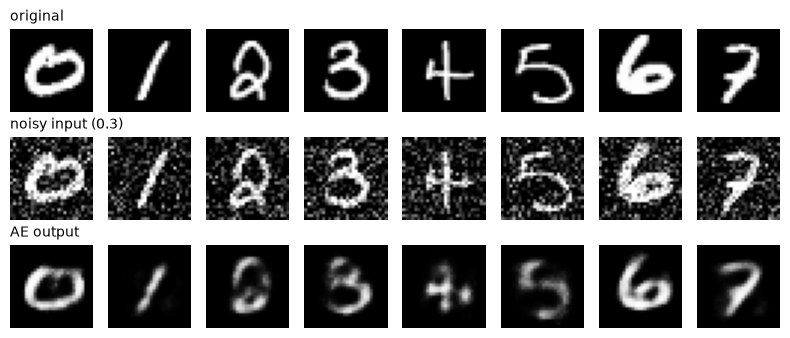

[1-2]
  epoch 1  loss 0.0661


  epoch 5  loss 0.0332


  epoch 10  loss 0.0209
노이즈 입력 → AE   MSE 0.0306
노이즈 입력 → DAE  MSE 0.0250
깨끗한 입력 → AE   MSE 0.0191
깨끗한 입력 → DAE  MSE 0.0445


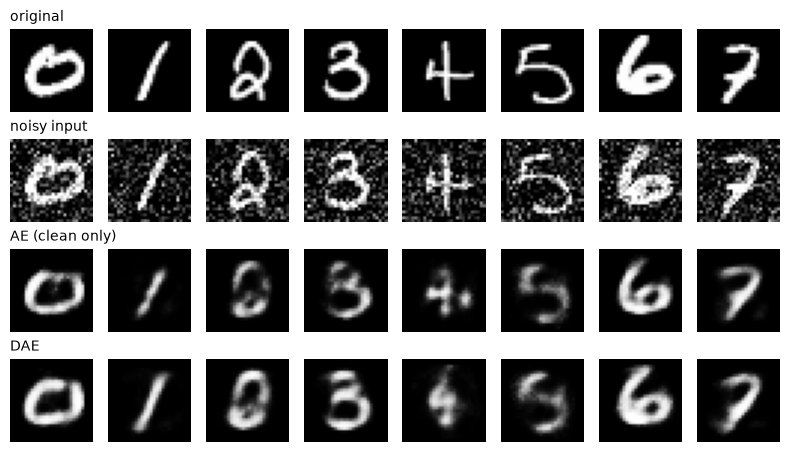

In [30]:
# ==================== [1-1]
print("[1-1]")  # 어느 섹션의 출력인지


# 어제 모델: 깨끗한 숫자만 배운 AE (오토인코더-1 1-3과 같은 조건)
torch.manual_seed(0)                    # 오토인코더-1 1-3과 같은 출발점
ae = train(AutoEncoder(32).to(device))  # 깨끗한 숫자만 배운 AE


# 평가 1만 장에 세기 0.3 노이즈를 한 번 입힘
Xn = noisy_eval(0.3)                                                     # 모든 모델이 같은 시험지
print(f"값 범위 {Xn.min().item():.1f} ~ {Xn.max().item():.1f} (clamp)")  # 0~1 안인지


# 깨끗한 입력 · 노이즈 입력 그대로 · 노이즈 입력 → AE
print(f"깨끗한 입력 → AE   MSE {mse(run(ae, Xte)):.4f}")  # 어제 모델 기준
print(f"노이즈 입력 그대로  MSE {mse(Xn):.4f}")           # 아무것도 안 한 점수
print(f"노이즈 입력 → AE   MSE {mse(run(ae, Xn)):.4f}")   # 노이즈를 넣으면
show([("original", Xte), ("noisy input (0.3)", Xn),       # 원본 · 노이즈 · 복원
      ("AE output", run(ae, Xn))])


# ==================== [1-2]
print("[1-2]")  # 어느 섹션의 출력인지


# P5 빈칸 정답: 입력은 노이즈 낀 숫자 · 정답은 깨끗한 숫자
def dae_loss(model, x, s=0.3):                         # 손실 함수만 바꿔 train에 넘김
    noisy = (x + s * torch.randn_like(x)).clamp(0, 1)  # (a) 묶음마다 새 노이즈
    return F.mse_loss(model(noisy), x)                 # (b) model(noisy) ↔ 깨끗한 x


# 구조 · 조건은 AE와 같고 손실 함수만 다름
torch.manual_seed(0)                                       # AE와 같은 출발점
dae = train(AutoEncoder(32).to(device), loss_fn=dae_loss)  # 구조 · 조건 같음


# 같은 노이즈 입력 · 같은 깨끗한 입력으로 AE와 비교
print(f"노이즈 입력 → AE   MSE {mse(run(ae, Xn)):.4f}")    # 같은 노이즈 시험지
print(f"노이즈 입력 → DAE  MSE {mse(run(dae, Xn)):.4f}")   # 같은 노이즈 시험지
print(f"깨끗한 입력 → AE   MSE {mse(run(ae, Xte)):.4f}")   # 깨끗한 입력도 비교
print(f"깨끗한 입력 → DAE  MSE {mse(run(dae, Xte)):.4f}")  # 연습 안 한 입력
show([("original", Xte), ("noisy input", Xn),              # 4줄 나란히
      ("AE (clean only)", run(ae, Xn)), ("DAE", run(dae, Xn))])

[1-3]
세기 0.1 | 노이즈 그대로 0.0054 | AE 0.0203 | DAE(0.3) 0.0376
세기 0.3 | 노이즈 그대로 0.0466 | AE 0.0306 | DAE(0.3) 0.0250
세기 0.6 | 노이즈 그대로 0.1502 | AE 0.0562 | DAE(0.3) 0.0698


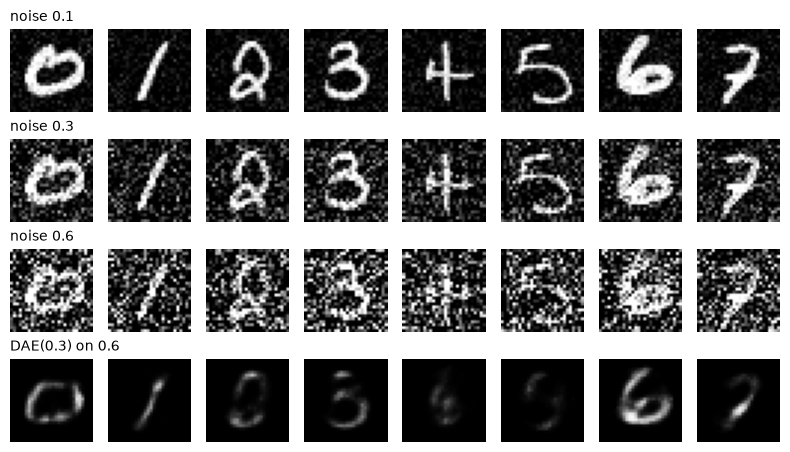

[1-4]
  epoch 1  loss 0.0677


  epoch 5  loss 0.0310


  epoch 10  loss 0.0176
가린 입력 그대로 가린 칸 MSE 0.359
AE        가린 칸 MSE 0.235
노이즈 DAE   가린 칸 MSE 0.149
가림 DAE    가린 칸 MSE 0.100
노이즈 입력 → 가림 DAE  MSE 0.0387 | 노이즈 DAE 0.0250


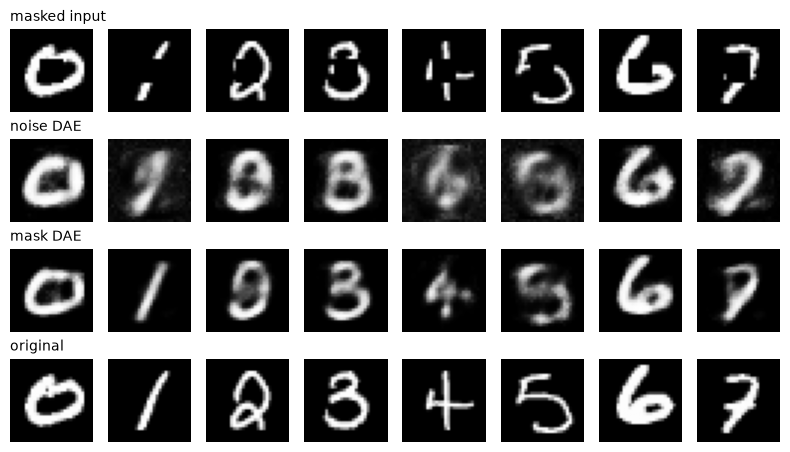

In [31]:
# ==================== [1-3]
print("[1-3]")  # 어느 섹션의 출력인지


# 노이즈 세기 세 가지 (학습 없음 · 1-2의 DAE는 0.3으로만 배움)
for s in [0.1, 0.3, 0.6]:                            # 약하게 · 중간 · 강하게
    Xs = noisy_eval(s)                               # 세기마다 고정 노이즈
    print(f"세기 {s} | 노이즈 그대로 {mse(Xs):.4f}"  # 그대로 · AE · DAE 한 줄
          f" | AE {mse(run(ae, Xs)):.4f} | DAE(0.3) {mse(run(dae, Xs)):.4f}")


# 세기별 입력 · 가장 센 0.6에 DAE(0.3)를 넣은 결과
show([("noise 0.1", noisy_eval(0.1)), ("noise 0.3", Xn),  # 세기별 입력 그림
      ("noise 0.6", noisy_eval(0.6)),
      ("DAE(0.3) on 0.6", run(dae, noisy_eval(0.6)))])


# ==================== [1-4]
print("[1-4]")  # 어느 섹션의 출력인지


# 가림 손상: 숫자 가운데 8×8 칸을 검게
def mask_center(x):            # 숫자 가운데를 검게
    x = x.clone()              # 원본 보호
    x[:, :, 10:18, 10:18] = 0  # 세로 · 가로 10~17칸
    return x                   # 가린 묶음


def mask_loss(model, x):                         # 입력은 가린 숫자 · 정답은 깨끗한 숫자
    return F.mse_loss(model(mask_center(x)), x)  # 입력 가림 · 정답 깨끗


torch.manual_seed(0)                                         # 같은 출발점
mdae = train(AutoEncoder(32).to(device), loss_fn=mask_loss)  # 가림으로 배운 DAE


# 가린 8×8 칸 안에서만 MSE (가린 곳을 얼마나 채웠나)
Xm = mask_center(Xte)  # 평가 1만 장을 가림


def mse_box(A):  # 가린 칸 안에서만 재기
    return F.mse_loss(A[:, :, 10:18, 10:18], Xte[:, :, 10:18, 10:18]).item()  # 8×8 칸끼리


for name, out in [("가린 입력 그대로", Xm), ("AE", run(ae, Xm)),  # 네 가지 비교
                  ("노이즈 DAE", run(dae, Xm)), ("가림 DAE", run(mdae, Xm))]:
    print(f"{name:<9} 가린 칸 MSE {mse_box(out):.3f}")            # 얼마나 채웠나


# 반대로: 가림 DAE에 노이즈 입력
print(f"노이즈 입력 → 가림 DAE  MSE {mse(run(mdae, Xn)):.4f}"  # 반대 손상
      f" | 노이즈 DAE {mse(run(dae, Xn)):.4f}")
show([("masked input", Xm), ("noise DAE", run(dae, Xm)),       # 그림 4줄
      ("mask DAE", run(mdae, Xm)), ("original", Xte)])

In [32]:
# ==================== [1-5]
print("[1-5]")  # 어느 섹션의 출력인지


# 가운데 64칸 끝에 ReLU → 0이면 꺼진 칸, 0보다 크면 켜진 칸
class SparseAE(AutoEncoder):            # 가운데 64칸 + ReLU
    def __init__(self):                 # 인자 없음
        super().__init__(64)            # 잠재 64로 부모 생성
        self.encoder.append(nn.ReLU())  # 784 → 128 → 64 → ReLU


def sparse_loss(lam):                                      # 복원 오차 + λ × 가운데 값의 합
    def f(model, x):                                       # train이 부르는 손실
        z = model.encoder(x)                               # 가운데 값 (0 이상)
        out = model.decoder(z).reshape(-1, 1, 28, 28)      # 복원
        return F.mse_loss(out, x) + lam * z.sum(1).mean()  # 켜진 값이 많을수록 벌점
    return f                                               # λ를 기억한 손실 함수


# 벌점 세기 λ 0 · 1e-3 비교 (나머지 조건 같음)
for lam in [0, 1e-3]:                                           # 벌점 없음 · 있음
    torch.manual_seed(0)                                        # 같은 출발점
    m = train(SparseAE().to(device), loss_fn=sparse_loss(lam))  # 같은 조건 학습
    with torch.no_grad():                                       # 꺼내기만
        z = m.encoder(Xte)                                      # 평가 1만 장의 가운데 값
    on = (z > 0).float().sum(1).mean().item()                   # 한 장당 켜진 칸 수
    print(f"λ {lam:<5} | 켜진 칸 {on:.1f} / 64 | 복원 MSE {mse(run(m, Xte)):.4f}")  # 대가 비교

[1-5]
  epoch 1  loss 0.0685


  epoch 5  loss 0.0322


  epoch 10  loss 0.0160
λ 0     | 켜진 칸 46.4 / 64 | 복원 MSE 0.0205
  epoch 1  loss 0.0793


  epoch 5  loss 0.0529


  epoch 10  loss 0.0335
λ 0.001 | 켜진 칸 7.4 / 64 | 복원 MSE 0.0349


In [33]:
# ==================== [2-0a]
print("[2-0a]")  # 어느 섹션의 출력인지


# 연습용 문서: 문서 번호 하나 → (clean, dirty) · 같은 번호는 늘 같은 문서
WORDS = ("the of and to in is data model image paper result note page "  # 문서에 쓸 단어
         "table value error clean noise sample layer filter record method "
         "letter number office review summary budget project").split()


def make_doc(seed, h=128, w=256):                             # 문서 번호 → (clean, dirty)
    rng = np.random.default_rng(seed)                         # 번호가 같으면 같은 문서
    size = int(rng.integers(12, 20))                          # 글자 크기
    img = PIL.Image.new("L", (w, h), 255)                     # 흰 종이
    draw = ImageDraw.Draw(img)                                # 글자를 그릴 붓
    font = ImageFont.load_default(size=size)                  # 기본 글꼴 · 크기 지정
    y = int(rng.integers(2, size // 2 + 2))                   # 첫 줄 높이
    while y + int(size * 1.45) <= h - 2:                      # 줄마다 단어를 이어 씀
        x, line = int(rng.integers(2, 12)), ""                # 줄 시작 위치 · 빈 줄
        while True:                                           # 줄이 찰 때까지
            cand = (line + " " + WORDS[rng.integers(len(WORDS))]).strip()  # 단어 하나 더 붙여 봄
            if x + draw.textlength(cand, font=font) > w - 4:  # 폭을 넘으면
                break                                         # 이 줄은 끝
            line = cand                                       # 넘지 않으면 확정
        draw.text((x, y), line, fill=0, font=font)            # 검은 글자로 씀
        y += int(size * 1.45)                                 # 다음 줄로
    clean = np.asarray(img, dtype=np.float32) / 255           # 정답판 0~1

    # 손상 ① 한쪽으로 갈수록 어두워짐
    g = np.linspace(0, rng.uniform(0.1, 0.35), w, dtype=np.float32)  # 가로로 점점 어두워짐
    dirty = clean * (1 - (g if rng.random() < 0.5 else g[::-1]))     # 왼쪽 또는 오른쪽이 어둡게

    # 손상 ② 회색 상자가 글자를 가림
    bh, bw = int(h * rng.uniform(0.1, 0.25)), int(w * rng.uniform(0.05, 0.15))  # 상자 크기
    by, bx = int(rng.integers(0, h - bh)), int(rng.integers(0, w - bw))         # 상자 위치
    dirty[by:by + bh, bx:bx + bw] = rng.uniform(0.2, 0.6)                       # 회색으로 덮음

    # 손상 ③ 검은 점 · 흰 점
    m, p = rng.random(dirty.shape), rng.uniform(0.002, 0.01)  # 칸마다 난수 · 점 비율
    dirty[m < p / 2], dirty[m > 1 - p / 2] = 0.0, 1.0         # 검은 점 · 흰 점
    return clean, np.clip(dirty, 0, 1).astype(np.float32)     # 정답 · 손상판

[2-0a]


In [34]:
# ==================== [2-0b]
print("[2-0b]")  # 어느 섹션의 출력인지


# 문서 번호: 학습 24장 · 평가 8장 (평가 문서는 학습에 안 씀)
H, W, PS = 128, 256, 48                                # 문서 세로 · 가로 · 조각 한 변
train_ids = list(range(1000, 1024))                    # 학습 문서 24장
eval_ids = list(range(2000, 2008))                     # 평가 문서 8장
docs = {i: make_doc(i) for i in train_ids + eval_ids}  # 번호 → (clean, dirty)


def crop(img, y, x):                # (y, x)가 왼쪽 위인 48×48 조각
    return img[y:y + PS, x:x + PS]  # 세로 · 가로 48칸


def to_batch(patches):  # 조각 목록 → (조각 수, 1, 48, 48)
    return torch.tensor(np.stack(patches)).unsqueeze(1).to(device)  # 쌓고 채널 축


# ==================== [2-0c]
print("[2-0c]")  # 어느 섹션의 출력인지


# 문서 모델: 오토인코더-1 3-5 ConvAE와 같은 구조 (48 → 24 → 12 → 24 → 48)
def make_model(ch=(16, 32)):  # 채널을 바꿀 수 있게
    c1, c2 = ch               # 첫 층 · 둘째 층 채널
    return nn.Sequential(     # 줄이기 2번 · 늘리기 2번
        nn.Conv2d(1, c1, 3, 2, 1), nn.ReLU(),
        nn.Conv2d(c1, c2, 3, 2, 1), nn.ReLU(),
        nn.ConvTranspose2d(c2, c1, 3, 2, 1, output_padding=1), nn.ReLU(),
        nn.ConvTranspose2d(c1, 1, 3, 2, 1, output_padding=1),
        nn.Sigmoid()).to(device)


def train_doc(X, Y, epochs=10, ch=(16, 32), seed=0):                  # 입력 X · 정답 Y
    torch.manual_seed(seed)                                           # 모델 · 섞기 출발점
    model = make_model(ch)                                            # 새 모델
    opt = torch.optim.Adam(model.parameters(), lr=1e-3)               # 가중치 갱신 담당
    for epoch in range(epochs):                                       # 조각 전체를 epochs번
        perm = torch.randperm(len(X), device=device)                  # 번호 섞기
        total = 0.0                                                   # epoch 평균 loss용
        for k in range(0, len(X), 32):                                # 32개씩
            b = perm[k:k + 32]                                        # 이번 묶음 번호
            opt.zero_grad()                                           # 기울기 비우기
            loss = F.mse_loss(model(X[b]), Y[b])                      # 입력 X · 정답 Y
            loss.backward()                                           # 기울기 계산
            opt.step()                                                # 가중치 갱신
            total += loss.item() * len(b)                             # 묶음 크기만큼 더함
        if epoch in (0, epochs // 2 - 1, epochs - 1):                 # 1 · 중간 · 끝만
            print(f"  epoch {epoch + 1}  loss {total / len(X):.4f}")  # epoch 평균 loss
    return model.eval()                                               # 평가 모드로 돌려줌

[2-0b]
[2-0c]


[2-0d]


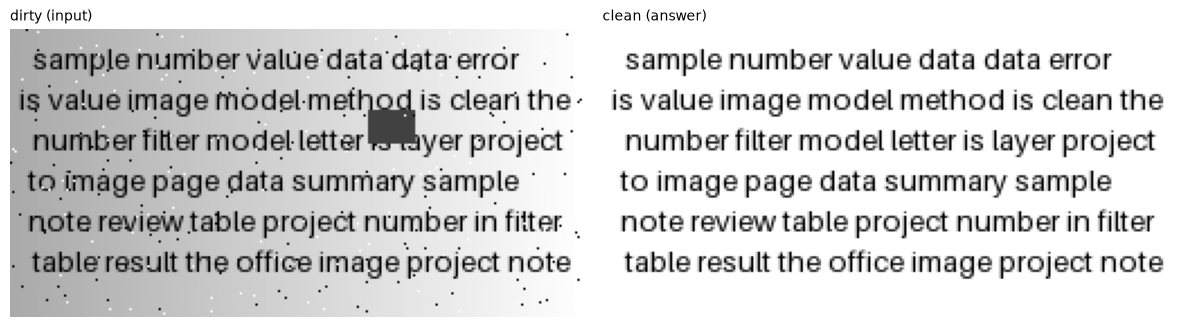

문서 32 장 · 한 장 (128, 256) | 평가 조각 (256, 1, 48, 48)


In [35]:
# ==================== [2-0d]
print("[2-0d]")  # 어느 섹션의 출력인지


# 평가 조각: 평가 문서 8장 × 32개 (좌표 seed 7777)
erng = np.random.default_rng(7777)                                         # 평가 조각 좌표 고정
EX, EY = [], []                                                            # 입력 · 정답 조각
for i in eval_ids:                                                         # 평가 문서마다
    clean, dirty = docs[i]                                                 # 두 판
    for _ in range(32):                                                    # 조각 32개
        y, x = erng.integers(0, H - PS + 1), erng.integers(0, W - PS + 1)  # 같은 좌표 하나
        EX.append(crop(dirty, y, x))                                       # 손상 조각
        EY.append(crop(clean, y, x))                                       # 같은 자리 정답 조각
EX, EY = to_batch(EX), to_batch(EY)                                        # (256, 1, 48, 48)


def rmse_patch(out, ref=None):                                      # 조각마다 RMSE → 평균
    ref = EY if ref is None else ref                                # 기본 정답은 평가 조각
    return ((out - ref) ** 2).mean((1, 2, 3)).sqrt().mean().item()  # 조각 RMSE 평균


def show_rows(rows, idx):                                                  # 줄마다 같은 번호의 조각
    fig, axes = plt.subplots(len(rows), len(idx),                          # 줄 × 조각 수
                             figsize=(len(idx), 1.25 * len(rows)))
    for r, (name, T) in enumerate(rows):                                   # 줄마다
        for c, j in enumerate(idx):                                        # 고른 조각마다
            axes[r, c].imshow(T[j, 0].cpu(), cmap="gray", vmin=0, vmax=1)  # 밝기 0~1
            axes[r, c].axis("off")                                         # 눈금 숨김
        axes[r, 0].set_title(name, loc="left", fontsize=10)                # 줄 이름
    plt.tight_layout()                                                     # 간격 정리
    plt.show()                                                             # 그림 출력


# 문서 한 쌍 보기 · 크기 확인
fig, axes = plt.subplots(1, 2, figsize=(12, 3.2))                    # 손상판 · 정답판
for ax, (name, img) in zip(axes, [("dirty (input)", docs[1000][1]),  # 문서 1000 한 쌍
                                  ("clean (answer)", docs[1000][0])]):
    ax.imshow(img, cmap="gray", vmin=0, vmax=1)                      # 밝기 0~1
    ax.set_title(name, loc="left", fontsize=10)                      # 어느 판인지
    ax.axis("off")                                                   # 눈금 숨김
plt.tight_layout()                                                   # 간격 정리
plt.show()                                                           # 그림 출력
print("문서", len(docs), "장 · 한 장", docs[1000][0].shape,          # 개수 · 크기 확인
      "| 평가 조각", tuple(EX.shape))

[2-1]


학습 문서 24 장 | 입력 (3072, 1, 48, 48) | 정답 A · B (3072, 1, 48, 48)
맞춘 짝 A


  epoch 1  loss 0.1035


  epoch 5  loss 0.0122


  epoch 10  loss 0.0072
어긋난 짝 B


  epoch 1  loss 0.1146


  epoch 5  loss 0.0936


  epoch 10  loss 0.0936
RMSE  손상 그대로 0.134 | A 0.077 | B 0.289
조각 안 표준편차  정답 0.285 | A 0.269 | B 0.009


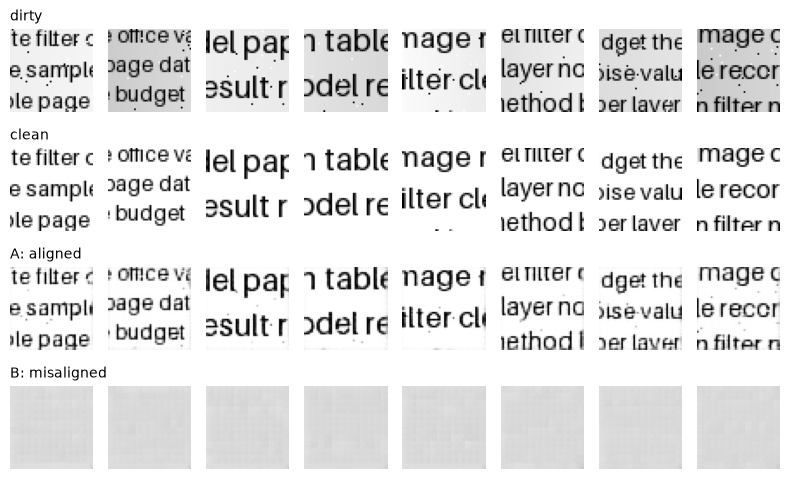

In [36]:
# ==================== [2-1]
print("[2-1]")  # 어느 섹션의 출력인지


# P6 빈칸 정답: 정답 조각은 입력과 같은 (y, x)에서 clean으로 자름
def make_pairs(ids, n=128, seed=2026, misalign=False):   # 문서 번호 → (입력, 정답)
    rng = np.random.default_rng(seed)                    # 좌표 난수 고정
    rng_b = np.random.default_rng(seed + 1)              # 어긋난 짝 좌표 전용
    X, Y = [], []                                        # 입력 · 정답 조각
    for i in ids:                                        # 문서마다
        clean, dirty = docs[i]                           # 두 판
        ys, xs = rng.integers(0, H - PS + 1, n), rng.integers(0, W - PS + 1, n)  # 좌표 n개
        for y, x in zip(ys, xs):                         # 좌표마다
            X.append(crop(dirty, y, x))                  # 입력: dirty 조각
            if misalign:                                 # 버그판: 정답 좌표를 따로 뽑음
                y, x = rng_b.integers(0, H - PS + 1, 2)  # 다른 자리
            Y.append(crop(clean, y, x))                  # (a) 같은 (y, x)의 clean
    return to_batch(X), to_batch(Y)                      # 텐서 두 개


use_ids = [i for i in docs if i not in eval_ids]               # (b) 평가 문서 빼기
X, Y_A = make_pairs(use_ids)                                   # 맞춘 짝
_, Y_B = make_pairs(use_ids, misalign=True)                    # 어긋난 짝 (입력은 같음)
print("학습 문서", len(use_ids), "장 | 입력", tuple(X.shape),  # 모양 확인
      "| 정답 A · B", tuple(Y_A.shape))


# 같은 입력 · 같은 모델 · 정답만 다르게 학습
print("맞춘 짝 A")           # 어느 학습인지
model_A = train_doc(X, Y_A)  # 정답 A로 학습
print("어긋난 짝 B")         # 어느 학습인지
model_B = train_doc(X, Y_B)  # 정답 B로 학습


# 평가 조각 256개로 비교 (RMSE · 조각 안 밝기 표준편차)
with torch.no_grad():                                                     # 평가만
    OA, OB = model_A(EX), model_B(EX)                                     # 평가 조각 복원
print(f"RMSE  손상 그대로 {rmse_patch(EX):.3f} | A {rmse_patch(OA):.3f}"  # 세 점수
      f" | B {rmse_patch(OB):.3f}")


def spread(T):                                # 조각 안 밝기 표준편차 평균 (0이면 한 가지 밝기)
    return T.flatten(1).std(1).mean().item()  # 조각마다 표준편차 평균


print(f"조각 안 표준편차  정답 {spread(EY):.3f} | A {spread(OA):.3f}"  # 한 가지 밝기인지
      f" | B {spread(OB):.3f}")


# 문서마다 글자가 가장 많은 조각 하나씩 (8개)
dark = (EY < 0.5).float().mean((1, 2, 3))                                      # 조각마다 글자 비율
SHOW_P = [j * 32 + int(dark[j * 32:(j + 1) * 32].argmax()) for j in range(8)]  # 문서마다 1개
show_rows([("dirty", EX), ("clean", EY), ("A: aligned", OA),                   # 그림 4줄
           ("B: misaligned", OB)], SHOW_P)

In [37]:
# ==================== [2-2]
print("[2-2]")  # 어느 섹션의 출력인지


# 학습 문서와 평가 문서가 겹치지 않는지 번호로 확인
print("겹치는 문서 번호:", set(use_ids) & set(eval_ids))  # 빈 집합이어야 함


# 학습에 쓴 문서의 다른 자리 조각으로 재면? (문서 8장 × 32개)
TX, TY = make_pairs(use_ids[:8], n=32, seed=7777)    # 학습 문서의 다른 자리
with torch.no_grad():                                # 평가만
    rm_train = rmse_patch(model_A(TX), TY)           # 학습 문서 조각 점수
print(f"모델 A RMSE  학습 문서 조각 {rm_train:.4f}"  # 두 점수 비교
      f" | 평가 문서 조각 {rmse_patch(OA):.4f}")


# 조각을 다 자른 뒤 섞어 나누면: 평가 조각의 문서가 학습에도 있음
rng = np.random.default_rng(0)                             # 섞기 고정
doc_of = np.repeat(list(docs), 32)                         # 조각마다 문서 번호 (32장 × 32개)
perm = rng.permutation(len(doc_of))                        # 조각 번호 섞기
tr_docs, ev_docs = set(doc_of[perm[:800]]), set(doc_of[perm[800:]])  # 앞 800 학습 · 나머지 평가
print(f"섞어 나눔 → 평가 조각의 문서 {len(ev_docs)}장 중"  # 겹치는 문서 수
      f" 학습에도 있는 문서 {len(ev_docs & tr_docs)}장")

[2-2]
겹치는 문서 번호: set()
모델 A RMSE  학습 문서 조각 0.0773 | 평가 문서 조각 0.0771
섞어 나눔 → 평가 조각의 문서 32장 중 학습에도 있는 문서 32장


In [38]:
# ==================== [2-3a]
print("[2-3a]")  # 어느 섹션의 출력인지


# 문서 한 장(128×256)을 통째로 → 같은 크기로 나옴
clean0, dirty0 = docs[2000]                                          # 평가 문서 한 장
with torch.no_grad():                                                # 통째로 넣기만
    out0 = model_A(torch.tensor(dirty0, device=device)[None, None])  # (1, 1, 128, 256)
print("128×256 문서 → 출력", tuple(out0.shape))                      # 크기 그대로인지


# 세로 130 · 가로 270 문서 → 크기 어긋남 (일부러 내는 에러)
clean_b, dirty_b = make_doc(3000, h=130, w=270)       # 4의 배수가 아닌 문서
t = torch.tensor(dirty_b, device=device)[None, None]  # (1, 1, 130, 270)
try:
    with torch.no_grad():                             # 에러 확인만
        ((model_A(t) - t) ** 2).mean()                # 칸마다 빼기 시도
except RuntimeError as e:                             # 에러를 잡아 멈추지 않게
    print("RuntimeError:", str(e)[:64])               # 앞부분만 읽기


# P7-1 빈칸 정답: 층마다 모양 찍기 (방법은 오토인코더-1 3-3)
with torch.no_grad():                                     # 층마다 통과만
    for k, layer in enumerate(model_A):                   # 층 번호와 함께
        t = layer(t)                                      # ① 층 하나 통과
        if not isinstance(layer, (nn.ReLU, nn.Sigmoid)):  # 크기를 바꾸는 층만 출력
            print(f"{k}번 {type(layer).__name__:<16} {tuple(t.shape)}")  # 층마다 모양
first_odd_layer = 2                                       # ② 65×135(홀수)가 처음 들어가는 Conv2d


# 방법 ①: 4의 배수로 채우고 → 넣고 → 잘라내기 (P7-2 ③)
h, w = dirty_b.shape                                                # 원래 크기
H4, W4 = (h + 3) // 4 * 4, (w + 3) // 4 * 4                         # 4의 배수로 올림
padded = np.pad(dirty_b, ((0, H4 - h), (0, W4 - w)), mode="edge")   # 아래 · 오른쪽 채움
with torch.no_grad():                                               # 채운 문서 복원만
    out = model_A(torch.tensor(padded, device=device)[None, None])  # 132×272 통째로
out_crop = out[:, :, :h, :w]                                        # ③ 원래 문서 자리만
print("채운 모양", padded.shape, "→ 나온", tuple(out.shape),        # 세 모양
      "→ 잘라낸", tuple(out_crop.shape))

[2-3a]
128×256 문서 → 출력 (1, 1, 128, 256)
RuntimeError: The size of tensor a (272) must match the size of tensor b (270)
0번 Conv2d           (1, 16, 65, 135)
2번 Conv2d           (1, 32, 33, 68)
4번 ConvTranspose2d  (1, 16, 66, 136)
6번 ConvTranspose2d  (1, 1, 132, 272)
채운 모양 (132, 272) → 나온 (1, 1, 132, 272) → 잘라낸 (1, 1, 130, 270)


[2-3b]
방법 ① 채우고 자름  경계 부근 RMSE 0.062 | 나머지 0.074
방법 ② 조각 이어 붙임  경계 부근 RMSE 0.098 | 나머지 0.074


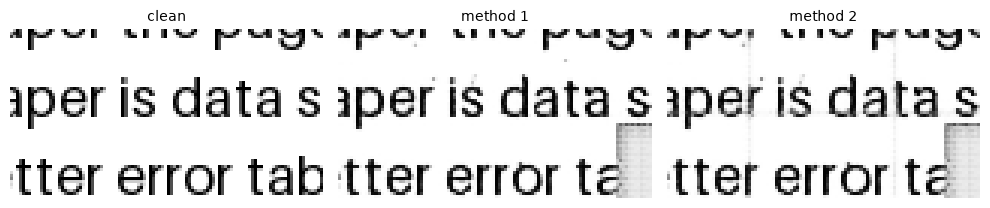

In [39]:
# ==================== [2-3b]
print("[2-3b]")  # 어느 섹션의 출력인지


# 방법 ②: 48×48 조각으로 나눠 복원해 이어 붙이기
tiled = np.zeros_like(padded)                                            # 붙일 빈 판
with torch.no_grad():                                                    # 복원만
    for y in range(0, H4, PS):                                           # 세로 48칸 간격
        for x in range(0, W4, PS):                                       # 가로 48칸 간격
            part = padded[y:y + PS, x:x + PS]                            # 조각 하나
            ph, pw = part.shape                                          # 끝 조각은 작을 수 있음
            part4 = np.pad(part, ((0, -ph % 4), (0, -pw % 4)), mode="edge")  # 조각도 4의 배수로
            o = model_A(torch.tensor(part4, device=device)[None, None])  # 조각 복원
            tiled[y:y + ph, x:x + pw] = o[0, 0, :ph, :pw].cpu().numpy()  # 제자리에 붙임
out_tile = tiled[:h, :w]                                                 # 원래 크기만


# 조각 경계 4칸 부근 · 나머지로 나눠 RMSE
seam = np.zeros((h, w), dtype=bool)                                  # 경계 표시판
for y in range(PS, h, PS):                                           # 세로 경계
    seam[y - 2:y + 2] = True                                         # 경계 4칸
for x in range(PS, w, PS):                                           # 가로 경계
    seam[:, x - 2:x + 2] = True                                      # 경계 4칸
img1 = out_crop[0, 0].cpu().numpy()                                  # 방법 ① 결과
for name, img in [("방법 ① 채우고 자름", img1), ("방법 ② 조각 이어 붙임", out_tile)]:  # 두 방법
    err = (img - clean_b) ** 2                                       # 칸마다 오차²
    print(f"{name}  경계 부근 RMSE {np.sqrt(err[seam].mean()):.3f}"  # 경계 · 나머지
          f" | 나머지 {np.sqrt(err[~seam].mean()):.3f}")


# 경계(가로 48 · 96, 세로 48)가 들어간 부분 확대
zy, zx = slice(20, 76), slice(20, 124)                                     # 경계가 들어간 부분
fig, axes = plt.subplots(1, 3, figsize=(10, 2.2))                          # 정답 · 방법 ① · ②
for ax, (name, img) in zip(axes, [("clean", clean_b), ("method 1", img1),  # 세 장
                                  ("method 2", out_tile)]):
    ax.imshow(img[zy, zx], cmap="gray", vmin=0, vmax=1)                    # 확대
    ax.set_title(name, fontsize=10)                                        # 이름
    ax.axis("off")                                                         # 눈금 숨김
plt.tight_layout()                                                         # 간격 정리
plt.show()                                                                 # 그림 출력

In [40]:
# ==================== [3-1]
print("[3-1]")  # 어느 섹션의 출력인지


# 평가 문서 8장을 한 장씩 통째로 복원 (128×256은 4의 배수)
with torch.no_grad():                                                         # 복원만
    eval_out = [model_A(torch.tensor(docs[i][1], device=device)[None, None])  # 평가 문서 8장
                [0, 0].cpu().numpy() for i in eval_ids]
eval_clean = [docs[i][0] for i in eval_ids]                                   # 정답 8장
eval_dirty = [docs[i][1] for i in eval_ids]                                   # 손상 8장


def rmse_doc(outs, cleans):                               # 문서마다 RMSE → 평균
    return float(np.mean([np.sqrt(((o - c) ** 2).mean())  # 문서마다 RMSE 평균
                          for o, c in zip(outs, cleans)]))


def psnr_doc(outs, cleans):  # 10 × log10(1 / MSE) · 클수록 가까움
    return float(np.mean([10 * np.log10(1 / ((o - c) ** 2).mean())  # 문서마다 PSNR 평균
                          for o, c in zip(outs, cleans)]))


# 기준선: 아무것도 안 한 답 (P8 빈칸 ① 흰 종이 · ② 모델 출력)
white = [np.ones_like(c) for c in eval_clean]                      # 모든 칸 1
mean_val = float(np.mean([docs[i][0].mean() for i in train_ids]))  # 학습 문서 평균 밝기
gray = [np.full_like(c, mean_val) for c in eval_clean]             # 학습 문서 평균 밝기
for name, outs in [("흰 종이", white), ("평균 밝기 종이", gray),   # 기준선 둘 + 둘
                   ("손상 그대로", eval_dirty), ("맞춘 짝 모델", eval_out)]:
    print(f"{name:<8} 문서 RMSE {rmse_doc(outs, eval_clean):.3f}"  # 같은 함수로
          f" | PSNR {psnr_doc(outs, eval_clean):.1f} dB")

[3-1]


흰 종이     문서 RMSE 0.285 | PSNR 10.9 dB
평균 밝기 종이 문서 RMSE 0.266 | PSNR 11.5 dB
손상 그대로   문서 RMSE 0.154 | PSNR 16.4 dB
맞춘 짝 모델  문서 RMSE 0.070 | PSNR 23.3 dB


[3-2]


글자 칸 비율 10.2% (나머지는 배경)
손상 그대로  전체 0.154 | 배경 칸 0.161 | 글자 칸 0.069
맞춘 짝 모델 전체 0.070 | 배경 칸 0.050 | 글자 칸 0.156


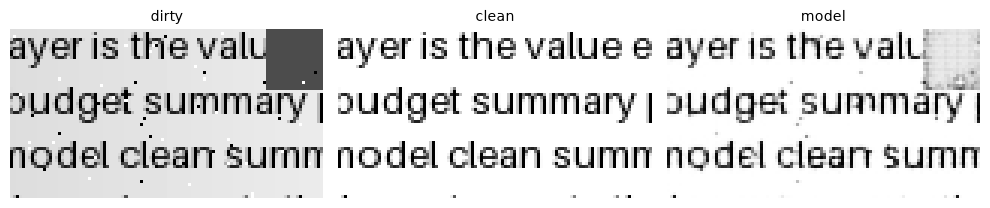

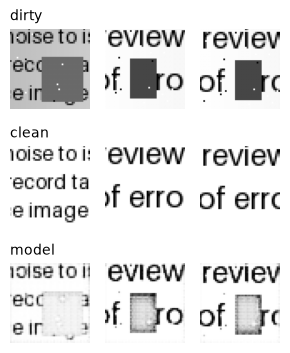

In [41]:
# ==================== [3-2]
print("[3-2]")  # 어느 섹션의 출력인지


# P8 빈칸 정답 ③: 글자 칸 = 정답(clean)에서 0.5보다 어두운 칸
def text_mask(clean):   # 정답판 → 글자 칸 표시
    return clean < 0.5  # 어두운 칸 = 글자


def rmse_part(outs, cleans, text=True):                 # 글자 칸 또는 배경 칸만 RMSE
    vals = []                                           # 문서별 값
    for o, c in zip(outs, cleans):                      # 문서마다
        m = text_mask(c) if text else ~text_mask(c)     # 글자 칸 또는 배경 칸
        vals.append(np.sqrt(((o - c)[m] ** 2).mean()))  # 그 칸만 RMSE
    return float(np.mean(vals))                         # 8장 평균


ratio = np.mean([text_mask(c).mean() for c in eval_clean])                    # 글자 칸 비율
print(f"글자 칸 비율 {ratio:.1%} (나머지는 배경)")                            # 얼마나 좁은지
for name, outs in [("손상 그대로", eval_dirty), ("맞춘 짝 모델", eval_out)]:  # 두 결과
    print(f"{name:<7} 전체 {rmse_doc(outs, eval_clean):.3f}"                  # 전체 · 배경 · 글자
          f" | 배경 칸 {rmse_part(outs, eval_clean, False):.3f}"
          f" | 글자 칸 {rmse_part(outs, eval_clean):.3f}")


# 눈으로 보기: 평가 문서 2000 왼쪽 위 글자 확대
zy, zx = slice(8, 64), slice(8, 112)                         # 왼쪽 위 글자 부분
fig, axes = plt.subplots(1, 3, figsize=(10, 2.2))            # 손상 · 정답 · 모델
for ax, (name, img) in zip(axes, [("dirty", eval_dirty[0]),  # 문서 2000
                                  ("clean", eval_clean[0]),
                                  ("model", eval_out[0])]):
    ax.imshow(img[zy, zx], cmap="gray", vmin=0, vmax=1)      # 확대
    ax.set_title(name, fontsize=10)                          # 이름
    ax.axis("off")                                           # 눈금 숨김
plt.tight_layout()                                           # 간격 정리
plt.show()                                                   # 그림 출력


# 평가 조각 256개 중 모델 오차가 가장 큰 3개
worst = ((OA - EY) ** 2).mean((1, 2, 3)).argsort(descending=True)[:3]     # 오차 큰 3개
show_rows([("dirty", EX), ("clean", EY), ("model", OA)], worst.tolist())  # 눈으로 확인

In [42]:
# ==================== [4-1]
print("[4-1]")  # 어느 섹션의 출력인지


# 평가 함수: 평가 문서 8장 → (문서 RMSE, 글자 칸 RMSE)
def evaluate(model):                                                        # 모델 → (문서, 글자 칸)
    with torch.no_grad():                                                   # 평가만
        outs = [model(torch.tensor(docs[i][1], device=device)[None, None])  # 평가 문서 8장
                [0, 0].cpu().numpy() for i in eval_ids]
    return rmse_doc(outs, eval_clean), rmse_part(outs, eval_clean)          # 3장 함수 그대로


# 설정은 그대로 · seed만 0 → 1
base = evaluate(model_A)                                           # seed 0 = 2-1 모델 A
print("seed 1 학습")                                               # 어느 학습인지
s1 = evaluate(train_doc(X, Y_A, seed=1))                           # 설정 같고 seed만 1
print(f"seed 0 | 문서 {base[0]:.4f} | 글자 칸 {base[1]:.4f}")      # 기준
print(f"seed 1 | 문서 {s1[0]:.4f} | 글자 칸 {s1[1]:.4f}")          # 다시 학습
wobble = (abs(s1[0] - base[0]), abs(s1[1] - base[1]))              # 차이의 크기
print(f"흔들림 | 문서 {wobble[0]:.4f} | 글자 칸 {wobble[1]:.4f}")  # 4-2의 눈금


# ==================== [4-2]
print("[4-2]")  # 어느 섹션의 출력인지


# 실험 세 개: 하나만 바꾸기 2개 · 한꺼번에 2개 바꾸기 1개
setups = {"에폭만 20": dict(epochs=20),            # 실험 세 가지
          "채널만 (8, 16)": dict(ch=(8, 16)),
          "둘 다 바꿈": dict(epochs=20, ch=(8, 16))}
res = {}                                           # 실험 결과
for name, kw in setups.items():                    # 실험마다
    print(name)                                    # 어느 실험인지
    res[name] = evaluate(train_doc(X, Y_A, **kw))  # 나머지는 기준과 같음


# 기준과의 차이를 흔들림(4-1)과 나란히
print(f"{'기준 (10, (16, 32))':<16} 문서 {base[0]:.4f} | 글자 칸 {base[1]:.4f}")  # 기준
for name, (d, t) in res.items():                                                  # 실험마다
    print(f"{name:<16} 문서 {d:.4f} ({d - base[0]:+.4f})"                         # 값 (기준과 차이)
          f" | 글자 칸 {t:.4f} ({t - base[1]:+.4f})")
print(f"{'흔들림 (seed)':<16} 문서 ±{wobble[0]:.4f} | 글자 칸 ±{wobble[1]:.4f}")  # 비교 눈금

[4-1]
seed 1 학습


  epoch 1  loss 0.1031


  epoch 5  loss 0.0136


  epoch 10  loss 0.0077
seed 0 | 문서 0.0695 | 글자 칸 0.1557
seed 1 | 문서 0.0725 | 글자 칸 0.1585
흔들림 | 문서 0.0030 | 글자 칸 0.0028
[4-2]
에폭만 20


  epoch 1  loss 0.1035


...

  epoch 5  loss 0.0426


  epoch 10  loss 0.0210
둘 다 바꿈


  epoch 1  loss 0.1659


  epoch 10  loss 0.0210


  epoch 20  loss 0.0117
기준 (10, (16, 32)) 문서 0.0695 | 글자 칸 0.1557
에폭만 20           문서 0.0637 (-0.0058) | 글자 칸 0.1518 (-0.0040)
채널만 (8, 16)      문서 0.1214 (+0.0519) | 글자 칸 0.2843 (+0.1286)
둘 다 바꿈           문서 0.0930 (+0.0235) | 글자 칸 0.2109 (+0.0552)
흔들림 (seed)       문서 ±0.0030 | 글자 칸 ±0.0028


[5-1]
0 학습 5000 장 | 0 검증 923 장
  epoch 1  loss 0.0640


  epoch 5  loss 0.0224


  epoch 10  loss 0.0189
숫자 0 오차 중앙값 0.0196 | 숫자 1 0.0906
숫자 2 오차 중앙값 0.0774 | 숫자 3 0.0647
숫자 4 오차 중앙값 0.0790 | 숫자 5 0.0585
숫자 6 오차 중앙값 0.0529 | 숫자 7 0.0818
숫자 8 오차 중앙값 0.0647 | 숫자 9 0.0702


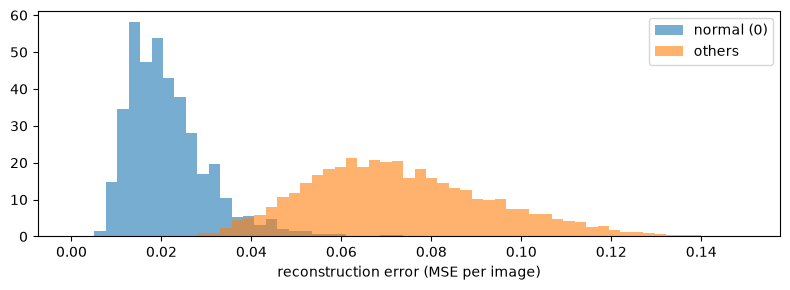

In [43]:
# ==================== [5-1]
print("[5-1]")  # 어느 섹션의 출력인지


# 정상 = 숫자 0 (학습 데이터 6만 장에서 0만 골라 학습 5,000 · 검증 나머지)
X0 = tr.data[tr.targets == 0].float().div(255).unsqueeze(1).to(device)  # 정상 = 숫자 0만
X0_tr, X0_val = X0[:5000], X0[5000:]                                    # 학습 · 검증
print("0 학습", len(X0_tr), "장 | 0 검증", len(X0_val), "장")           # 개수 확인
torch.manual_seed(0)                                                    # 같은 출발점
ae0 = train(AutoEncoder(32).to(device), X=X0_tr)                        # 0만 배운 AE


# 한 장마다 복원 오차 (평가 1만 장 · 숫자 0~9)
def err_each(model, X):                                         # 한 장마다 복원 오차
    return ((run(model, X) - X) ** 2).flatten(1).mean(1).cpu()  # (장 수,)


err_te = err_each(ae0, Xte)                                          # 평가 1만 장 (0~9)
for k in range(0, 10, 2):                                            # 두 숫자씩
    a, b = err_te[yte == k].median(), err_te[yte == k + 1].median()  # 숫자별 중앙값
    print(f"숫자 {k} 오차 중앙값 {a:.4f} | 숫자 {k + 1} {b:.4f}")    # 0이 가장 작아야


# 정상(0) · 이상(나머지) 오차 분포
plt.figure(figsize=(8, 3))                                                     # 분포 그림
bins = np.linspace(0, 0.15, 60)                                                # 같은 구간
plt.hist(err_te[yte == 0], bins, alpha=0.6, density=True, label="normal (0)")  # 정상
plt.hist(err_te[yte != 0], bins, alpha=0.6, density=True, label="others")      # 이상
plt.xlabel("reconstruction error (MSE per image)")                             # 가로축 이름
plt.legend()                                                                   # 범례
plt.tight_layout()                                                             # 간격 정리
plt.show()                                                                     # 그림 출력

In [44]:
# ==================== [5-2]
print("[5-2]")  # 어느 섹션의 출력인지


# 임곗값의 재료: 정상 검증 이미지의 오차 (평가 이미지는 안 씀)
err_val = err_each(ae0, X0_val)  # 정상 검증 오차


# 시험 세트: 평가 0 전체 + 다른 숫자 20장씩 (이상 약 16%)
g = torch.Generator().manual_seed(0)                                 # 뽑기 고정
idx = [torch.where(yte == 0)[0]]                                     # 평가 0 전체
for k in range(1, 10):                                               # 다른 숫자마다
    pool = torch.where(yte == k)[0]                                  # 그 숫자의 번호들
    idx.append(pool[torch.randperm(len(pool), generator=g)[:20]])    # 20장만
idx = torch.cat(idx)                                                 # 시험 세트 번호
y_true = (yte[idx] != 0).int()                                       # 이상 = 1 (양성)
e_test = err_te[idx]                                                 # 시험 세트 오차
print(f"시험 세트 {len(idx)}장 | 정상 {(y_true == 0).sum().item()}"  # 구성 확인
      f" | 이상 {y_true.sum().item()}")


# 임곗값 낮게 (검증 오차 90%) vs 높게 (99%)
def judge(q):                                                # 분위수 q → 판정 결과
    th = torch.quantile(err_val, q).item()                   # 정상 검증으로 임곗값
    pred = (e_test > th).int()                               # 오차가 임곗값보다 크면 이상
    tn, fp, fn, tp = confusion_matrix(y_true, pred).ravel()  # 혼동 행렬 네 칸
    return th, tp, fp, fn, tn                                # 6장에서도 씀


for q in [0.90, 0.99]:                                                    # 낮게 · 높게
    th, tp, fp, fn, tn = judge(q)                                         # 판정
    print(f"임곗값 {q:.0%} = {th:.4f} | TP {tp} FP {fp} FN {fn} TN {tn}"  # 정밀도 · 재현율까지
          f" | 정밀도 {tp / (tp + fp):.3f} | 재현율 {tp / (tp + fn):.3f}")

[5-2]
시험 세트 1160장 | 정상 980 | 이상 180
임곗값 90% = 0.0318 | TP 179 FP 116 FN 1 TN 864 | 정밀도 0.607 | 재현율 0.994
임곗값 99% = 0.0458 | TP 160 FP 21 FN 20 TN 959 | 정밀도 0.884 | 재현율 0.889


[6-1]
DAE 0.1 학습
  epoch 1  loss 0.0653


  epoch 5  loss 0.0276


  epoch 10  loss 0.0169
DAE 0.6 학습
  epoch 1  loss 0.0656


  epoch 5  loss 0.0395


  epoch 10  loss 0.0277
평가 →         0.1     0.3     0.6   clean
노이즈 그대로 0.0054  0.0466  0.1502  0.0000
DAE 0.1 학습  0.0199  0.0888  0.1137  0.0361
DAE 0.3 학습  0.0376  0.0250  0.0698  0.0445
DAE 0.6 학습  0.0470  0.0398  0.0330  0.0497


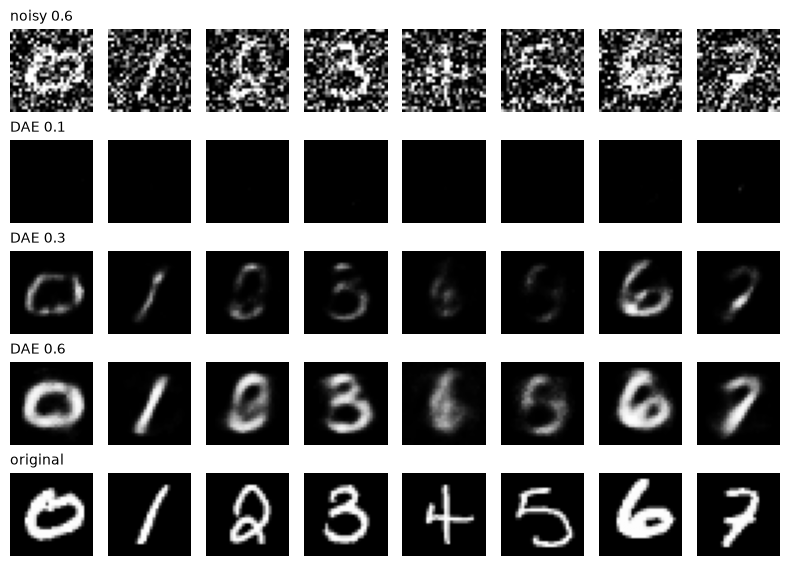

[6-2]
임곗값   값      TP  FP  FN  TN  정밀도  재현율   F1
  80%  0.0259  180 236   0 744   0.433   1.000  0.604
  90%  0.0318  179 116   1 864   0.607   0.994  0.754
  95%  0.0370  175  63   5 917   0.735   0.972  0.837
  99%  0.0458  160  21  20 959   0.884   0.889  0.886
숫자별 이상 판정: 0:6% 1:100% 2:100% 3:100% 4:100% 5:97% 6:89% 7:100% 8:99% 9:100%


In [45]:
# ==================== [6-1]
print("[6-1]")  # 어느 섹션의 출력인지


# 노이즈 세기 3단계 DAE (0.3은 1-2 모델 그대로 · 모두 같은 조건)
daes = {0.3: dae}                                # 0.3은 1-2 모델 재사용
for s in [0.1, 0.6]:                             # 새로 학습할 세기
    print(f"DAE {s} 학습")                       # 어느 학습인지
    torch.manual_seed(0)                         # 같은 출발점
    daes[s] = train(AutoEncoder(32).to(device),  # 세기만 다름
                    loss_fn=lambda m, x, s=s: dae_loss(m, x, s))


# 학습 세기 × 평가 세기 MSE 표 (+ 깨끗한 입력)
tests = {"0.1": noisy_eval(0.1), "0.3": Xn, "0.6": noisy_eval(0.6),         # 평가 시험지 네 가지
         "clean": Xte}
print("평가 →      " + "  ".join(f"{k:>6}" for k in tests))                 # 표 머리
print("노이즈 그대로 " + "  ".join(f"{mse(v):.4f}" for v in tests.values()))  # 기준선 줄
for s in [0.1, 0.3, 0.6]:                                                   # 학습 세기마다
    row = "  ".join(f"{mse(run(daes[s], v)):.4f}" for v in tests.values())  # 네 시험지 점수
    print(f"DAE {s} 학습  {row}")                                           # 표 한 줄
show([("noisy 0.6", tests["0.6"])]                                          # 가장 센 노이즈로 그림
     + [(f"DAE {s}", run(daes[s], tests["0.6"])) for s in [0.1, 0.3, 0.6]]
     + [("original", Xte)])


# ==================== [6-2]
print("[6-2]")  # 어느 섹션의 출력인지


# 이상 탐지 결과표: 임곗값 네 가지 (5-2와 같은 시험 세트)
print("임곗값   값      TP  FP  FN  TN  정밀도  재현율   F1")      # 표 머리
for q in [0.80, 0.90, 0.95, 0.99]:                                 # 임곗값 네 가지
    th, tp, fp, fn, tn = judge(q)                                  # 5-2 함수
    f1 = f1_score(y_true, (e_test > th).int())                     # 정밀도 · 재현율 조화 평균
    print(f"{q:>5.0%}  {th:.4f}  {tp:>3} {fp:>3} {fn:>3} {tn:>3}"  # 표 한 줄
          f"   {tp / (tp + fp):.3f}   {tp / (tp + fn):.3f}  {f1:.3f}")


# 임곗값 95%에서 숫자별 '이상' 판정 비율 (평가 이미지 전체)
th95 = judge(0.95)[0]                                                             # 95% 임곗값
rate = [(err_te[yte == k] > th95).float().mean().item() for k in range(10)]       # 숫자별 판정 비율
print("숫자별 이상 판정:", " ".join(f"{k}:{r:.0%}" for k, r in enumerate(rate)))  # 0은 낮아야